# Notebook 04 – Model Evaluation and Research Findings

Evaluate the out-of-fold predictions from notebook 03 and answer the research question: how much does random point-level validation overstate model accuracy compared with curve-held-out and article-held-out validation, and does a Basquin anchor reduce the loss on unseen articles?

**Hypotheses (fixed before the analysis)**
- **H1:** for the best direct learner, the article-held-out RMSE of log10(Nf) is at least 1.5 times the random-split RMSE (an expectation, not a pass mark).
- **H2:** the Basquin-anchored residual model has a smaller inflation factor *and* a lower article-held-out RMSE than LightGBM.

Errors are in log10 cycles: ±0.3 is a factor of 2 in life and ±0.5 a factor of about 3. No model is trained in this notebook.

## 1. Setup and loading

Import the libraries, set the analysis settings and load the dataset, folds and primary predictions.

In [1]:
import sys
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import data_utils as du
import feature_utils as fu
import model_utils as mu
import evaluation_utils as eu

eu.set_plot_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PRED_DIR = PROJECT_ROOT / "results" / "predictions"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
AUDIT_DIR = PROJECT_ROOT / "results" / "audit"
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)

SEED = 42
SCHEMES = ["A_random", "B_curve", "C_article"]
MODELS = mu.MODEL_ORDER
DIRECT_LEARNERS = ["Ridge", "RandomForest", "LightGBM"]     # models that predict log10(N) straight from the features
MAIN_MODEL = "LightGBM"                                      # the main direct learner named in the methodology
N_BOOT = 1000
FEATURES = fu.FEATURES_TIER0

data = pd.read_csv(PROCESSED_DIR / "modelling_dataset.csv")
folds = pd.read_csv(PROCESSED_DIR / "folds.csv")
primary = pd.read_csv(PRED_DIR / "oof_predictions_primary.csv")
extra_seeds = pd.read_csv(PRED_DIR / "oof_predictions_extra_seeds.csv")

print(f"Modelling dataset : {len(data):,} points, {data['curve_id'].nunique():,} curves, {data['article_id'].nunique()} articles")
print(f"Primary predictions: {len(primary):,} rows | schemes {sorted(primary['scheme'].unique())} | models {list(primary['model'].unique())}")

Modelling dataset : 12,666 points, 1,533 curves, 440 articles
Primary predictions: 189,990 rows | schemes ['A_random', 'B_curve', 'C_article'] | models ['Basquin', 'Ridge', 'RandomForest', 'LightGBM', 'BasquinResidual']


## 2. Integrity checks

Check the saved predictions before computing any metric: one prediction per row, correct target and fold, and no curve (B) or article (C) split across folds.

In [2]:
checks = {}

counts = primary.groupby(["scheme", "model"])["row_id"].agg(["size", "nunique"])
checks["one prediction per row, scheme and model"] = bool((counts["size"] == len(data)).all() and (counts["nunique"] == len(data)).all())

truth = primary.merge(data[["row_id", "log_N"]], on="row_id")
checks["stored truth equals the dataset target"] = bool(np.allclose(truth["y_true"], truth["log_N"]))

saved_folds = folds[folds["seed"] == SEED].set_index(["scheme", "row_id"])["fold"]
stored = primary.drop_duplicates(["scheme", "row_id"]).set_index(["scheme", "row_id"])["fold"]
checks["stored folds equal the saved fold table"] = bool((stored == saved_folds.reindex(stored.index)).all())

one_model = primary[primary["model"] == MODELS[0]]
checks["B: every curve sits in exactly one fold"] = bool(one_model[one_model["scheme"] == "B_curve"].groupby("curve_id")["fold"].nunique().max() == 1)
checks["C: every article sits in exactly one fold"] = bool(one_model[one_model["scheme"] == "C_article"].groupby("article_id")["fold"].nunique().max() == 1)
checks["C: every curve sits in exactly one fold"] = bool(one_model[one_model["scheme"] == "C_article"].groupby("curve_id")["fold"].nunique().max() == 1)
checks["A: curves are spread over folds (random split, as intended)"] = bool(one_model[one_model["scheme"] == "A_random"].groupby("curve_id")["fold"].nunique().median() > 1)
checks["all predictions are finite"] = bool(np.isfinite(primary["y_pred"]).all())

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")
assert all(checks.values()), "An integrity check failed; the results below must not be used."

test_report = (METRICS_DIR / "test_report.txt").read_text(encoding="utf8")
n_tests_passed = int(re.search(r"(\d+) passed", test_report).group(1))
print(f"\nLeakage tests in notebook 03: {n_tests_passed} passed" + ("" if "failed" not in test_report else " (some failed!)"))

PASS  one prediction per row, scheme and model
PASS  stored truth equals the dataset target
PASS  stored folds equal the saved fold table
PASS  B: every curve sits in exactly one fold
PASS  C: every article sits in exactly one fold
PASS  C: every curve sits in exactly one fold
PASS  A: curves are spread over folds (random split, as intended)
PASS  all predictions are finite



Leakage tests in notebook 03: 42 passed


## 3. Metrics by model and validation scheme

Compute RMSE, MAE, R², the share of predictions within ±0.3 and ±0.5 log cycles, and the bias. A mean predictor (the training-fold average) is added as a reference.

In [3]:
# Reference: mean of the training fold, for every scheme.
baseline_parts = []
for scheme in SCHEMES:
    scheme_folds = mu.make_folds(data, scheme, SEED)
    baseline_parts.append(pd.DataFrame({
        "row_id": data["row_id"], "curve_id": data["curve_id"], "article_id": data["article_id"], "alloy": data["alloy"],
        "scheme": scheme, "seed": SEED, "fold": scheme_folds.to_numpy(), "model": "MeanPredictor",
        "y_true": data["log_N"], "y_pred": eu.mean_baseline_predictions(data, scheme_folds)}))
with_baseline = pd.concat([primary] + baseline_parts, ignore_index=True)

metrics = eu.metrics_table(with_baseline)
metrics["factor_in_life_at_rmse"] = 10 ** metrics["rmse"]
order = ["MeanPredictor"] + MODELS
metrics["model"] = pd.Categorical(metrics["model"], order, ordered=True)
metrics["scheme"] = pd.Categorical(metrics["scheme"], SCHEMES, ordered=True)
metrics = metrics.sort_values(["scheme", "model"]).reset_index(drop=True)
metrics.to_csv(METRICS_DIR / "metrics_by_model_and_scheme.csv", index=False)

display(metrics[["scheme", "model", "n", "curves", "articles", "rmse", "mae", "r2", "within_0.3", "within_0.5", "bias", "factor_in_life_at_rmse"]])

,scheme,model,n,curves,articles,rmse,mae,r2,within_0.3,within_0.5,bias,factor_in_life_at_rmse
0,A_random,MeanPredictor,12666,1533,440,0.993,0.735,-0.000,0.286,0.454,-0.000,9.843
1,A_random,Basquin,12666,1533,440,0.938,0.689,0.108,0.315,0.489,0.001,8.662
2,A_random,Ridge,12666,1533,440,0.897,0.659,0.185,0.324,0.505,0.001,7.883
3,A_random,RandomForest,12666,1533,440,0.647,0.458,0.575,0.477,0.670,0.007,4.440
4,A_random,LightGBM,12666,1533,440,0.673,0.489,0.541,0.435,0.630,0.003,4.706
5,A_random,BasquinResidual,12666,1533,440,0.667,0.484,0.548,0.444,0.639,0.003,4.650
6,B_curve,MeanPredictor,12666,1533,440,0.994,0.735,-0.001,0.286,0.452,-0.000,9.852
7,B_curve,Basquin,12666,1533,440,0.954,0.703,0.077,0.305,0.478,0.007,8.998
8,B_curve,Ridge,12666,1533,440,0.951,0.685,0.084,0.314,0.490,0.012,8.924
9,B_curve,RandomForest,12666,1533,440,0.797,0.570,0.356,0.395,0.581,-0.020,6.261


*Note:* under random validation the tree models look useful (RMSE about 0.65–0.67), but with articles held out they are close to the mean predictor (about 0.92 against 0.99).

### 3.1 Size of a single error

Percentiles of the absolute error of single predictions, with the factor in life each one corresponds to.

In [4]:
quantile_rows = []
for (model, scheme), group in with_baseline.groupby(["model", "scheme"]):
    quantile_rows.append({"model": model, "scheme": scheme, **eu.absolute_error_summary(group["y_true"], group["y_pred"])})
error_quantiles = pd.DataFrame(quantile_rows)
error_quantiles["model"] = pd.Categorical(error_quantiles["model"], order, ordered=True)
error_quantiles["scheme"] = pd.Categorical(error_quantiles["scheme"], SCHEMES, ordered=True)
error_quantiles = error_quantiles.sort_values(["scheme", "model"]).reset_index(drop=True)
error_quantiles.to_csv(METRICS_DIR / "error_quantiles.csv", index=False)
display(error_quantiles[error_quantiles["model"].isin(["MeanPredictor", "Basquin", "RandomForest", "LightGBM"])])

,model,scheme,rmse,10^rmse,median abs error,factor at median,75th percentile,factor at 75th percentile,90th percentile,factor at 90th percentile,share off by more than a factor of 10
0,MeanPredictor,A_random,0.993,9.843,0.560,3.632,0.991,9.806,1.566,36.783,0.246
1,Basquin,A_random,0.938,8.662,0.514,3.265,0.932,8.552,1.509,32.249,0.223
3,RandomForest,A_random,0.647,4.440,0.321,2.092,0.623,4.193,1.035,10.828,0.109
4,LightGBM,A_random,0.673,4.706,0.355,2.267,0.676,4.738,1.092,12.367,0.121
6,MeanPredictor,B_curve,0.994,9.852,0.559,3.626,0.991,9.800,1.567,36.877,0.247
7,Basquin,B_curve,0.954,8.998,0.526,3.354,0.951,8.939,1.543,34.902,0.229
9,RandomForest,B_curve,0.797,6.261,0.404,2.535,0.778,5.996,1.278,18.946,0.165
10,LightGBM,B_curve,0.787,6.122,0.418,2.617,0.781,6.039,1.257,18.070,0.163
12,MeanPredictor,C_article,0.994,9.862,0.561,3.640,0.994,9.873,1.569,37.075,0.248
13,Basquin,C_article,0.992,9.816,0.546,3.516,0.985,9.667,1.595,39.335,0.244


## 4. Inflation factors and their uncertainty

Inflation factor = RMSE under a grouped scheme ÷ RMSE under random validation, for the same model. 95% intervals come from 1,000 bootstrap resamples of whole articles. No model is refitted, so the intervals are conditional on the fitted models and folds.

In [5]:
boot_samples, boot_summary = eu.cluster_bootstrap_rmse(primary, n_boot=N_BOOT, seed=0)
boot_summary.to_csv(METRICS_DIR / "bootstrap_intervals.csv", index=False)

def interval_text(row):
    return f"{row['estimate']:.3f} [{row['ci_low']:.3f}, {row['ci_high']:.3f}]"

rmse_ci = boot_summary[boot_summary["quantity"] == "rmse"].assign(text=lambda t: t.apply(interval_text, axis=1)).pivot(index="model", columns="scheme", values="text").loc[MODELS, SCHEMES]
inflation_ci = boot_summary[boot_summary["quantity"] == "inflation_vs_random"].assign(text=lambda t: t.apply(interval_text, axis=1)).pivot(index="model", columns="scheme", values="text").loc[MODELS, ["B_curve", "C_article"]]

print("RMSE of log10(Nf) with 95% article-bootstrap interval:")
display(rmse_ci.rename(columns=eu.SCHEME_LABELS))
print("Inflation factor against random validation, with 95% interval:")
display(inflation_ci.rename(columns={"B_curve": "curve held out / random", "C_article": "article held out / random"}))

inflation = eu.inflation_table(metrics[metrics["model"] != "MeanPredictor"].astype({"model": str, "scheme": str})).loc[MODELS]
inflation.to_csv(METRICS_DIR / "inflation_factors.csv")

RMSE of log10(Nf) with 95% article-bootstrap interval:


scheme,A: random points,B: curve held out,C: article held out
model,,,
Basquin,"0.938 [0.878, 1.000]","0.954 [0.892, 1.017]","0.992 [0.925, 1.062]"
Ridge,"0.897 [0.841, 0.952]","0.951 [0.873, 1.042]","0.970 [0.904, 1.036]"
RandomForest,"0.647 [0.608, 0.687]","0.797 [0.746, 0.851]","0.927 [0.866, 0.983]"
LightGBM,"0.673 [0.632, 0.713]","0.787 [0.737, 0.840]","0.924 [0.863, 0.981]"
BasquinResidual,"0.667 [0.626, 0.707]","0.788 [0.738, 0.841]","0.940 [0.879, 0.999]"


Inflation factor against random validation, with 95% interval:


scheme,curve held out / random,article held out / random
model,,
Basquin,"1.018 [1.010, 1.026]","1.058 [1.032, 1.090]"
Ridge,"1.060 [1.018, 1.144]","1.081 [1.050, 1.119]"
RandomForest,"1.231 [1.199, 1.267]","1.432 [1.362, 1.502]"
LightGBM,"1.170 [1.143, 1.200]","1.373 [1.311, 1.445]"
BasquinResidual,"1.181 [1.154, 1.211]","1.408 [1.336, 1.483]"


Check whether the inflation remains when every article is weighted equally instead of every point.

In [6]:
weighting_rows = []
for model in MODELS:
    row = {"model": mu.MODEL_LABELS[model]}
    for scheme in SCHEMES:
        sub = primary[(primary["model"] == model) & (primary["scheme"] == scheme)]
        squared = (sub["y_pred"] - sub["y_true"]) ** 2
        row[f"{scheme}, point-weighted"] = float(np.sqrt(squared.mean()))
        row[f"{scheme}, article-weighted"] = float(np.sqrt(squared.groupby(sub["article_id"]).mean().mean()))
    row["inflation C/A, point-weighted"] = row["C_article, point-weighted"] / row["A_random, point-weighted"]
    row["inflation C/A, article-weighted"] = row["C_article, article-weighted"] / row["A_random, article-weighted"]
    weighting_rows.append(row)
article_weighted = pd.DataFrame(weighting_rows).set_index("model")
article_weighted.to_csv(METRICS_DIR / "inflation_article_weighted.csv")
display(article_weighted[["A_random, point-weighted", "A_random, article-weighted", "C_article, point-weighted", "C_article, article-weighted",
                          "inflation C/A, point-weighted", "inflation C/A, article-weighted"]])

,"A_random, point-weighted","A_random, article-weighted","C_article, point-weighted","C_article, article-weighted","inflation C/A, point-weighted","inflation C/A, article-weighted"
model,,,,,,
Basquin (per alloy),0.938,0.982,0.992,1.035,1.058,1.054
Ridge,0.897,0.954,0.970,1.042,1.081,1.092
Random Forest,0.647,0.692,0.927,0.949,1.432,1.372
LightGBM,0.673,0.720,0.924,0.959,1.373,1.331
Basquin-anchored residual,0.667,0.715,0.940,0.988,1.408,1.382


Plot the RMSE by model and scheme, and the inflation factors with their 95% intervals.

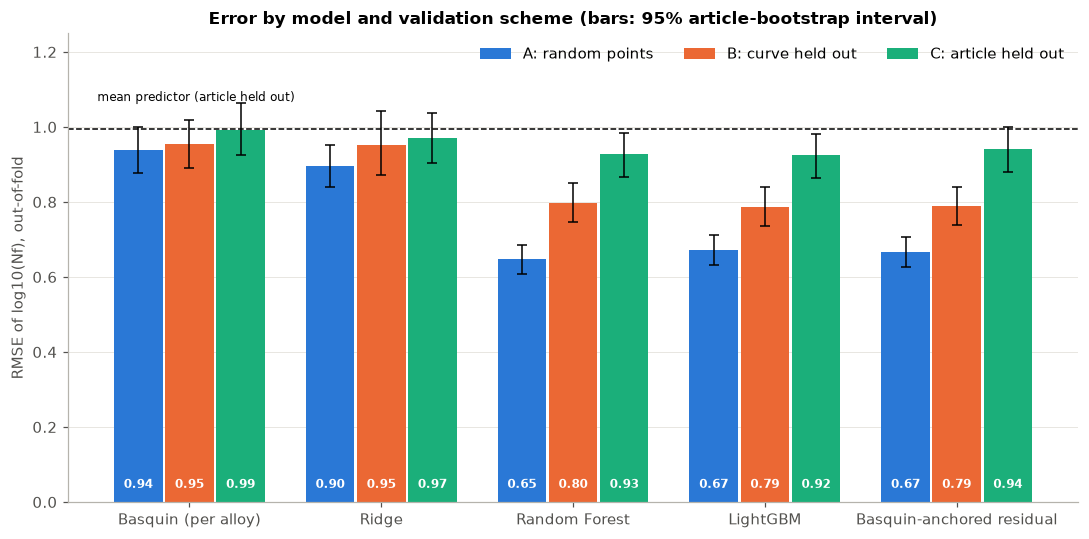

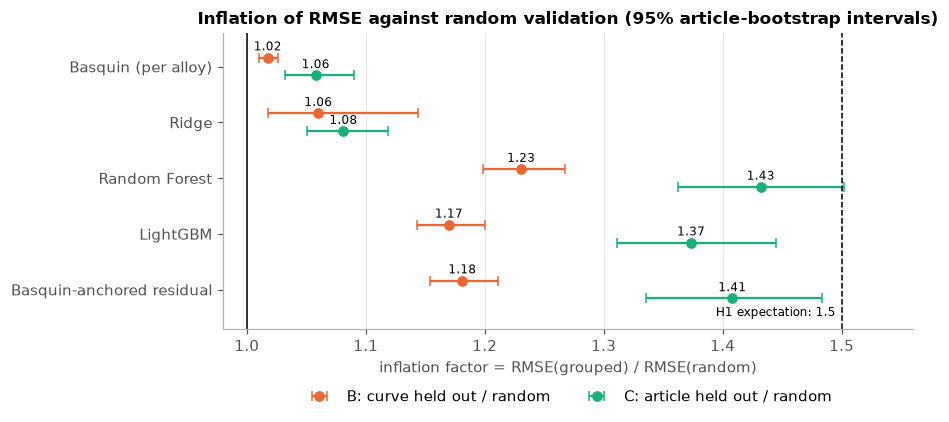

In [7]:
fig = eu.plot_rmse_by_model_and_scheme(metrics[metrics["model"] != "MeanPredictor"].astype({"model": str, "scheme": str}), MODELS, SCHEMES, mu.MODEL_LABELS, ci=boot_summary)
ax = fig.axes[0]
mean_c = float(metrics[(metrics["model"] == "MeanPredictor") & (metrics["scheme"] == "C_article")]["rmse"].iloc[0])
ax.axhline(mean_c, color="black", lw=1, ls="--")
ax.text(-0.48, mean_c + 0.075, "mean predictor (article held out)", ha="left", fontsize=8)
ax.set_ylim(0, 1.25)
ax.legend(loc="upper right", ncol=3, frameon=False)
eu.save_figure(fig, FIG_DIR / "04_rmse_by_model_and_scheme.png")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4))
inf = boot_summary[boot_summary["quantity"] == "inflation_vs_random"]
y_positions = np.arange(len(MODELS))[::-1]
for k, scheme in enumerate(["B_curve", "C_article"]):
    rows = inf[inf["scheme"] == scheme].set_index("model").loc[MODELS]
    offset = 0.16 if scheme == "B_curve" else -0.16
    ax.errorbar(rows["estimate"], y_positions + offset, xerr=[rows["estimate"] - rows["ci_low"], rows["ci_high"] - rows["estimate"]],
                fmt="o", color=eu.SCHEME_COLORS[scheme], capsize=3, label=eu.SCHEME_LABELS[scheme] + " / random")
    for x, y in zip(rows["estimate"], y_positions + offset):
        ax.text(x, y + 0.13, f"{x:.2f}", ha="center", fontsize=8)
ax.axvline(1.0, color="black", lw=1)
ax.axvline(1.5, color="black", lw=1, ls="--")
ax.text(1.495, -0.42, "H1 expectation: 1.5", fontsize=8, va="center", ha="right")
ax.set_yticks(y_positions)
ax.set_yticklabels([mu.MODEL_LABELS[m] for m in MODELS])
ax.set(xlabel="inflation factor = RMSE(grouped) / RMSE(random)", title="Inflation of RMSE against random validation (95% article-bootstrap intervals)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0.98, 1.56)
ax.set_ylim(-0.7, len(MODELS) - 0.4)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "04_inflation_factors.png")
plt.show()

*Note:* the flexible models show an inflation of about 1.4 (LightGBM 1.37, Random Forest 1.43), with intervals well above 1.0. The simple models barely change (1.06–1.08) because they are poor everywhere.

## 5. Hypotheses H1 and H2

Test the hypotheses with the rules fixed in advance. H1 is supported if the inflation C/A is at least 1.5; H2 needs both a smaller inflation and a lower article-held-out RMSE than LightGBM. The learned models are also compared with the Basquin baseline.

In [8]:
rmse = metrics.astype({"model": str, "scheme": str}).pivot(index="model", columns="scheme", values="rmse")
inf_c = boot_summary[(boot_summary["quantity"] == "inflation_vs_random") & (boot_summary["scheme"] == "C_article")].set_index("model")

# ---- H1 ----
best_random = rmse.loc[DIRECT_LEARNERS, "A_random"].idxmin()
best_article = rmse.loc[DIRECT_LEARNERS, "C_article"].idxmin()
def h1_status(model):
    est, low, high = inf_c.loc[model, ["estimate", "ci_low", "ci_high"]]
    if est >= 1.5:
        return "supported"
    return "not supported, but 1.5 is within the 95% interval" if high >= 1.5 else "not supported"
h1_rows = []
for label, model in [("lowest random-split RMSE", best_random), ("main direct learner", MAIN_MODEL), ("lowest article-held-out RMSE", best_article)]:
    h1_rows.append({"reading of 'best direct learner'": label, "model": model, "RMSE random": rmse.loc[model, "A_random"], "RMSE article held out": rmse.loc[model, "C_article"],
                    "inflation C/A": inf_c.loc[model, "estimate"], "95% low": inf_c.loc[model, "ci_low"], "95% high": inf_c.loc[model, "ci_high"],
                    "share of resamples with inflation >= 1.5": float(((boot_samples[(model, "C_article")] / boot_samples[(model, "A_random")]) >= 1.5).mean()),
                    "H1": h1_status(model)})
h1_table = pd.DataFrame(h1_rows)
display(h1_table)

# ---- H2 ----
res, gbm = "BasquinResidual", "LightGBM"
ratio_res = boot_samples[(res, "C_article")] / boot_samples[(res, "A_random")]
ratio_gbm = boot_samples[(gbm, "C_article")] / boot_samples[(gbm, "A_random")]
rmse_diff = eu.bootstrap_difference(boot_samples, (res, "C_article"), (gbm, "C_article"))
h2 = {
    "inflation C/A, residual model": float(inf_c.loc[res, "estimate"]),
    "inflation C/A, LightGBM": float(inf_c.loc[gbm, "estimate"]),
    "share of resamples where residual inflation is smaller": float((ratio_res < ratio_gbm).mean()),
    "RMSE article held out, residual model": float(rmse.loc[res, "C_article"]),
    "RMSE article held out, LightGBM": float(rmse.loc[gbm, "C_article"]),
    "RMSE difference residual - LightGBM (article held out)": float(rmse.loc[res, "C_article"] - rmse.loc[gbm, "C_article"]),
    "95% low of the difference": rmse_diff["ci_low"],
    "95% high of the difference": rmse_diff["ci_high"],
    "share of resamples where residual RMSE is lower": rmse_diff["share_of_resamples_first_is_lower"],
}
part_inflation = h2["inflation C/A, residual model"] < h2["inflation C/A, LightGBM"]
part_rmse = h2["RMSE article held out, residual model"] < h2["RMSE article held out, LightGBM"]
h2_verdict = "supported" if (part_inflation and part_rmse) else ("partly supported" if (part_inflation or part_rmse) else "not supported")
display(pd.Series(h2, name="value").to_frame())
print(f"H2 part 1 (smaller inflation): {part_inflation} | part 2 (lower article-held-out RMSE): {part_rmse}  ->  H2 {h2_verdict}")

# Does any learned model beat the Basquin baseline on unseen articles, beyond bootstrap noise?
versus_basquin = pd.DataFrame({model: eu.bootstrap_difference(boot_samples, (model, "C_article"), ("Basquin", "C_article")) for model in MODELS if model != "Basquin"}).T
versus_basquin.index.name = "model (minus Basquin, article held out)"
display(versus_basquin)

h1_verdict = h1_table.loc[0, "H1"]
h1_evidence = (f"{mu.MODEL_LABELS[best_random]} (lowest random-split RMSE): {rmse.loc[best_random, 'A_random']:.3f} random, {rmse.loc[best_random, 'C_article']:.3f} article held out, "
               f"inflation {inf_c.loc[best_random, 'estimate']:.2f} (95% interval {inf_c.loc[best_random, 'ci_low']:.2f} to {inf_c.loc[best_random, 'ci_high']:.2f}). "
               f"{mu.MODEL_LABELS[MAIN_MODEL]}: inflation {inf_c.loc[MAIN_MODEL, 'estimate']:.2f} ({inf_c.loc[MAIN_MODEL, 'ci_low']:.2f} to {inf_c.loc[MAIN_MODEL, 'ci_high']:.2f})")
h2_evidence = (f"Inflation {h2['inflation C/A, residual model']:.2f} against {h2['inflation C/A, LightGBM']:.2f} for LightGBM; article-held-out RMSE {h2['RMSE article held out, residual model']:.3f} against "
               f"{h2['RMSE article held out, LightGBM']:.3f} (difference {h2['RMSE difference residual - LightGBM (article held out)']:+.3f}, 95% interval {rmse_diff['ci_low']:+.3f} to {rmse_diff['ci_high']:+.3f})")
du.save_json({"H1": h1_rows, "H2": h2, "H2_verdict": h2_verdict}, METRICS_DIR / "hypothesis_tests.json")

,reading of 'best direct learner',model,RMSE random,RMSE article held out,inflation C/A,95% low,95% high,share of resamples with inflation >= 1.5,H1
0,lowest random-split RMSE,RandomForest,0.647,0.927,1.432,1.362,1.502,0.031,"not supported, but 1.5 is within the 95% interval"
1,main direct learner,LightGBM,0.673,0.924,1.373,1.311,1.445,0.000,not supported
2,lowest article-held-out RMSE,LightGBM,0.673,0.924,1.373,1.311,1.445,0.000,not supported


,value
"inflation C/A, residual model",1.408
"inflation C/A, LightGBM",1.373
share of resamples where residual inflation is smaller,0.028
"RMSE article held out, residual model",0.940
"RMSE article held out, LightGBM",0.924
RMSE difference residual - LightGBM (article held out),0.016
95% low of the difference,-0.007
95% high of the difference,0.038
share of resamples where residual RMSE is lower,0.080


H2 part 1 (smaller inflation): False | part 2 (lower article-held-out RMSE): False  ->  H2 not supported


,bootstrap_mean_difference,ci_low,ci_high,share_of_resamples_first_is_lower
"model (minus Basquin, article held out)",,,,
Ridge,-0.022,-0.063,0.021,0.865
RandomForest,-0.065,-0.113,-0.016,0.995
LightGBM,-0.068,-0.122,-0.013,0.993
BasquinResidual,-0.053,-0.099,-0.005,0.985


*Note:* H1 is not supported at the stated 1.5 threshold (inflation 1.37–1.43), although random validation still overstates accuracy substantially. H2 is not supported: the residual model has a larger inflation and a slightly higher article-held-out RMSE than LightGBM.

## 6. Predicted against actual life

Plot out-of-fold predictions against measured life for LightGBM and the residual model, and the distribution of LightGBM's errors under each scheme.

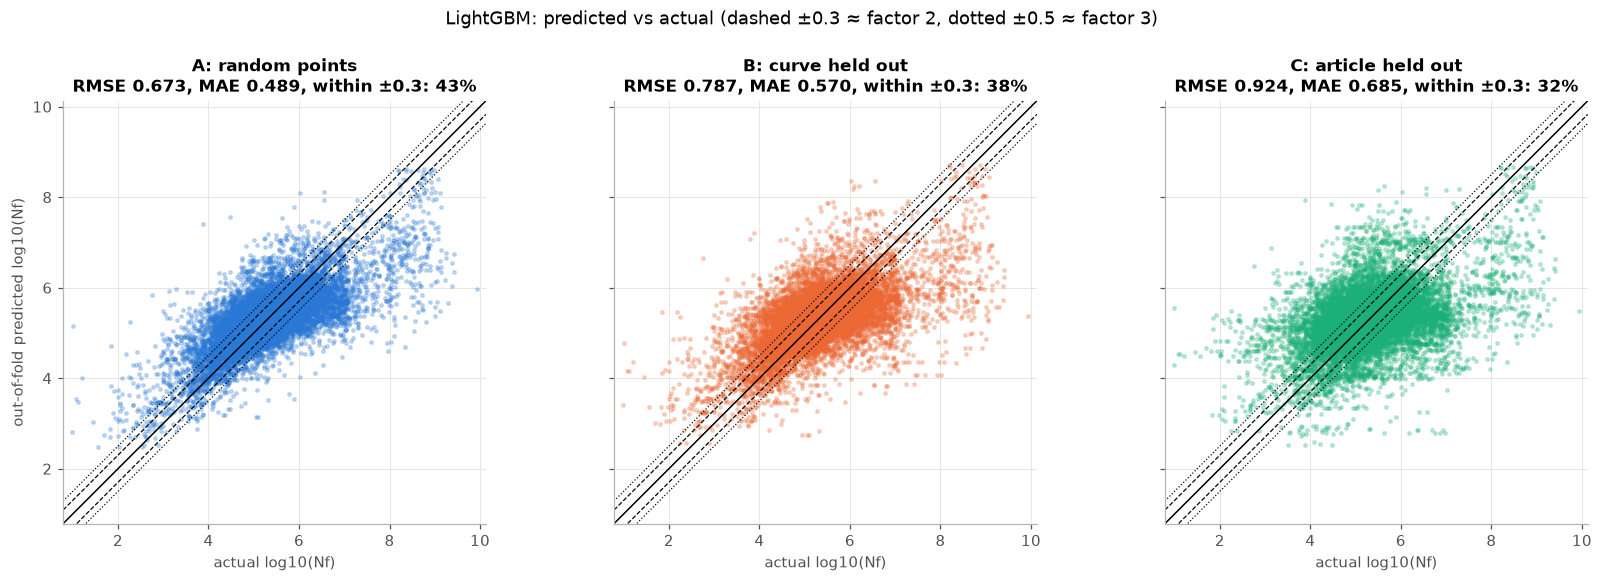

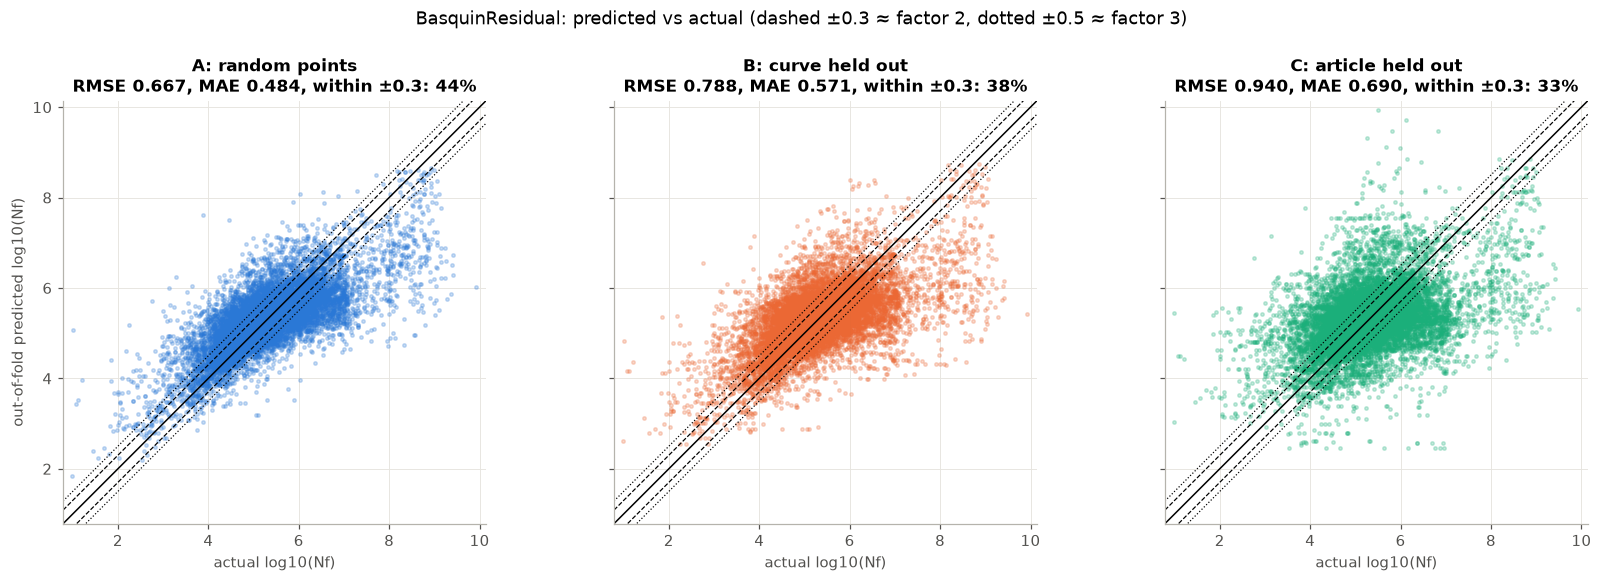

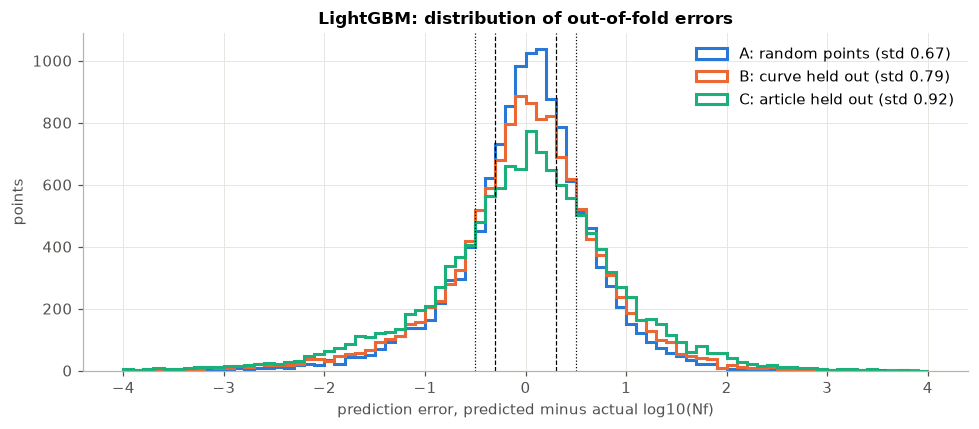

In [9]:
fig = eu.plot_predicted_vs_actual(primary, MAIN_MODEL, SCHEMES)
eu.save_figure(fig, FIG_DIR / "04_predicted_vs_actual_LightGBM.png")
plt.show()

fig = eu.plot_predicted_vs_actual(primary, "BasquinResidual", SCHEMES)
eu.save_figure(fig, FIG_DIR / "04_predicted_vs_actual_BasquinResidual.png")
plt.show()

# Residual distributions (prediction minus truth) for the main learner.
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(-4, 4, 81)
for scheme in SCHEMES:
    sub = primary[(primary["model"] == MAIN_MODEL) & (primary["scheme"] == scheme)]
    error = sub["y_pred"] - sub["y_true"]
    ax.hist(error, bins=bins, histtype="step", lw=2, color=eu.SCHEME_COLORS[scheme], label=f"{eu.SCHEME_LABELS[scheme]} (std {error.std():.2f})")
for band in (0.3, 0.5):
    ax.axvline(band, color="black", lw=0.8, ls="--" if band == 0.3 else ":")
    ax.axvline(-band, color="black", lw=0.8, ls="--" if band == 0.3 else ":")
ax.set(xlabel="prediction error, predicted minus actual log10(Nf)", ylabel="points", title=f"{mu.MODEL_LABELS[MAIN_MODEL]}: distribution of out-of-fold errors")
ax.legend()
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "04_residual_histograms_LightGBM.png")
plt.show()

### 6.1 Calibration

Check how long specimens actually live for a given predicted life, using the calibration slope and the bias in each predicted-life bin. The table binned by *true* life and a synthetic control are kept for comparison, because binning by the outcome is misleading.

(a) Mean error binned by TRUE life (version 2 table):


points     bias               rmse          
scheme     C_article A_random C_article A_random C_article
regime                                                    
N < 1e4          802    0.718     1.189    0.970     1.475
1e4 to 1e5      3996    0.370     0.456    0.565     0.748
1e5 to 1e6      5322   -0.011    -0.050    0.420     0.597
1e6 to 1e7      1943   -0.575    -0.847    0.778     1.122
N > 1e7          603   -1.401    -1.794    1.619     2.031

Control, a perfectly calibrated synthetic predictor with the same RMSE, mean error binned by TRUE life: {'below 1e4': 1.54, '1e4 to 1e5': 0.65, '1e5 to 1e6': -0.14, '1e6 to 1e7': -0.94, 'above 1e7': -1.82}


(b) Calibration slope (true life regressed on predicted life):


scheme,A_random,B_curve,C_article
model,,,
Basquin,0.926,0.795,0.508
Ridge,0.984,0.657,0.598
RandomForest,1.011,0.843,0.627
LightGBM,1.064,0.900,0.636
BasquinResidual,1.055,0.884,0.597


SD of the predictions (the SD of the true lives is 0.993):


scheme,A_random,B_curve,C_article
model,,,
Basquin,0.354,0.358,0.395
Ridge,0.434,0.513,0.488
RandomForest,0.745,0.716,0.707
LightGBM,0.688,0.677,0.699
BasquinResidual,0.698,0.689,0.729


(c) Mean error (predicted minus true log10 Nf) binned by PREDICTED life, LightGBM:


points                        bias                  
scheme             A_random  B_curve C_article A_random B_curve C_article
predicted-life bin                                                       
below 1e4           412.000  409.000   368.000    0.112  -0.103    -0.615
1e4 to 1e5         3008.000 3166.000  3363.000    0.057  -0.081    -0.261
1e5 to 1e6         7742.000 7618.000  7463.000   -0.015  -0.005     0.026
1e6 to 1e7         1277.000 1265.000  1169.000   -0.030   0.109     0.437
above 1e7           227.000  208.000   303.000   -0.143   0.322     0.611

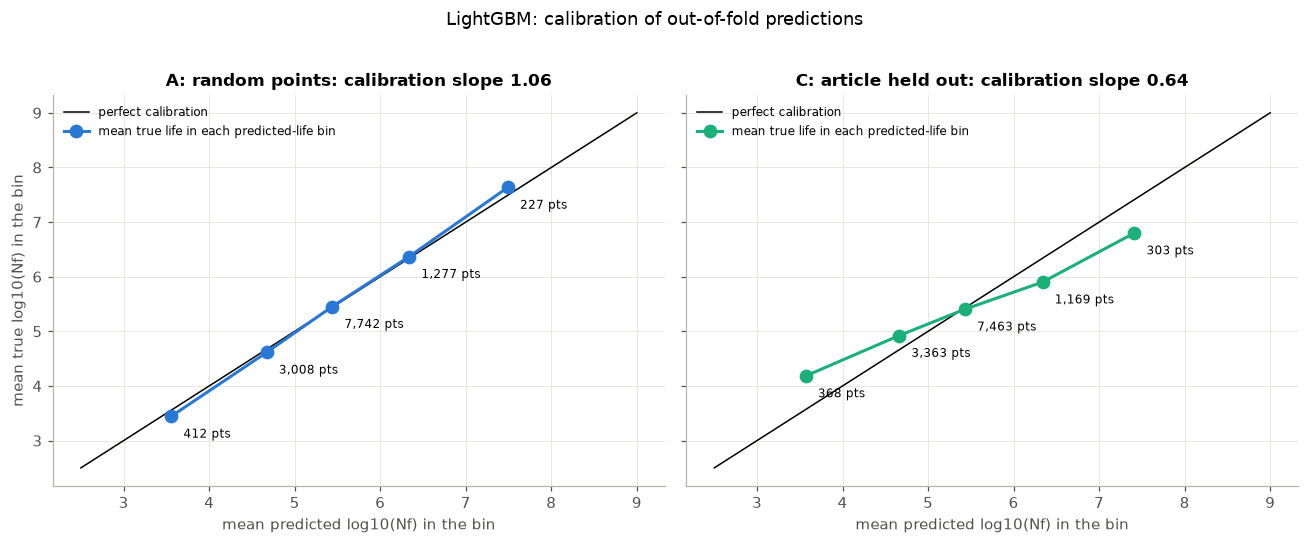

In [10]:
LIFE_BINS = [-np.inf, 4, 5, 6, 7, np.inf]
LIFE_LABELS = ["below 1e4", "1e4 to 1e5", "1e5 to 1e6", "1e6 to 1e7", "above 1e7"]

# (a) Version 2 table, binned by TRUE life: kept for comparison; read it with the control below.
main_c = primary[(primary["model"] == MAIN_MODEL)].copy()
main_c["regime"] = pd.cut(10 ** main_c["y_true"], bins=[0, 1e4, 1e5, 1e6, 1e7, np.inf], labels=["N < 1e4", "1e4 to 1e5", "1e5 to 1e6", "1e6 to 1e7", "N > 1e7"])
main_c["error"] = main_c["y_pred"] - main_c["y_true"]
regime_table = main_c.groupby(["regime", "scheme"], observed=True)["error"].agg(points="size", bias="mean", rmse=lambda e: float(np.sqrt(np.mean(e ** 2)))).unstack("scheme")
regime_table.to_csv(METRICS_DIR / "error_by_life_regime_LightGBM.csv")
print("(a) Mean error binned by TRUE life (version 2 table):")
display(regime_table[[("points", "C_article"), ("bias", "A_random"), ("bias", "C_article"), ("rmse", "A_random"), ("rmse", "C_article")]])

# Control: a perfectly calibrated predictor with the same error variance, binned by TRUE life.
lgb_c = primary[(primary["model"] == MAIN_MODEL) & (primary["scheme"] == "C_article")]
y = lgb_c["y_true"].to_numpy()
error_sd = float(np.sqrt(np.mean((lgb_c["y_pred"] - lgb_c["y_true"]) ** 2)))
rng = np.random.default_rng(0)
calibrated_prediction = y.mean() + np.sqrt(max(np.var(y) - error_sd ** 2, 0.0)) * rng.standard_normal(len(y))
synthetic_truth = calibrated_prediction + rng.normal(0.0, error_sd, len(y))
control = pd.Series(calibrated_prediction - synthetic_truth).groupby(pd.cut(synthetic_truth, LIFE_BINS, labels=LIFE_LABELS), observed=True).mean()
print("Control, a perfectly calibrated synthetic predictor with the same RMSE, mean error binned by TRUE life:", control.round(2).to_dict())

# (b) Calibration slopes: regress the true life on the predicted life.
slope_rows = []
for model in MODELS:
    for scheme in SCHEMES:
        sub = primary[(primary["model"] == model) & (primary["scheme"] == scheme)]
        slope, intercept = np.polyfit(sub["y_pred"], sub["y_true"], 1)
        slope_rows.append({"model": model, "scheme": scheme, "calibration slope": float(slope), "intercept": float(intercept),
                           "correlation": float(np.corrcoef(sub["y_pred"], sub["y_true"])[0, 1]),
                           "SD of predictions": float(sub["y_pred"].std()), "SD of true lives": float(sub["y_true"].std())})
calibration_slopes = pd.DataFrame(slope_rows)
calibration_slopes.to_csv(METRICS_DIR / "calibration_slopes.csv", index=False)
print("(b) Calibration slope (true life regressed on predicted life):")
display(calibration_slopes.pivot(index="model", columns="scheme", values="calibration slope").loc[MODELS, SCHEMES])
print("SD of the predictions (the SD of the true lives is 0.993):")
display(calibration_slopes.pivot(index="model", columns="scheme", values="SD of predictions").loc[MODELS, SCHEMES])

# (c) Bias binned by PREDICTED life.
cal = primary[primary["model"].isin(["RandomForest", MAIN_MODEL, "BasquinResidual"])].copy()
cal["predicted-life bin"] = pd.cut(cal["y_pred"], LIFE_BINS, labels=LIFE_LABELS)
cal["error"] = cal["y_pred"] - cal["y_true"]
calibration_bins = (cal.groupby(["model", "scheme", "predicted-life bin"], observed=True)
                    .agg(points=("error", "size"), articles=("article_id", "nunique"), mean_predicted=("y_pred", "mean"),
                         mean_true=("y_true", "mean"), bias=("error", "mean")).reset_index())
calibration_bins.to_csv(METRICS_DIR / "calibration_by_predicted_life.csv", index=False)
print("(c) Mean error (predicted minus true log10 Nf) binned by PREDICTED life, LightGBM:")
display(calibration_bins[calibration_bins["model"] == MAIN_MODEL].pivot(index="predicted-life bin", columns="scheme", values=["points", "bias"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, scheme in zip(axes, ["A_random", "C_article"]):
    sub = calibration_bins[(calibration_bins["model"] == MAIN_MODEL) & (calibration_bins["scheme"] == scheme)]
    slope = calibration_slopes[(calibration_slopes["model"] == MAIN_MODEL) & (calibration_slopes["scheme"] == scheme)]["calibration slope"].iloc[0]
    ax.plot([2.5, 9], [2.5, 9], color="black", lw=1, label="perfect calibration")
    ax.plot(sub["mean_predicted"], sub["mean_true"], marker="o", ms=8, lw=2, color=eu.SCHEME_COLORS[scheme], label="mean true life in each predicted-life bin")
    for _, r in sub.iterrows():
        ax.annotate(f"{int(r['points']):,} pts", (r["mean_predicted"], r["mean_true"]), textcoords="offset points", xytext=(8, -14), fontsize=8)
    ax.set(title=f"{eu.SCHEME_LABELS[scheme]}: calibration slope {slope:.2f}", xlabel="mean predicted log10(Nf) in the bin")
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("mean true log10(Nf) in the bin")
fig.suptitle(f"{mu.MODEL_LABELS[MAIN_MODEL]}: calibration of out-of-fold predictions", y=1.02)
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "04_calibration_LightGBM.png")
plt.show()

*Note:* the predictions are well calibrated under random validation (slope about 1.06) but too spread out for unseen articles (slope 0.64). Long predicted lives (above 10⁷ cycles) are non-conservative.

## 7. Error per article

Compute the mean absolute error of each article under each scheme and compare models article by article (Wilcoxon signed-rank test).

articles  median article MAE  75th percentile  90th percentile  articles with MAE <= 0.3 (%)  articles with MAE <= 0.5 (%)  articles with MAE > 1.0 (%)
model           scheme                                                                                                                                                            
Basquin         A_random        440               0.606            0.838            1.352                         6.364                        35.909                       16.364
                B_curve         440               0.613            0.853            1.378                         5.000                        33.636                       16.818
                C_article       440               0.622            0.875            1.439                         5.000                        33.409                       18.182
LightGBM        A_random        440               0.459            0.630            0.863                        18.182                        58.636                        7.273
                B_curve         440               0.517            0.720            1.020                        12.045                        47.500                       10.909
                C_article       440               0.582            0.831            1.274                         9.318                        37.045                       17.045
BasquinResidual A_random        440               0.446            0.631            0.846                        20.227                        59.318                        7.500
                B_curve         440               0.509            0.723            1.052                        12.273                        46.818                       10.909
                C_article       440               0.585            0.826            1.299                        10.455                        37.500                       18.636

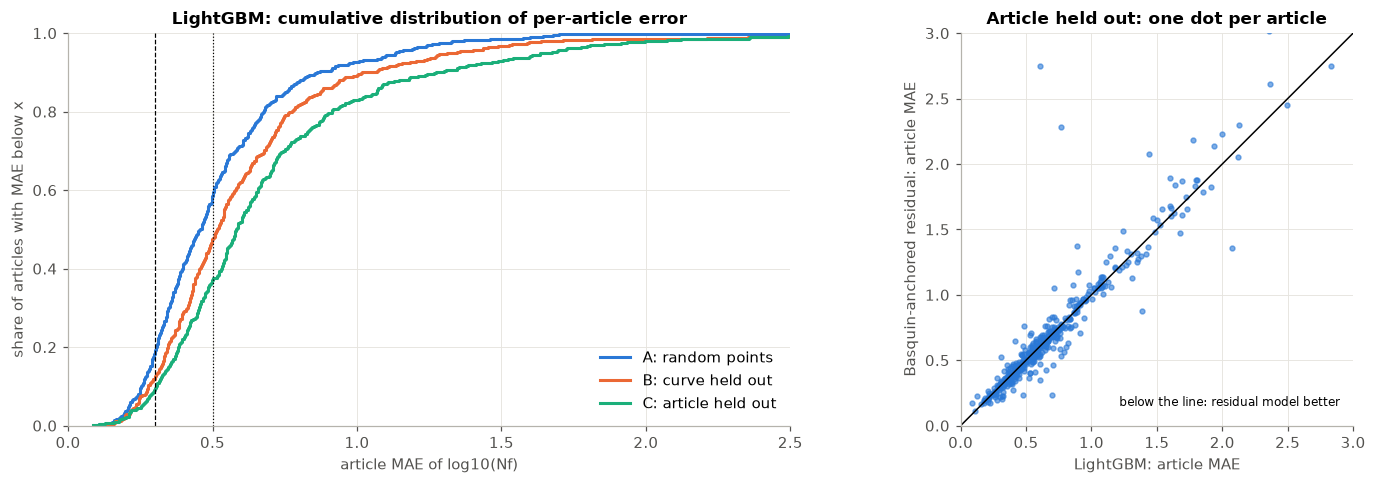

,comparison (article held out),articles,median MAE difference,articles where first is better (%),Wilcoxon p-value
0,BasquinResidual vs LightGBM,440,0.001624,48.64,0.4087
1,LightGBM vs Basquin,440,-0.03392,57.27,0.0003341
2,RandomForest vs Basquin,440,-0.04324,59.32,3.881e-05
3,Ridge vs Basquin,440,-0.02638,58.41,0.00529
4,LightGBM vs RandomForest,440,0.002935,47.5,0.3776


In [11]:
article_mae = eu.per_article_mae(primary)
article_mae.to_csv(METRICS_DIR / "per_article_mae.csv", index=False)

summary_rows = []
for model in MODELS:
    for scheme in SCHEMES:
        mae = article_mae[(article_mae["model"] == model) & (article_mae["scheme"] == scheme)]["mae"]
        summary_rows.append({"model": model, "scheme": scheme, "articles": len(mae), "median article MAE": mae.median(), "75th percentile": mae.quantile(0.75),
                             "90th percentile": mae.quantile(0.90), "articles with MAE <= 0.3 (%)": 100 * (mae <= 0.3).mean(), "articles with MAE <= 0.5 (%)": 100 * (mae <= 0.5).mean(),
                             "articles with MAE > 1.0 (%)": 100 * (mae > 1.0).mean()})
article_summary = pd.DataFrame(summary_rows)
article_summary.to_csv(METRICS_DIR / "per_article_mae_summary.csv", index=False)
display(article_summary[article_summary["model"].isin([MAIN_MODEL, "BasquinResidual", "Basquin"])].set_index(["model", "scheme"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
grid = np.linspace(0, 2.5, 251)
for scheme in SCHEMES:
    mae = np.sort(article_mae[(article_mae["model"] == MAIN_MODEL) & (article_mae["scheme"] == scheme)]["mae"].to_numpy())
    axes[0].step(mae, np.arange(1, len(mae) + 1) / len(mae), where="post", lw=2, color=eu.SCHEME_COLORS[scheme], label=eu.SCHEME_LABELS[scheme])
for band, style in ((0.3, "--"), (0.5, ":")):
    axes[0].axvline(band, color="black", lw=0.8, ls=style)
axes[0].set(xlim=(0, 2.5), ylim=(0, 1), xlabel="article MAE of log10(Nf)", ylabel="share of articles with MAE below x",
            title=f"{mu.MODEL_LABELS[MAIN_MODEL]}: cumulative distribution of per-article error")
axes[0].legend(loc="lower right")

wide = article_mae[article_mae["scheme"] == "C_article"].pivot(index="article_id", columns="model", values="mae")
axes[1].scatter(wide["LightGBM"], wide["BasquinResidual"], s=10, color=eu.PALETTE[0], alpha=0.6)
axes[1].plot([0, 3], [0, 3], color="black", lw=1)
axes[1].set(xlim=(0, 3), ylim=(0, 3), xlabel="LightGBM: article MAE", ylabel="Basquin-anchored residual: article MAE",
            title="Article held out: one dot per article")
axes[1].text(2.9, 0.15, "below the line: residual model better", ha="right", fontsize=8)
axes[1].set_aspect("equal")
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "04_per_article_error.png")
plt.show()

# Paired per-article comparisons under experiment C (Wilcoxon signed-rank test on article MAE).
pairs = [("BasquinResidual", "LightGBM"), ("LightGBM", "Basquin"), ("RandomForest", "Basquin"), ("Ridge", "Basquin"), ("LightGBM", "RandomForest")]
paired_rows = []
for first, second in pairs:
    difference = wide[first] - wide[second]
    test = stats.wilcoxon(wide[first], wide[second])
    paired_rows.append({"comparison (article held out)": f"{first} vs {second}", "articles": len(difference), "median MAE difference": difference.median(),
                        f"articles where first is better (%)": 100 * (difference < 0).mean(), "Wilcoxon p-value": test.pvalue})
paired = pd.DataFrame(paired_rows)
paired.to_csv(METRICS_DIR / "paired_per_article_comparisons.csv", index=False)
with pd.option_context("display.float_format", lambda v: f"{v:.4g}"):
    display(paired)

## 8. Error per alloy

RMSE for the five alloys with at least 15 articles and for all other alloys together. The article count is shown because it limits how far each value can be trusted.

LightGBM


,points,curves,articles,target_std,A_random,B_curve,C_article,inflation C/A
alloy,,,,,,,,
Ti-6Al-4V,4770,546,152,1.058,0.765,0.885,0.961,1.257
AlSi10Mg,1465,176,54,1.113,0.750,0.848,0.995,1.325
316L,1363,170,49,0.659,0.493,0.538,0.566,1.149
IN718,1434,170,44,0.994,0.566,0.688,0.863,1.525
17-4 PH,416,46,16,1.021,0.698,0.850,0.904,1.294
all other alloys,3218,425,145,0.915,0.590,0.722,0.983,1.665


Basquin (per alloy)


,points,curves,articles,target_std,A_random,B_curve,C_article,inflation C/A
alloy,,,,,,,,
Ti-6Al-4V,4770,546,152,1.058,1.038,1.040,1.049,1.010
AlSi10Mg,1465,176,54,1.113,1.046,1.054,1.060,1.013
316L,1363,170,49,0.659,0.583,0.587,0.586,1.005
IN718,1434,170,44,0.994,0.940,0.949,0.956,1.017
17-4 PH,416,46,16,1.021,0.940,0.987,0.977,1.040
all other alloys,3218,425,145,0.915,0.845,0.894,1.027,1.216


Basquin-anchored residual


,points,curves,articles,target_std,A_random,B_curve,C_article,inflation C/A
alloy,,,,,,,,
Ti-6Al-4V,4770,546,152,1.058,0.760,0.882,0.961,1.265
AlSi10Mg,1465,176,54,1.113,0.747,0.844,1.001,1.341
316L,1363,170,49,0.659,0.491,0.538,0.580,1.180
IN718,1434,170,44,0.994,0.564,0.698,0.850,1.507
17-4 PH,416,46,16,1.021,0.684,0.850,0.922,1.347
all other alloys,3218,425,145,0.915,0.583,0.732,1.038,1.782


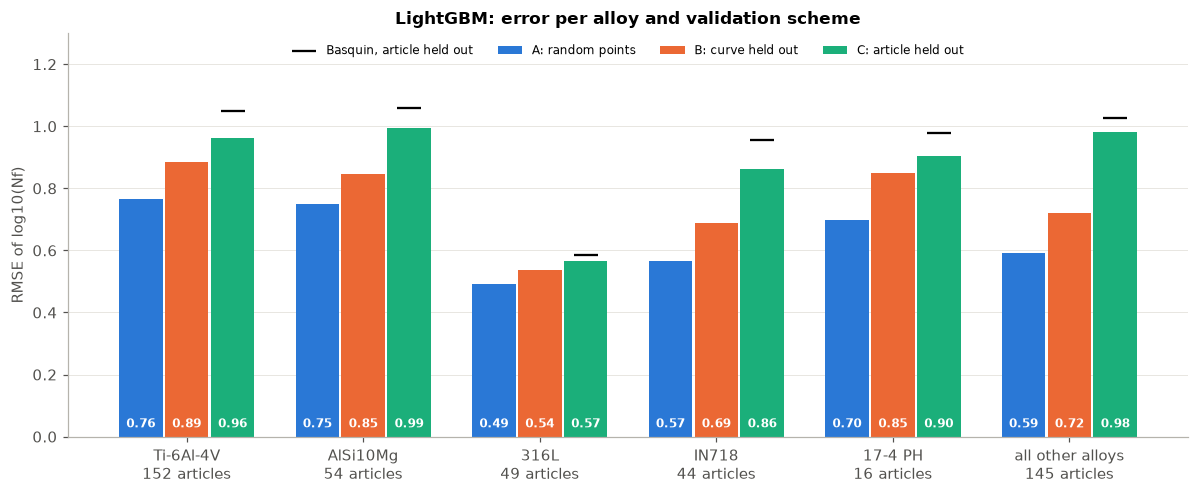

In [12]:
alloy_articles = data.groupby("alloy")["article_id"].nunique()
big_alloys = alloy_articles[alloy_articles >= 15].sort_values(ascending=False).index.tolist()
grouped = primary.assign(alloy_group=np.where(primary["alloy"].isin(big_alloys), primary["alloy"], "all other alloys"))

alloy_rows = []
for (model, scheme, group), sub in grouped.groupby(["model", "scheme", "alloy_group"]):
    m = eu.regression_metrics(sub["y_true"], sub["y_pred"])
    alloy_rows.append({"model": model, "scheme": scheme, "alloy": group, "points": m["n"], "curves": sub["curve_id"].nunique(), "articles": sub["article_id"].nunique(),
                       "rmse": m["rmse"], "mae": m["mae"], "bias": m["bias"], "target_std": float(sub["y_true"].std())})
alloy_metrics = pd.DataFrame(alloy_rows)
alloy_metrics.to_csv(METRICS_DIR / "per_alloy_metrics.csv", index=False)

alloy_order = big_alloys + ["all other alloys"]
def alloy_view(model):
    wide = alloy_metrics[alloy_metrics["model"] == model].pivot(index="alloy", columns="scheme", values="rmse").loc[alloy_order, SCHEMES]
    wide["inflation C/A"] = wide["C_article"] / wide["A_random"]
    info = alloy_metrics[(alloy_metrics["model"] == model) & (alloy_metrics["scheme"] == "C_article")].set_index("alloy").loc[alloy_order, ["points", "curves", "articles", "target_std"]]
    return info.join(wide)

print(mu.MODEL_LABELS[MAIN_MODEL]); display(alloy_view(MAIN_MODEL))
print(mu.MODEL_LABELS["Basquin"]); display(alloy_view("Basquin"))
print(mu.MODEL_LABELS["BasquinResidual"]); display(alloy_view("BasquinResidual"))

fig, ax = plt.subplots(figsize=(11, 4.6))
view = alloy_view(MAIN_MODEL)
x = np.arange(len(alloy_order))
width = 0.26
for k, scheme in enumerate(SCHEMES):
    positions = x + (k - 1) * width
    ax.bar(positions, view[scheme], width=width * 0.95, color=eu.SCHEME_COLORS[scheme], label=eu.SCHEME_LABELS[scheme])
    for pos, value in zip(positions, view[scheme]):
        ax.text(pos, 0.03, f"{value:.2f}", ha="center", fontsize=8, color="white", fontweight="bold")
basquin_c = alloy_view("Basquin")["C_article"]
ax.scatter(x + width, basquin_c, marker="_", s=260, color="black", zorder=3, label="Basquin, article held out")
ax.set_xticks(x)
ax.set_xticklabels([f"{a}\n{int(view.loc[a, 'articles'])} articles" for a in alloy_order])
ax.set(ylabel="RMSE of log10(Nf)", title=f"{mu.MODEL_LABELS[MAIN_MODEL]}: error per alloy and validation scheme")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 1.3)
ax.legend(ncol=4, fontsize=8, loc="upper center")
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "04_per_alloy_rmse.png")
plt.show()

*Note:* the error rises for every well-represented alloy (inflation 1.15–1.53), and rare alloys are where the flexible models fail most.

## 9. Where does the error come from?

Split the squared error into an article offset, a curve offset within the article and scatter within a curve: Σe² = Σa² + Σ(c − a)² + Σ(e − c)², where a and c are the mean errors of the point's article and curve. Also compare alloys with and without their own Basquin line.

rmse  article offset %  curve offset within article %  scatter within curve %  article offset %, noise-corrected  curve offset %, noise-corrected  scatter %, noise-corrected  \
model           scheme                                                                                                                                                                                     
LightGBM        A_random  0.673            24.163                         21.245                  54.592                             22.006                           15.885                      62.110   
                B_curve   0.787            32.369                         25.127                  42.504                             30.690                           20.954                      48.357   
                C_article 0.924            47.983                         17.792                  34.225                             46.630                           14.432                      38.938   
BasquinResidual A_random  0.667            23.777                         21.751                  54.472                             21.624                           16.403                      61.972   
                B_curve   0.788            32.378                         25.539                  42.084                             30.714                           21.407                      47.878   
                C_article 0.940            50.350                         17.329                  32.321                             49.072                           14.156                      36.772   
Basquin         A_random  0.938            52.067                         12.312                  35.621                             50.660                            8.815                      40.525   
                B_curve   0.954            52.878                         12.634                  34.488                             51.515                            9.248                      39.237   
                C_article 0.992            55.742                         11.176                  33.082                             54.435                            7.928                      37.637   

                           article offset %, article-weighted  std of article mean errors  
model           scheme                                                                     
LightGBM        A_random                               21.190                       0.411  
                B_curve                                27.309                       0.565  
                C_article                              35.736                       0.715  
BasquinResidual A_random                               20.922                       0.406  
                B_curve                                27.203                       0.564  
                C_article                              36.153                       0.756  
Basquin         A_random                               37.838                       0.742  
                B_curve                                38.927                       0.763  
                C_article                              40.133                       0.807

points  articles     rmse                  
scheme                                                   C_article C_article A_random B_curve C_article
model           alloy status in the training fold                                                      
Basquin         alloy on the pooled Basquin line under C  2126.000   104.000    0.867   0.896     0.937
                alloy with its own Basquin line under C  10540.000   345.000    0.951   0.965     1.003
BasquinResidual alloy on the pooled Basquin line under C  2126.000   104.000    0.601   0.747     1.032
                alloy with its own Basquin line under C  10540.000   345.000    0.680   0.797     0.920
LightGBM        alloy on the pooled Basquin line under C  2126.000   104.000    0.607   0.733     1.038
                alloy with its own Basquin line under C  10540.000   345.000    0.685   0.797     0.899

Article held out, RMSE by the reason for the Basquin decision:


,points,articles,alloys,Basquin,Ridge,RandomForest,LightGBM,BasquinResidual
reason,,,,,,,,
own line,10540,345,19,1.003,0.935,0.917,0.899,0.920
pooled (alloy absent from the training fold),1042,56,60,0.888,1.124,0.960,1.024,1.058
pooled (slope not negative),546,19,5,1.004,1.100,1.084,0.971,1.014
pooled (too few points or curves),538,32,17,0.959,1.155,0.889,1.127,1.000


Alloys pooled because the slope was not negative: {'18Ni300': 339, '15-5 PH': 98, 'Maraging Stainless Steel CX': 59, '304L': 38, 'AlSi7Mg': 12}


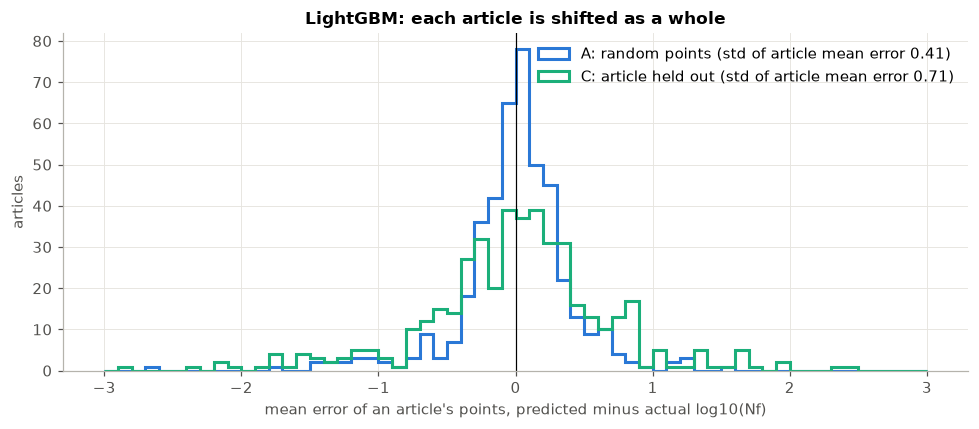

In [13]:
decomposition_rows = []
for model in [MAIN_MODEL, "BasquinResidual", "Basquin"]:
    for scheme in SCHEMES:
        sub = primary[(primary["model"] == model) & (primary["scheme"] == scheme)].copy()
        sub["error"] = sub["y_pred"] - sub["y_true"]
        # Shares of the squared error: article-mean error, curve-mean error within the article, remainder within the curve.
        decomposition_rows.append({"model": model, "scheme": scheme, "rmse": float(np.sqrt(np.mean(sub["error"] ** 2))), **eu.error_decomposition(sub)})
decomposition = pd.DataFrame(decomposition_rows)
decomposition.to_csv(METRICS_DIR / "error_decomposition.csv", index=False)
display(decomposition.set_index(["model", "scheme"]).drop(columns=["points", "curves", "articles"]))

# The row set is defined once, under experiment C, so that the three scheme columns describe the same rows.
basq = primary[(primary["model"] == "Basquin") & (primary["scheme"] == "C_article")][["row_id", "basquin_pooled_fallback"]]
known = primary[primary["model"].isin([MAIN_MODEL, "Basquin", "BasquinResidual"])].drop(columns="basquin_pooled_fallback").merge(basq, on="row_id")
known["alloy status in the training fold"] = np.where(known["basquin_pooled_fallback"].astype(bool), "alloy on the pooled Basquin line under C", "alloy with its own Basquin line under C")
known_table = (known.groupby(["model", "scheme", "alloy status in the training fold"])
               .apply(lambda g: pd.Series({"points": len(g), "articles": g["article_id"].nunique(), "rmse": float(np.sqrt(np.mean((g["y_pred"] - g["y_true"]) ** 2)))}), include_groups=False)
               .unstack("scheme"))
known_table.to_csv(METRICS_DIR / "error_known_vs_rare_alloys.csv")
display(known_table[[("points", "C_article"), ("articles", "C_article"), ("rmse", "A_random"), ("rmse", "B_curve"), ("rmse", "C_article")]])

# Why each row is on the pooled line (version 3, audit finding M7): absent from the training fold, too few data, or a slope that was not negative.
decisions_c = pd.read_csv(METRICS_DIR / "basquin_fit_log_primary.csv")
decisions_c = decisions_c[decisions_c["scheme"] == "C_article"].set_index(["fold", "alloy"])["decision"]
basquin_c = primary[(primary["model"] == "Basquin") & (primary["scheme"] == "C_article")]
reason = pd.Series([("own line" if not pooled else decisions_c.get((fold, alloy), "pooled (alloy absent from the training fold)"))
                    for fold, alloy, pooled in zip(basquin_c["fold"], basquin_c["alloy"], basquin_c["basquin_pooled_fallback"].astype(bool))],
                   index=basquin_c["row_id"].to_numpy())
by_reason = primary[primary["scheme"] == "C_article"].assign(reason=lambda t: t["row_id"].map(reason), squared=lambda t: (t["y_pred"] - t["y_true"]) ** 2)
reason_table = (by_reason[by_reason["model"] == "Basquin"].groupby("reason").agg(points=("row_id", "size"), articles=("article_id", "nunique"), alloys=("alloy", "nunique"))
                .join(by_reason.groupby(["reason", "model"])["squared"].mean().pow(0.5).unstack("model")[MODELS]))
reason_table.to_csv(METRICS_DIR / "error_by_pooled_reason_C.csv")
print("Article held out, RMSE by the reason for the Basquin decision:")
display(reason_table)
print("Alloys pooled because the slope was not negative:", basquin_c.loc[basquin_c["row_id"].map(reason).eq("pooled (slope not negative)").to_numpy(), "alloy"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(9, 4))
for scheme in ["A_random", "C_article"]:
    sub = primary[(primary["model"] == MAIN_MODEL) & (primary["scheme"] == scheme)]
    article_bias = (sub["y_pred"] - sub["y_true"]).groupby(sub["article_id"]).mean()
    ax.hist(article_bias, bins=np.linspace(-3, 3, 61), histtype="step", lw=2, color=eu.SCHEME_COLORS[scheme],
            label=f"{eu.SCHEME_LABELS[scheme]} (std of article mean error {article_bias.std():.2f})")
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="mean error of an article's points, predicted minus actual log10(Nf)", ylabel="articles",
       title=f"{mu.MODEL_LABELS[MAIN_MODEL]}: each article is shifted as a whole")
ax.legend()
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "04_article_offsets.png")
plt.show()

*Note:* for LightGBM with articles held out, 48% of the squared error is a whole-article offset (36% with articles weighted equally), against 24% under random validation.

### 9.1 Extreme load ratios

Check how much the 13 points tested at R = −3 or R = −10 affect the results. No points are removed.

In [14]:
r_values = data.set_index("row_id")["R"]
extreme = primary["row_id"].map(r_values) < -1.5
rows = []
for model in MODELS:
    for scheme in SCHEMES:
        mask = (primary["model"] == model) & (primary["scheme"] == scheme)
        err_all = primary.loc[mask, "y_pred"] - primary.loc[mask, "y_true"]
        err_ext = primary.loc[mask & extreme, "y_pred"] - primary.loc[mask & extreme, "y_true"]
        err_rest = primary.loc[mask & ~extreme, "y_pred"] - primary.loc[mask & ~extreme, "y_true"]
        rows.append({"model": model, "scheme": scheme, "points with R < -1.5": int(len(err_ext)), "rmse all rows": float(np.sqrt(np.mean(err_all ** 2))),
                     "rmse without those points": float(np.sqrt(np.mean(err_rest ** 2))), "rmse of those points": float(np.sqrt(np.mean(err_ext ** 2))),
                     "largest predicted log10(N)": float(primary.loc[mask & extreme, "y_pred"].max())})
extreme_table = pd.DataFrame(rows)
extreme_table.to_csv(METRICS_DIR / "extreme_load_ratio_check.csv", index=False)
wide = extreme_table.pivot(index="model", columns="scheme", values=["rmse all rows", "rmse without those points", "rmse of those points"]).loc[MODELS]
display(wide)
without = extreme_table.pivot(index="model", columns="scheme", values="rmse without those points").loc[MODELS, SCHEMES]
print("Inflation C/A without the 13 points:", (without["C_article"] / without["A_random"]).round(3).to_dict())
print("Largest life predicted by Ridge for these points: 10^", round(float(extreme_table[extreme_table["model"] == "Ridge"]["largest predicted log10(N)"].max()), 1), "cycles")

rmse all rows                   rmse without those points                   rmse of those points                  
scheme               A_random B_curve C_article                  A_random B_curve C_article             A_random B_curve C_article
model                                                                                                                             
Basquin                 0.938   0.954     0.992                     0.937   0.953     0.991                1.464   1.463     1.462
Ridge                   0.897   0.951     0.970                     0.896   0.917     0.958                1.607   7.856     4.713
RandomForest            0.647   0.797     0.927                     0.646   0.796     0.926                1.319   1.413     1.405
LightGBM                0.673   0.787     0.924                     0.672   0.786     0.923                1.391   1.365     1.458
BasquinResidual         0.667   0.788     0.940                     0.666   0.788     0.939                1.393   1.397     1.413

Inflation C/A without the 13 points: {'Basquin': 1.058, 'Ridge': 1.07, 'RandomForest': 1.433, 'LightGBM': 1.375, 'BasquinResidual': 1.41}
Largest life predicted by Ridge for these points: 10^ 15.4 cycles


*Note:* only Ridge is affected, because it extrapolates along R without limit. The inflation of the tree models does not change.

### 9.2 Supplementary: Basquin fallback and where the residual model loses

Count how often the Basquin anchor falls back to the pooled line, and split the article-held-out rows by what the anchor knew about the alloy (exploratory split).

In [15]:
WELL_REPRESENTED = data.groupby("alloy")["article_id"].nunique().loc[lambda s: s >= 15].index.tolist()
basquin_rows = primary[primary["model"] == "Basquin"].copy()
basquin_rows["pooled"] = basquin_rows["basquin_pooled_fallback"].astype(str).str.lower().eq("true")
fit_log = pd.read_csv(METRICS_DIR / "basquin_fit_log_primary.csv")

def alloy_absent_from_training(scheme):
    rows = basquin_rows[basquin_rows["scheme"] == scheme]
    absent = pd.Series(False, index=rows.index)
    for fold in sorted(rows["fold"].unique()):
        in_fold = rows["fold"] == fold
        training_alloys = set(data.loc[~data["row_id"].isin(rows.loc[in_fold, "row_id"]), "alloy"])
        absent[in_fold] = ~rows.loc[in_fold, "alloy"].isin(training_alloys)
    return absent

own_line = fit_log[fit_log["decision"] == "per-alloy"].groupby(["scheme", "fold"]).size().groupby("scheme")
fallback = pd.DataFrame({
    "held-out rows on the pooled line": basquin_rows.groupby("scheme")["pooled"].sum().astype(int),
    "share of held-out rows on the pooled line": basquin_rows.groupby("scheme")["pooled"].mean(),
    "held-out rows whose alloy is absent from training": pd.Series({s: int(alloy_absent_from_training(s).sum()) for s in SCHEMES}),
    "alloys with their own line per fold, min": own_line.min(),
    "alloys with their own line per fold, max": own_line.max(),
}).loc[SCHEMES]
fallback.to_csv(METRICS_DIR / "basquin_fallback_frequency.csv")
display(fallback)

c_rows = basquin_rows[basquin_rows["scheme"] == "C_article"].copy()
c_rows["absent"] = alloy_absent_from_training("C_article")
c_rows["group"] = np.select([c_rows["absent"], c_rows["pooled"], c_rows["alloy"].isin(WELL_REPRESENTED)],
                            ["4 alloy absent from the training fold", "3 alloy in training, pooled line", "1 well-represented alloy (15+ articles)"],
                            default="2 other alloy with its own line")
coverage = c_rows.set_index("row_id")["group"]
scored = primary[primary["scheme"] == "C_article"].assign(group=lambda t: t["row_id"].map(coverage), sq=lambda t: (t["y_pred"] - t["y_true"]) ** 2)
coverage_table = (scored[scored["model"] == "Basquin"].groupby("group").agg(points=("row_id", "size"), articles=("article_id", "nunique"), alloys=("alloy", "nunique"))
                  .join(scored.groupby(["group", "model"])["sq"].mean().pow(0.5).unstack("model")[MODELS]))
squared = scored.pivot_table(index="row_id", columns="model", values="sq")
gap = squared["BasquinResidual"] - squared["LightGBM"]
gap_rows = {}
for group, sub in scored[scored["model"].isin(["LightGBM", "BasquinResidual"])].groupby("group"):
    samples, _ = eu.cluster_bootstrap_rmse(sub, n_boot=N_BOOT, seed=0)
    diff = eu.bootstrap_difference(samples, ("BasquinResidual", "C_article"), ("LightGBM", "C_article"))
    gap_rows[group] = {"residual minus LightGBM": coverage_table.loc[group, "BasquinResidual"] - coverage_table.loc[group, "LightGBM"],
                       "95% CI low": diff["ci_low"], "95% CI high": diff["ci_high"],
                       "share of the overall gap in squared error": float(gap[gap.index.map(coverage) == group].sum() / gap.sum())}
coverage_table = coverage_table.join(pd.DataFrame(gap_rows).T)
coverage_table.to_csv(METRICS_DIR / "error_by_alloy_coverage_C.csv")
print("Well-represented alloys:", ", ".join(WELL_REPRESENTED))
display(coverage_table)

,held-out rows on the pooled line,share of held-out rows on the pooled line,held-out rows whose alloy is absent from training,"alloys with their own line per fold, min","alloys with their own line per fold, max"
A_random,1581,0.125,1,23,23
B_curve,1760,0.139,365,21,25
C_article,2126,0.168,1042,20,25


Well-represented alloys: 17-4 PH, 316L, AlSi10Mg, IN718, Ti-6Al-4V


,points,articles,alloys,Basquin,Ridge,RandomForest,LightGBM,BasquinResidual,residual minus LightGBM,95% CI low,95% CI high,share of the overall gap in squared error
group,,,,,,,,,,,,
1 well-represented alloy (15+ articles),9448,308,5,0.980,0.942,0.921,0.903,0.904,0.001,-0.010,0.011,0.043
2 other alloy with its own line,1092,44,14,1.182,0.869,0.882,0.866,1.050,0.184,0.047,0.334,1.018
"3 alloy in training, pooled line",1084,51,22,0.982,1.127,0.992,1.051,1.007,-0.044,-0.190,0.050,-0.258
4 alloy absent from the training fold,1042,56,60,0.888,1.124,0.960,1.024,1.058,0.034,0.000,0.067,0.198


*Note:* almost all of the residual model's deficit comes from moderately represented alloys whose own Basquin line rests on few sources.

### 9.3 Supplementary: direction of the main effects

Change one input for every row (surface class, heat-treatment class or R) in the final models and record the change in predicted life. This is an in-sample association, not a causal effect.

In [16]:
import joblib
final_models = {name: joblib.load(PROJECT_ROOT / "models" / f"{name}.joblib") for name in ["Ridge", "RandomForest", "LightGBM", "BasquinResidual"]}
changes = [("surface_class", "as-built_or_unreported", ["machined", "polished", "peened"], "longer"),
           ("heat_treatment_class", "NHT_or_unreported", ["HT", "HIP"], "longer"),
           ("R", -1.0, [0.1, 0.5], "shorter")]

def with_value(frame, column, value):
    changed = frame.copy()
    changed[column] = value
    return fu.add_stress_features(changed) if column == "R" else changed

direction_rows = []
for name, model in final_models.items():
    for column, reference, alternatives, expected in changes:
        reference_prediction = model.predict(with_value(data, column, reference)[FEATURES])
        for alternative in alternatives:
            shift = model.predict(with_value(data, column, alternative)[FEATURES]) - reference_prediction
            agrees = shift > 0 if expected == "longer" else shift < 0
            direction_rows.append({"model": mu.MODEL_LABELS[name], "change": f"{column}: {reference} to {alternative}", "expected life": expected,
                                   "mean shift in log10(Nf)": float(shift.mean()), "share of rows with the expected sign": float(agrees.mean())})
directions = pd.DataFrame(direction_rows)
directions.to_csv(METRICS_DIR / "model_effect_directions.csv", index=False)
model_columns = [mu.MODEL_LABELS[n] for n in final_models]
print("Mean change in predicted log10(Nf):")
display(directions.pivot(index="change", columns="model", values="mean shift in log10(Nf)")[model_columns])
print("Share of rows where the change has the expected sign:")
display(directions.pivot(index="change", columns="model", values="share of rows with the expected sign")[model_columns])

Mean change in predicted log10(Nf):


model,Ridge,Random Forest,LightGBM,Basquin-anchored residual
change,,,,
R: -1.0 to 0.1,-0.302,-0.410,-0.426,-0.408
R: -1.0 to 0.5,-0.422,-0.388,-0.179,-0.072
heat_treatment_class: NHT_or_unreported to HIP,0.334,0.171,0.198,0.195
heat_treatment_class: NHT_or_unreported to HT,0.068,0.054,0.065,0.075
surface_class: as-built_or_unreported to machined,0.537,0.425,0.438,0.453
surface_class: as-built_or_unreported to peened,0.874,0.537,0.598,0.627
surface_class: as-built_or_unreported to polished,0.557,0.440,0.423,0.430


Share of rows where the change has the expected sign:


model,Ridge,Random Forest,LightGBM,Basquin-anchored residual
change,,,,
R: -1.0 to 0.1,1.000,0.686,0.771,0.767
R: -1.0 to 0.5,1.000,0.666,0.597,0.526
heat_treatment_class: NHT_or_unreported to HIP,1.000,0.657,0.690,0.706
heat_treatment_class: NHT_or_unreported to HT,1.000,0.597,0.634,0.637
surface_class: as-built_or_unreported to machined,1.000,0.748,0.859,0.854
surface_class: as-built_or_unreported to peened,1.000,0.826,0.948,0.964
surface_class: as-built_or_unreported to polished,1.000,0.745,0.823,0.823


*Note:* on average every model gives the expected direction, but the tree models do not do so consistently row by row.

## 10. Stability across seeds

Compare the results for seeds 42, 43 and 44. A seed sets both the fold assignment and the learners' random state.

In [17]:
all_seeds = pd.concat([primary, extra_seeds], ignore_index=True)
seed_metrics = eu.metrics_table(all_seeds, by=("model", "scheme", "seed"))
seed_wide = seed_metrics.pivot_table(index=["model", "seed"], columns="scheme", values="rmse")[SCHEMES]
seed_wide["inflation B/A"] = seed_wide["B_curve"] / seed_wide["A_random"]
seed_wide["inflation C/A"] = seed_wide["C_article"] / seed_wide["A_random"]
seed_wide.to_csv(METRICS_DIR / "metrics_by_seed.csv")

seed_summary = seed_wide.groupby("model").agg(["mean", "min", "max"]).loc[MODELS]
seed_summary.to_csv(METRICS_DIR / "metrics_seed_summary.csv")
display(seed_wide.loc[MODELS])
display(seed_summary[[("C_article", "mean"), ("C_article", "min"), ("C_article", "max"), ("inflation C/A", "mean"), ("inflation C/A", "min"), ("inflation C/A", "max")]])

residual_vs_gbm = seed_wide.loc["BasquinResidual", "C_article"] - seed_wide.loc["LightGBM", "C_article"]
print("Article-held-out RMSE, residual model minus LightGBM, per seed:", residual_vs_gbm.round(4).to_dict())

scheme                A_random  B_curve  C_article  inflation B/A  inflation C/A
model           seed                                                            
Basquin         42       0.938    0.954      0.992          1.018          1.058
                43       0.939    0.955      1.000          1.017          1.065
                44       0.940    0.952      0.999          1.013          1.062
Ridge           42       0.897    0.951      0.970          1.060          1.081
                43       0.896    0.918      0.983          1.025          1.097
                44       0.897    0.917      0.983          1.022          1.096
RandomForest    42       0.647    0.797      0.927          1.231          1.432
                43       0.653    0.788      0.930          1.208          1.425
                44       0.655    0.788      0.914          1.204          1.397
LightGBM        42       0.673    0.787      0.924          1.170          1.373
                43       0.675    0.785      0.923          1.162          1.367
                44       0.675    0.784      0.907          1.162          1.343
BasquinResidual 42       0.667    0.788      0.940          1.181          1.408
                43       0.670    0.788      0.939          1.175          1.400
                44       0.671    0.783      0.925          1.167          1.379

scheme          C_article             inflation C/A            
                     mean   min   max          mean   min   max
model                                                          
Basquin             0.997 0.992 1.000         1.062 1.058 1.065
Ridge               0.979 0.970 0.983         1.092 1.081 1.097
RandomForest        0.924 0.914 0.930         1.418 1.397 1.432
LightGBM            0.918 0.907 0.924         1.361 1.343 1.373
BasquinResidual     0.935 0.925 0.940         1.396 1.379 1.408

Article-held-out RMSE, residual model minus LightGBM, per seed: {42: 0.016, 43: 0.0161, 44: 0.0185}


## 11. Sensitivity analyses

Each analysis changes one choice and is compared with a baseline on the same rows.

### 11.1 S1: stricter held-out units

Hold out groups of articles linked by re-published curves (C2) and clusters of articles that share an author (D).

In [18]:
group_pred_all = pd.read_csv(PRED_DIR / "oof_predictions_group_sensitivity.csv")
group_pred = group_pred_all[group_pred_all["seed"] == SEED]
five_schemes = SCHEMES + ["C2_article_group", "D_author_cluster"]
s1 = eu.rmse_pivot(pd.concat([primary, group_pred], ignore_index=True), MODELS, five_schemes)
s1.to_csv(METRICS_DIR / "sensitivity_S1_group_schemes.csv")
display(s1.rename(columns=eu.SCHEME_LABELS))

# C against C2 for each seed. Regrouping the articles changes every fold, so one seed alone cannot
# separate the effect of the grouping from the luck of the fold assignment.
c_and_c2 = pd.concat([primary, extra_seeds, group_pred_all[group_pred_all["scheme"] == "C2_article_group"]], ignore_index=True)
c_and_c2 = c_and_c2[c_and_c2["scheme"].isin(["C_article", "C2_article_group"])]
s1_seeds = eu.metrics_table(c_and_c2, by=("model", "scheme", "seed")).pivot_table(index=["model", "seed"], columns="scheme", values="rmse")[["C_article", "C2_article_group"]]
s1_seeds["C2 minus C"] = s1_seeds["C2_article_group"] - s1_seeds["C_article"]
s1_seed_mean = s1_seeds.groupby("model").mean().loc[MODELS]
s1_seeds.to_csv(METRICS_DIR / "sensitivity_S1_C_vs_C2_by_seed.csv")
print("Article held out (C) against re-publication group held out (C2), RMSE per seed:")
display(s1_seeds.loc[[MAIN_MODEL, "RandomForest"]])
print("Mean over the three seeds:")
display(s1_seed_mean)

# The re-published curves under experiment C: are they predicted better than the rest, as leakage would suggest?
flag = data.set_index("row_id")["in_near_duplicate_pair"]
both = c_and_c2[c_and_c2["model"].isin([MAIN_MODEL, "RandomForest"])].copy()     # all three seeds pooled
both["re-published curve"] = both["row_id"].map(flag)
print(f"Points on re-published curves: {int(flag.sum()):,} of {len(flag):,} ({100 * flag.mean():.1f}%). RMSE pooled over three seeds:")
dup_table = (both.groupby(["model", "re-published curve", "scheme"])
             .apply(lambda g: pd.Series({"points": g["row_id"].nunique(), "rmse": float(np.sqrt(np.mean((g["y_pred"] - g["y_true"]) ** 2)))}), include_groups=False).unstack("scheme"))
dup_table.to_csv(METRICS_DIR / "sensitivity_S1_republished_curves.csv")
display(dup_table)

d_folds = mu.fold_composition(data, mu.make_folds(data, "D_author_cluster", SEED))
d_pred = group_pred[(group_pred["scheme"] == "D_author_cluster") & (group_pred["model"] == MAIN_MODEL)]
d_by_fold = d_pred.groupby("fold").apply(lambda g: float(np.sqrt(np.mean((g["y_pred"] - g["y_true"]) ** 2))), include_groups=False).rename("LightGBM rmse")
display(d_folds.set_index("fold").join(d_by_fold))

# Reference: the mean predictor under the two sensitivity schemes.
mean_reference = {}
for scheme in ["C_article", "C2_article_group", "D_author_cluster"]:
    scheme_folds = mu.make_folds(data, scheme, SEED)
    mean_reference[scheme] = float(np.sqrt(np.mean((eu.mean_baseline_predictions(data, scheme_folds) - data["log_N"]) ** 2)))
print("Mean predictor RMSE:", {eu.SCHEME_LABELS[k]: round(v, 3) for k, v in mean_reference.items()})

h3_c, h3_d = float(s1.loc[MAIN_MODEL, "C_article"]), float(s1.loc[MAIN_MODEL, "D_author_cluster"])
h3_verdict = "consistent with H3 (not a formal test)" if h3_d >= h3_c else "not supported in this run"
h3_evidence = (f"{mu.MODEL_LABELS[MAIN_MODEL]} RMSE {h3_d:.3f} with author clusters held out against {h3_c:.3f} with articles held out; "
               f"author clusters are built by name matching and one cluster holds {int(data.groupby('author_cluster_id')['article_id'].nunique().max())} articles")

scheme,A: random points,B: curve held out,C: article held out,C2: re-publication group held out,D: author cluster held out,inflation B_curve/A_random,inflation C_article/A_random,inflation C2_article_group/A_random,inflation D_author_cluster/A_random
model,,,,,,,,,
Basquin,0.938,0.954,0.992,0.993,0.998,1.018,1.058,1.059,1.065
Ridge,0.897,0.951,0.970,0.973,1.027,1.060,1.081,1.085,1.145
RandomForest,0.647,0.797,0.927,0.928,0.977,1.231,1.432,1.433,1.510
LightGBM,0.673,0.787,0.924,0.920,1.008,1.170,1.373,1.368,1.498
BasquinResidual,0.667,0.788,0.940,0.944,1.017,1.181,1.408,1.414,1.524


Article held out (C) against re-publication group held out (C2), RMSE per seed:


scheme             C_article  C2_article_group  C2 minus C
model        seed                                         
LightGBM     42        0.924             0.920      -0.003
             43        0.923             0.928       0.005
             44        0.907             0.940       0.033
RandomForest 42        0.927             0.928       0.001
             43        0.930             0.947       0.017
             44        0.914             0.947       0.033

Mean over the three seeds:


scheme,C_article,C2_article_group,C2 minus C
model,,,
Basquin,0.997,0.994,-0.003
Ridge,0.979,0.983,0.005
RandomForest,0.924,0.941,0.017
LightGBM,0.918,0.929,0.012
BasquinResidual,0.935,0.944,0.009


Points on re-published curves: 1,066 of 12,666 (8.4%). RMSE pooled over three seeds:


points                       rmse          
scheme                          C2_article_group C_article C2_article_group C_article
model        re-published curve                                                      
LightGBM     False                     11600.000 11600.000            0.928     0.927
             True                       1066.000  1066.000            0.949     0.813
RandomForest False                     11600.000 11600.000            0.939     0.934
             True                       1066.000  1066.000            0.963     0.808

,points,curves,articles,LightGBM rmse
fold,,,,
0,1669,197,65,0.937
1,6563,792,213,1.050
2,1266,141,45,0.946
3,1593,208,63,1.039
4,1575,195,54,0.915


Mean predictor RMSE: {'C: article held out': 0.994, 'C2: re-publication group held out': 0.995, 'D: author cluster held out': 0.993}


*Note:* re-published curves make the article-held-out error optimistic by roughly 0.01–0.02. With author clusters held out, LightGBM is no better than the mean predictor, but this split is unbalanced and only indicative.

### 11.2 S2: monotonic constraint on stress

Compare LightGBM constrained so that predicted life never rises with stress against the unconstrained model.

In [19]:
monotone = pd.read_csv(PRED_DIR / "oof_predictions_monotone.csv")
s2 = eu.rmse_pivot(pd.concat([primary, monotone], ignore_index=True), ["LightGBM", "LightGBM_monotone", "BasquinResidual", "Basquin"], SCHEMES)
s2.to_csv(METRICS_DIR / "sensitivity_S2_monotone.csv")
display(s2)

mono_boot, _ = eu.cluster_bootstrap_rmse(pd.concat([primary[primary["model"] == "LightGBM"], monotone], ignore_index=True), n_boot=N_BOOT, seed=0)
mono_diff = eu.bootstrap_difference(mono_boot, ("LightGBM_monotone", "C_article"), ("LightGBM", "C_article"))
print("Article held out, monotone minus unconstrained LightGBM:", {k: round(v, 4) for k, v in mono_diff.items()})

scheme,A_random,B_curve,C_article,inflation B_curve/A_random,inflation C_article/A_random
model,,,,,
LightGBM,0.673,0.787,0.924,1.170,1.373
LightGBM_monotone,0.689,0.807,0.941,1.170,1.366
BasquinResidual,0.667,0.788,0.940,1.181,1.408
Basquin,0.938,0.954,0.992,1.018,1.058


Article held out, monotone minus unconstrained LightGBM: {'bootstrap_mean_difference': 0.0175, 'ci_low': -0.001, 'ci_high': 0.0353, 'share_of_resamples_first_is_lower': 0.033}


*Note:* the constraint gives physically sensible curves but does not improve transfer to unseen articles.

### 11.3 S3 and S4: richer feature tiers

Compare tier 1 (Kt, frequency, build direction) with tier 0 on the full data, and tier 2 (σa/UTS, UTS) with tier 0 on the UTS subset, using paired article-bootstrap differences.

In [20]:
tier1 = pd.read_csv(PRED_DIR / "oof_predictions_tier1.csv")
tier_models = ["Ridge", "RandomForest", "LightGBM", "BasquinResidual"]
s3 = pd.concat({"tier 0 (primary)": eu.rmse_pivot(primary, tier_models, SCHEMES), "tier 1 (+ Kt, frequency, build direction)": eu.rmse_pivot(tier1, tier_models, SCHEMES)}, names=["features"])
s3.to_csv(METRICS_DIR / "sensitivity_S3_feature_tier1.csv")
print(f"S3, full dataset: {len(data):,} points, {data['article_id'].nunique()} articles")
display(s3)

uts = pd.read_csv(PRED_DIR / "oof_predictions_uts_subset.csv")
uts_rows = uts[uts["feature_tier"] == "tier0"]["row_id"].nunique()
s4 = pd.concat({"tier 0 on the UTS subset": eu.rmse_pivot(uts[uts["feature_tier"] == "tier0"], tier_models, SCHEMES),
                "tier 2 (+ sigma_a/UTS, UTS) on the UTS subset": eu.rmse_pivot(uts[uts["feature_tier"] == "tier2"], tier_models, SCHEMES)}, names=["features"])
s4.to_csv(METRICS_DIR / "sensitivity_S4_uts_subset.csv")
print(f"S4, UTS subset: {uts_rows:,} points, {uts['article_id'].nunique()} articles, target standard deviation {uts[uts['feature_tier'] == 'tier0'].drop_duplicates('row_id')['y_true'].std():.3f}")
display(s4)

# How specific is a reported UTS value to its source?
uts_values = data[data["uts_mpa"].notna()]
articles_per_value = uts_values.groupby("uts_mpa")["article_id"].nunique()
single_article_values = articles_per_value[articles_per_value == 1].index
print(f"Distinct UTS values: {len(articles_per_value)}; values that occur in a single article: {len(single_article_values)} "
      f"({100 * len(single_article_values) / len(articles_per_value):.0f}%); points carrying such a value: {100 * uts_values['uts_mpa'].isin(single_article_values).mean():.0f}%")

tier_boot, _ = eu.cluster_bootstrap_rmse(pd.concat([primary[primary["model"] == "LightGBM"].assign(model="LightGBM tier 0"), tier1[tier1["model"] == "LightGBM"].assign(model="LightGBM tier 1")], ignore_index=True), n_boot=N_BOOT, seed=0)
print("Article held out, tier 1 minus tier 0 (LightGBM):", {k: round(v, 4) for k, v in eu.bootstrap_difference(tier_boot, ("LightGBM tier 1", "C_article"), ("LightGBM tier 0", "C_article")).items()})
uts_boot, _ = eu.cluster_bootstrap_rmse(pd.concat([uts[(uts["model"] == "LightGBM") & (uts["feature_tier"] == t)].assign(model=f"LightGBM {t}") for t in ("tier0", "tier2")], ignore_index=True), n_boot=N_BOOT, seed=0)
print("Article held out, tier 2 minus tier 0 on the UTS subset (LightGBM):", {k: round(v, 4) for k, v in eu.bootstrap_difference(uts_boot, ("LightGBM tier2", "C_article"), ("LightGBM tier0", "C_article")).items()})

# Version 3 (audit findings M2 and M4): the same paired comparison for every model.
paired_rows = []
for model in tier_models:
    b3, _ = eu.cluster_bootstrap_rmse(pd.concat([primary[primary["model"] == model].assign(model="tier 0"), tier1[tier1["model"] == model].assign(model="tier 1")], ignore_index=True), n_boot=N_BOOT, seed=0)
    d3 = eu.bootstrap_difference(b3, ("tier 1", "C_article"), ("tier 0", "C_article"))
    b4, _ = eu.cluster_bootstrap_rmse(pd.concat([uts[(uts["model"] == model) & (uts["feature_tier"] == t)].assign(model=t) for t in ("tier0", "tier2")], ignore_index=True), n_boot=N_BOOT, seed=0)
    d4 = eu.bootstrap_difference(b4, ("tier2", "C_article"), ("tier0", "C_article"))
    paired_rows.append({"comparison": "S3: tier 1 minus tier 0, full data", "model": mu.MODEL_LABELS[model],
                        "difference in article-held-out RMSE": s3.loc[("tier 1 (+ Kt, frequency, build direction)", model), "C_article"] - s3.loc[("tier 0 (primary)", model), "C_article"],
                        "95% CI low": d3["ci_low"], "95% CI high": d3["ci_high"]})
    paired_rows.append({"comparison": "S4: tier 2 minus tier 0, UTS subset", "model": mu.MODEL_LABELS[model],
                        "difference in article-held-out RMSE": s4.loc[("tier 2 (+ sigma_a/UTS, UTS) on the UTS subset", model), "C_article"] - s4.loc[("tier 0 on the UTS subset", model), "C_article"],
                        "95% CI low": d4["ci_low"], "95% CI high": d4["ci_high"]})
paired_by_model = pd.DataFrame(paired_rows)
paired_by_model.to_csv(METRICS_DIR / "sensitivity_S3_S4_paired_by_model.csv", index=False)
print("Paired article-bootstrap differences, article held out (negative = the richer tier is better):")
display(paired_by_model)

# Where does the tier-1 gain come from? Share of the drop in squared error (article held out) by row group.
rows_info = data.set_index("row_id")
frequency_hz = 10 ** rows_info["log_frequency"]
groups = {"notched specimens (Kt > 1)": rows_info["kt"] > 1,
          "displacement-controlled tests": rows_info["load_control"] == "displacement",
          "tests at 1 kHz or above": frequency_hz >= 1000}
groups["all other rows"] = ~(groups["notched specimens (Kt > 1)"] | groups["displacement-controlled tests"] | groups["tests at 1 kHz or above"])
gain_rows = []
for model in tier_models:
    e0 = primary[(primary["model"] == model) & (primary["scheme"] == "C_article")].set_index("row_id")
    e1 = tier1[(tier1["model"] == model) & (tier1["scheme"] == "C_article")].set_index("row_id").reindex(e0.index)
    drop = (e0["y_pred"] - e0["y_true"]) ** 2 - (e1["y_pred"] - e1["y_true"]) ** 2
    for group, mask in groups.items():
        mask = mask.reindex(e0.index).fillna(False).astype(bool)
        gain_rows.append({"model": mu.MODEL_LABELS[model], "row group": group, "share of rows": float(mask.mean()),
                          "share of the drop in squared error": float(drop[mask].sum() / drop.sum())})
tier1_gain = pd.DataFrame(gain_rows)
tier1_gain.to_csv(METRICS_DIR / "tier1_gain_by_row_group.csv", index=False)
print("Share of the tier-1 gain (drop in squared error, article held out) by row group; the first three groups overlap:")
display(tier1_gain.pivot(index="row group", columns="model", values="share of the drop in squared error").join(
    tier1_gain.drop_duplicates("row group").set_index("row group")["share of rows"]))

S3, full dataset: 12,666 points, 440 articles


scheme                                                     A_random  B_curve  C_article  inflation B_curve/A_random  inflation C_article/A_random
features                                  model                                                                                                  
tier 0 (primary)                          Ridge               0.897    0.951      0.970                       1.060                         1.081
                                          RandomForest        0.647    0.797      0.927                       1.231                         1.432
                                          LightGBM            0.673    0.787      0.924                       1.170                         1.373
                                          BasquinResidual     0.667    0.788      0.940                       1.181                         1.408
tier 1 (+ Kt, frequency, build direction) Ridge               0.805    0.830      0.872                       1.031                         1.083
                                          RandomForest        0.566    0.734      0.872                       1.298                         1.541
                                          LightGBM            0.589    0.714      0.862                       1.212                         1.464
                                          BasquinResidual     0.584    0.719      0.887                       1.232                         1.518

S4, UTS subset: 6,674 points, 244 articles, target standard deviation 1.013


scheme                                                         A_random  B_curve  C_article  inflation B_curve/A_random  inflation C_article/A_random
features                                      model                                                                                                  
tier 0 on the UTS subset                      Ridge               0.901    0.929      0.966                       1.030                         1.073
                                              RandomForest        0.664    0.808      0.932                       1.216                         1.402
                                              LightGBM            0.669    0.810      0.936                       1.209                         1.399
                                              BasquinResidual     0.668    0.810      0.944                       1.214                         1.414
tier 2 (+ sigma_a/UTS, UTS) on the UTS subset Ridge               0.875    0.900      0.938                       1.029                         1.073
                                              RandomForest        0.595    0.803      0.929                       1.349                         1.560
                                              LightGBM            0.580    0.801      0.964                       1.380                         1.661
                                              BasquinResidual     0.579    0.806      0.971                       1.391                         1.676

Distinct UTS values: 416; values that occur in a single article: 341 (82%); points carrying such a value: 62%
Article held out, tier 1 minus tier 0 (LightGBM): {'bootstrap_mean_difference': -0.0615, 'ci_low': -0.0984, 'ci_high': -0.025, 'share_of_resamples_first_is_lower': 0.999}


Article held out, tier 2 minus tier 0 on the UTS subset (LightGBM): {'bootstrap_mean_difference': 0.0285, 'ci_low': -0.0104, 'ci_high': 0.0662, 'share_of_resamples_first_is_lower': 0.086}


Paired article-bootstrap differences, article held out (negative = the richer tier is better):


,comparison,model,difference in article-held-out RMSE,95% CI low,95% CI high
0,"S3: tier 1 minus tier 0, full data",Ridge,-0.098,-0.136,-0.059
1,"S4: tier 2 minus tier 0, UTS subset",Ridge,-0.028,-0.054,-0.004
2,"S3: tier 1 minus tier 0, full data",Random Forest,-0.055,-0.097,-0.011
3,"S4: tier 2 minus tier 0, UTS subset",Random Forest,-0.003,-0.036,0.029
4,"S3: tier 1 minus tier 0, full data",LightGBM,-0.062,-0.098,-0.025
5,"S4: tier 2 minus tier 0, UTS subset",LightGBM,0.028,-0.010,0.066
6,"S3: tier 1 minus tier 0, full data",Basquin-anchored residual,-0.053,-0.089,-0.016
7,"S4: tier 2 minus tier 0, UTS subset",Basquin-anchored residual,0.027,-0.009,0.062


Share of the tier-1 gain (drop in squared error, article held out) by row group; the first three groups overlap:


,Basquin-anchored residual,LightGBM,Random Forest,Ridge,share of rows
row group,,,,,
all other rows,0.515,0.561,0.511,0.385,0.877
displacement-controlled tests,0.448,0.395,0.430,0.606,0.070
notched specimens (Kt > 1),0.036,0.044,0.059,0.009,0.053
tests at 1 kHz or above,0.567,0.496,0.617,0.637,0.059


*Note:* tier 1 lowers the error but raises the inflation. UTS improves the random-split error but not the article-held-out error of the tree models, so random validation can overstate the value of a feature.

### 11.4 S5: run-outs treated as failures

Score the models trained with the 1,748 run-outs treated as failures at their recorded life, on all rows and on failures only.

In [21]:
runout_pred = pd.read_csv(PRED_DIR / "oof_predictions_with_runouts.csv")
s5_all = eu.rmse_pivot(runout_pred, MODELS, SCHEMES)
s5_failures = eu.rmse_pivot(runout_pred[runout_pred["is_runout"] == 0], MODELS, SCHEMES)
s5_runouts = eu.rmse_pivot(runout_pred[runout_pred["is_runout"] == 1], MODELS, SCHEMES)
s5 = pd.concat({"primary (trained and scored on failures)": eu.rmse_pivot(primary, MODELS, SCHEMES),
                "trained with run-outs, scored on failures only": s5_failures,
                "trained with run-outs, scored on all rows": s5_all}, names=["analysis"])
s5.to_csv(METRICS_DIR / "sensitivity_S5_runouts.csv")
display(s5)

sub = runout_pred[(runout_pred["model"] == MAIN_MODEL) & (runout_pred["scheme"] == "C_article")]
bias = (sub["y_pred"] - sub["y_true"]).groupby(sub["is_runout"]).agg(["size", "mean"]).rename(index={0: "failures", 1: "run-outs"}, columns={"size": "points", "mean": "mean error (predicted minus recorded log10 N)"})
display(bias)
primary_c = primary[(primary["model"] == MAIN_MODEL) & (primary["scheme"] == "C_article")]
print(f"Mean error on failures, article held out: primary analysis {float((primary_c['y_pred'] - primary_c['y_true']).mean()):+.3f}; with run-outs in training {float(bias.loc['failures'].iloc[1]):+.3f}")

scheme                                                          A_random  B_curve  C_article  inflation B_curve/A_random  inflation C_article/A_random
analysis                                       model                                                                                                  
primary (trained and scored on failures)       Basquin             0.938    0.954      0.992                       1.018                         1.058
                                               Ridge               0.897    0.951      0.970                       1.060                         1.081
                                               RandomForest        0.647    0.797      0.927                       1.231                         1.432
                                               LightGBM            0.673    0.787      0.924                       1.170                         1.373
                                               BasquinResidual     0.667    0.788      0.940                       1.181                         1.408
trained with run-outs, scored on failures only Basquin             0.956    0.979      1.013                       1.024                         1.060
                                               Ridge               0.913    0.930      0.994                       1.019                         1.089
                                               RandomForest        0.673    0.811      0.955                       1.206                         1.420
                                               LightGBM            0.694    0.803      0.952                       1.156                         1.371
                                               BasquinResidual     0.689    0.807      0.971                       1.172                         1.409
trained with run-outs, scored on all rows      Basquin             1.022    1.043      1.078                       1.021                         1.055
                                               Ridge               0.968    0.986      1.043                       1.019                         1.077
                                               RandomForest        0.724    0.865      1.001                       1.195                         1.382
                                               LightGBM            0.748    0.859      0.999                       1.149                         1.336
                                               BasquinResidual     0.742    0.863      1.018                       1.162                         1.371

,points,mean error (predicted minus recorded log10 N)
is_runout,,
failures,12666,0.113
run-outs,1748,-1.008


Mean error on failures, article held out: primary analysis -0.017; with run-outs in training +0.113


*Note:* the inflation is unchanged (1.37), but the predictions for real failures become worse and biased.

### 11.5 S6: test temperature recorded as 25 °C

Compare the errors of rows with temperature evidence against the ambiguous 25 °C rows, using the primary predictions.

In [22]:
temperature = data.set_index("row_id")["temperature_evidence"]
evidence = primary["row_id"].map(temperature)
s6_groups = [
    ("all rows (primary result)", evidence.notna()),
    ("ambiguous: 25 °C, no other evidence", evidence == "25, default or reported"),
    ("with temperature evidence", evidence != "25, default or reported"),
    ("  recorded at 20 or 23 °C", evidence == "explicit, not the default"),
    ("  25 °C in an article reporting other temperatures", evidence == "25, article reports other temps"),
]
s6_rows = []
for label, mask in s6_groups:
    sub = primary[mask]
    main = sub[sub["model"] == MAIN_MODEL]
    _, summary = eu.cluster_bootstrap_rmse(main, n_boot=N_BOOT, seed=0)
    pick = lambda quantity: summary[(summary["quantity"] == quantity) & (summary["scheme"] == "C_article")].iloc[0]
    rmse = eu.rmse_pivot(sub, [MAIN_MODEL, "RandomForest", "Basquin"], SCHEMES)
    held_out = main[main["scheme"] == "C_article"]
    s6_rows.append({"rows": label, "points": len(held_out), "articles": held_out["article_id"].nunique(),
                    "LightGBM RMSE random": rmse.loc[MAIN_MODEL, "A_random"], "LightGBM RMSE curve held out": rmse.loc[MAIN_MODEL, "B_curve"],
                    "LightGBM RMSE article held out": rmse.loc[MAIN_MODEL, "C_article"],
                    "95% CI": f"{pick('rmse')['ci_low']:.2f} to {pick('rmse')['ci_high']:.2f}",
                    "LightGBM inflation C/A": rmse.loc[MAIN_MODEL, "C_article"] / rmse.loc[MAIN_MODEL, "A_random"],
                    "inflation 95% CI": f"{pick('inflation_vs_random')['ci_low']:.2f} to {pick('inflation_vs_random')['ci_high']:.2f}",
                    "Random Forest inflation C/A": rmse.loc["RandomForest", "C_article"] / rmse.loc["RandomForest", "A_random"],
                    "Basquin RMSE article held out": rmse.loc["Basquin", "C_article"]})
s6 = pd.DataFrame(s6_rows).set_index("rows")
s6.to_csv(METRICS_DIR / "sensitivity_S6_temperature.csv")
display(s6)

,points,articles,LightGBM RMSE random,LightGBM RMSE curve held out,LightGBM RMSE article held out,95% CI,LightGBM inflation C/A,inflation 95% CI,Random Forest inflation C/A,Basquin RMSE article held out
rows,,,,,,,,,,
all rows (primary result),12666,440,0.673,0.787,0.924,0.86 to 0.98,1.373,1.31 to 1.44,1.432,0.992
"ambiguous: 25 °C, no other evidence",12406,425,0.669,0.783,0.921,0.86 to 0.98,1.377,1.31 to 1.46,1.437,0.990
with temperature evidence,260,15,0.837,0.959,1.043,0.85 to 1.31,1.246,1.16 to 1.38,1.263,1.059
recorded at 20 or 23 °C,129,4,0.762,0.859,0.849,0.71 to 0.99,1.114,1.07 to 1.19,1.277,0.945
25 °C in an article reporting other temperatures,131,11,0.905,1.048,1.204,0.90 to 1.58,1.331,1.21 to 1.57,1.255,1.160


*Note:* the ambiguous rows reproduce the headline result. The evidence group is small (15 articles), so this is weak reassurance, not proof.

### 11.6 Summary of the sensitivity analyses

Collect the RMSE and inflation of every sensitivity run in one table.

In [23]:
def row(label, table, model, rows_note):
    return {"analysis": label, "model": model, "rows": rows_note, "RMSE random": table.loc[model, "A_random"], "RMSE curve held out": table.loc[model, "B_curve"],
            "RMSE article held out": table.loc[model, "C_article"], "inflation C/A": table.loc[model, "C_article"] / table.loc[model, "A_random"]}

base = eu.rmse_pivot(primary, MODELS, SCHEMES)
n_all, n_uts, n_run = f"{len(data):,}", f"{uts_rows:,}", f"{runout_pred['row_id'].nunique():,}"
summary_rows = [
    row("Primary", base, "LightGBM", n_all),
    row("Primary", base, "BasquinResidual", n_all),
    row("S2 monotone in stress", s2, "LightGBM_monotone", n_all),
    row("S3 tier 1 features", s3.loc["tier 1 (+ Kt, frequency, build direction)"], "LightGBM", n_all),
    row("S4 UTS subset, tier 0", s4.loc["tier 0 on the UTS subset"], "LightGBM", n_uts),
    row("S4 UTS subset, tier 2", s4.loc["tier 2 (+ sigma_a/UTS, UTS) on the UTS subset"], "LightGBM", n_uts),
    row("S5 run-outs as failures, scored on all rows", s5_all, "LightGBM", n_run),
    row("S5 run-outs as failures, scored on failures", s5_failures, "LightGBM", n_all),
]
sensitivity_summary = pd.DataFrame(summary_rows)
for scheme, label in [("C2_article_group", "S1 re-publication groups held out (C2)"), ("D_author_cluster", "S1 author clusters held out (D)")]:
    sensitivity_summary = pd.concat([sensitivity_summary, pd.DataFrame([{"analysis": label, "model": "LightGBM", "rows": n_all, "RMSE random": s1.loc["LightGBM", "A_random"],
                                                                         "RMSE curve held out": np.nan, "RMSE article held out": s1.loc["LightGBM", scheme],
                                                                         "inflation C/A": s1.loc["LightGBM", scheme] / s1.loc["LightGBM", "A_random"]}])], ignore_index=True)
n_rows_of = lambda mask: f"{int(mask.sum()) // (len(MODELS) * len(SCHEMES)):,}"
for label, mask in [("S6 rows with temperature evidence (primary predictions)", evidence != "25, default or reported"),
                    ("S6 ambiguous 25 °C rows (primary predictions)", evidence == "25, default or reported")]:
    sensitivity_summary = pd.concat([sensitivity_summary, pd.DataFrame([row(label, eu.rmse_pivot(primary[mask], ["LightGBM"], SCHEMES), "LightGBM", n_rows_of(mask))])], ignore_index=True)
sensitivity_summary = sensitivity_summary.rename(columns={"RMSE article held out": "RMSE strictest scheme of the run", "inflation C/A": "inflation vs random"})
sensitivity_summary.to_csv(METRICS_DIR / "sensitivity_summary.csv", index=False)
sensitivity_summary

,analysis,model,rows,RMSE random,RMSE curve held out,RMSE strictest scheme of the run,inflation vs random
0,Primary,LightGBM,"12,666",0.673,0.787,0.924,1.373
1,Primary,BasquinResidual,"12,666",0.667,0.788,0.940,1.408
2,S2 monotone in stress,LightGBM_monotone,"12,666",0.689,0.807,0.941,1.366
3,S3 tier 1 features,LightGBM,"12,666",0.589,0.714,0.862,1.464
4,"S4 UTS subset, tier 0",LightGBM,"6,674",0.669,0.810,0.936,1.399
5,"S4 UTS subset, tier 2",LightGBM,"6,674",0.580,0.801,0.964,1.661
6,"S5 run-outs as failures, scored on all rows",LightGBM,"14,414",0.748,0.859,0.999,1.336
7,"S5 run-outs as failures, scored on failures",LightGBM,"12,666",0.694,0.803,0.952,1.371
8,S1 re-publication groups held out (C2),LightGBM,"12,666",0.673,NaN,0.920,1.368
9,S1 author clusters held out (D),LightGBM,"12,666",0.673,NaN,1.008,1.498


*Note:* every full-size variation gives an inflation between 1.34 and 1.66, and none rescues the residual model.

### 11.7 Supplementary investigation A: cross-fitted Basquin anchor

Compare the cross-fitted hybrid with the original hybrid and LightGBM on identical rows and folds: overall, by seed, by alloy coverage and by fold (exploratory).

What the corrector learns from (outer training rows, article held out, seed 42):


,alloy group in the outer training fold,training-row evaluations,RMSE of in-sample anchor residuals,RMSE of cross-fitted anchor residuals
0,1 well-represented alloy (15+ articles),37792,0.965,0.985
1,2 other alloy with its own line,6467,0.707,1.053
2,3 alloy on the pooled line,6405,0.937,0.963


rmse                        mae                   inflation      
scheme                                A_random B_curve C_article A_random B_curve C_article       B/A   C/A
LightGBM                                 0.673   0.787     0.924    0.489   0.570     0.685     1.170 1.373
residual, in-sample anchor (original)    0.667   0.788     0.940    0.484   0.571     0.690     1.181 1.408
residual, cross-fitted anchor            0.696   0.808     0.959    0.510   0.589     0.705     1.161 1.377

,scheme,comparison,difference in RMSE,95% CI low,95% CI high,share of resamples where the first is lower
0,A_random,"residual, cross-fitted anchor minus LightGBM",0.023,0.012,0.037,0.000
1,A_random,"residual, cross-fitted anchor minus residual, ...",0.029,0.017,0.043,0.000
2,A_random,"residual, in-sample anchor (original) minus Li...",-0.005,-0.008,-0.003,1.000
3,B_curve,"residual, cross-fitted anchor minus LightGBM",0.021,0.012,0.032,0.000
4,B_curve,"residual, cross-fitted anchor minus residual, ...",0.020,0.010,0.031,0.000
5,B_curve,"residual, in-sample anchor (original) minus Li...",0.001,-0.004,0.007,0.303
6,C_article,"residual, cross-fitted anchor minus LightGBM",0.035,0.008,0.063,0.006
7,C_article,"residual, cross-fitted anchor minus residual, ...",0.019,0.007,0.035,0.000
8,C_article,"residual, in-sample anchor (original) minus Li...",0.016,-0.007,0.038,0.080


Inflation C/A with 95% interval: {'LightGBM': '1.373 [1.311, 1.445]', 'residual, in-sample anchor (original)': '1.408 [1.336, 1.483]', 'residual, cross-fitted anchor': '1.377 [1.313, 1.448]'}
Share of resamples where the cross-fitted hybrid has a smaller inflation than LightGBM: 0.448


,"LightGBM, A_random","residual, in-sample anchor (original), A_random","residual, cross-fitted anchor, A_random","LightGBM, C_article","residual, in-sample anchor (original), C_article","residual, cross-fitted anchor, C_article","cross-fitted minus LightGBM, C","cross-fitted minus original, C"
seed,,,,,,,,
42,0.673,0.667,0.696,0.924,0.940,0.959,0.035,0.019
43,0.675,0.670,0.698,0.923,0.939,0.967,0.044,0.028
44,0.675,0.671,0.696,0.907,0.925,0.951,0.044,0.026


,points,articles,alloys,RMSE Basquin,RMSE LightGBM,"RMSE residual, in-sample anchor (original)","RMSE residual, cross-fitted anchor",cross-fitted minus LightGBM,"cross-fitted minus LightGBM, 95% CI",cross-fitted minus original,"cross-fitted minus original, 95% CI"
group,,,,,,,,,,,
1 well-represented (15+ articles),9448,308,5,0.980,0.903,0.904,0.912,0.009,-0.003 to +0.021,0.008,+0.002 to +0.015
"2 moderately represented, own line",1092,44,14,1.182,0.866,1.050,1.187,0.322,+0.139 to +0.499,0.138,+0.053 to +0.252
3 rare: too few data,538,32,17,0.959,1.127,1.000,1.002,-0.124,-0.298 to +0.035,0.002,-0.032 to +0.027
4 pooled for a non-negative slope,546,19,5,1.004,0.971,1.014,1.042,0.071,-0.010 to +0.114,0.028,-0.052 to +0.066
5 absent from the training fold,1042,56,60,0.888,1.024,1.058,1.034,0.011,-0.018 to +0.039,-0.024,-0.050 to +0.003


,Basquin,LightGBM,"residual, in-sample anchor (original)","residual, cross-fitted anchor",points,cross-fitted minus LightGBM,cross-fitted minus original
fold,,,,,,,
0,1.019,0.921,0.990,1.009,2558,0.087,0.019
1,0.907,0.875,0.863,0.876,2406,0.002,0.013
2,1.116,0.997,1.023,1.030,2745,0.033,0.008
3,1.011,0.919,0.940,0.980,2434,0.062,0.040
4,0.872,0.894,0.861,0.876,2523,-0.018,0.015


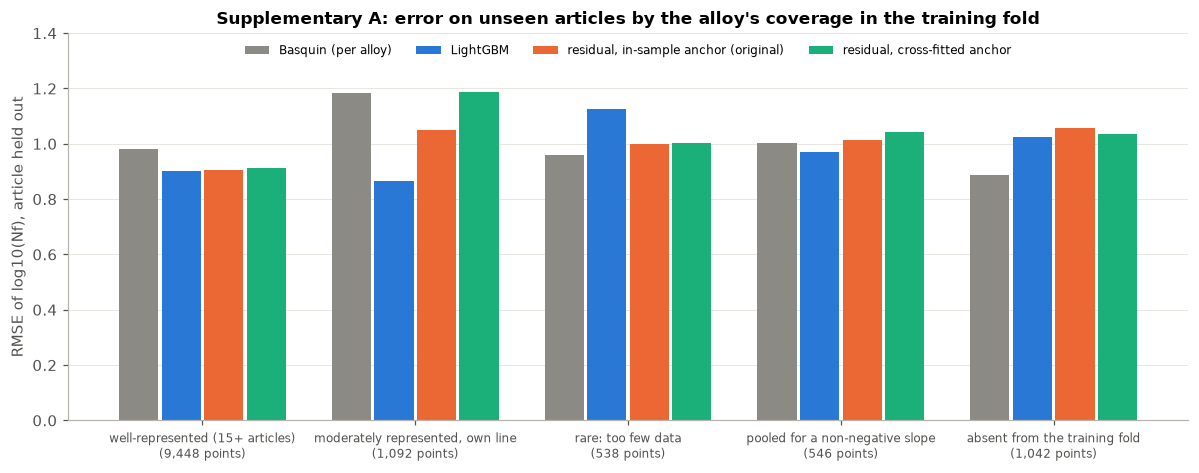

In [24]:
crossfit = pd.read_csv(PRED_DIR / "oof_predictions_crossfitted_residual.csv")
residual_targets = pd.read_csv(METRICS_DIR / "investigation_A_residual_targets.csv")
A_MODELS = ["LightGBM", "BasquinResidual", "BasquinResidualCrossFitted"]
A_LABELS = {"LightGBM": "LightGBM", "BasquinResidual": "residual, in-sample anchor (original)", "BasquinResidualCrossFitted": "residual, cross-fitted anchor"}
seed42 = pd.concat([primary[primary["model"].isin(["Basquin", "LightGBM", "BasquinResidual"])].drop(columns="basquin_pooled_fallback"),
                    crossfit[crossfit["seed"] == SEED].drop(columns="basquin_pooled_fallback")], ignore_index=True)

print("What the corrector learns from (outer training rows, article held out, seed 42):")
display(residual_targets)

# (1) RMSE, MAE and inflation, seed 42
a_metrics = eu.metrics_table(seed42[seed42["model"].isin(A_MODELS)])
a_table = a_metrics.pivot_table(index="model", columns="scheme", values=["rmse", "mae"])[[("rmse", s) for s in SCHEMES] + [("mae", s) for s in SCHEMES]].loc[A_MODELS]
a_table[("inflation", "B/A")] = a_table[("rmse", "B_curve")] / a_table[("rmse", "A_random")]
a_table[("inflation", "C/A")] = a_table[("rmse", "C_article")] / a_table[("rmse", "A_random")]
a_table.index = [A_LABELS[m] for m in a_table.index]
a_table.to_csv(METRICS_DIR / "investigation_A_metrics.csv")
display(a_table)

# (2) Paired article-bootstrap differences, every scheme
a_boot, a_summary = eu.cluster_bootstrap_rmse(seed42[seed42["model"].isin(A_MODELS)], n_boot=N_BOOT, seed=0)
a_rmse = a_metrics.set_index(["model", "scheme"])["rmse"]
pair_rows = []
for scheme in SCHEMES:
    for first, second in [("BasquinResidualCrossFitted", "LightGBM"), ("BasquinResidualCrossFitted", "BasquinResidual"), ("BasquinResidual", "LightGBM")]:
        d = eu.bootstrap_difference(a_boot, (first, scheme), (second, scheme))
        pair_rows.append({"scheme": scheme, "comparison": f"{A_LABELS[first]} minus {A_LABELS[second]}",
                          "difference in RMSE": a_rmse[(first, scheme)] - a_rmse[(second, scheme)], "95% CI low": d["ci_low"], "95% CI high": d["ci_high"],
                          "share of resamples where the first is lower": d["share_of_resamples_first_is_lower"]})
a_pairs = pd.DataFrame(pair_rows)
a_pairs.to_csv(METRICS_DIR / "investigation_A_paired_differences.csv", index=False)
display(a_pairs)
a_inflation = a_summary[(a_summary["quantity"] == "inflation_vs_random") & (a_summary["scheme"] == "C_article")].set_index("model").loc[A_MODELS]
cf_ratio = a_boot[("BasquinResidualCrossFitted", "C_article")] / a_boot[("BasquinResidualCrossFitted", "A_random")]
lg_ratio = a_boot[("LightGBM", "C_article")] / a_boot[("LightGBM", "A_random")]
print("Inflation C/A with 95% interval:", {A_LABELS[m]: f"{r['estimate']:.3f} [{r['ci_low']:.3f}, {r['ci_high']:.3f}]" for m, r in a_inflation.iterrows()})
print(f"Share of resamples where the cross-fitted hybrid has a smaller inflation than LightGBM: {float((cf_ratio < lg_ratio).mean()):.3f}")

# (3) Three seeds, article held out
all_seeds = pd.concat([primary, extra_seeds, crossfit], ignore_index=True)
a_seeds = (eu.metrics_table(all_seeds[all_seeds["model"].isin(A_MODELS)], by=("model", "scheme", "seed"))
           .pivot_table(index="seed", columns=["scheme", "model"], values="rmse"))
a_seed_table = pd.DataFrame({f"{A_LABELS[m]}, {s}": a_seeds[(s, m)] for s in ["A_random", "C_article"] for m in A_MODELS})
a_seed_table["cross-fitted minus LightGBM, C"] = a_seeds[("C_article", "BasquinResidualCrossFitted")] - a_seeds[("C_article", "LightGBM")]
a_seed_table["cross-fitted minus original, C"] = a_seeds[("C_article", "BasquinResidualCrossFitted")] - a_seeds[("C_article", "BasquinResidual")]
a_seed_table.to_csv(METRICS_DIR / "investigation_A_by_seed.csv")
display(a_seed_table)

# (4) By alloy coverage under experiment C (seed 42)
coverage_reason = pd.Series(np.select(
    [reason.eq("own line") & reason.index.isin(data.loc[data["alloy"].isin(WELL_REPRESENTED), "row_id"]),
     reason.eq("own line"), reason.eq("pooled (too few points or curves)") | reason.eq("pooled (single stress level)"),
     reason.eq("pooled (slope not negative)")],
    ["1 well-represented (15+ articles)", "2 moderately represented, own line", "3 rare: too few data", "4 pooled for a non-negative slope"],
    default="5 absent from the training fold"), index=reason.index)
c42 = seed42[seed42["scheme"] == "C_article"].assign(group=lambda t: t["row_id"].map(coverage_reason), sq=lambda t: (t["y_pred"] - t["y_true"]) ** 2)
a_cov = (c42[c42["model"] == "Basquin"].groupby("group").agg(points=("row_id", "size"), articles=("article_id", "nunique"), alloys=("alloy", "nunique"))
         .join(c42.groupby(["group", "model"])["sq"].mean().pow(0.5).unstack("model")[["Basquin"] + A_MODELS]))
for first, second, label in [("BasquinResidualCrossFitted", "LightGBM", "cross-fitted minus LightGBM"), ("BasquinResidualCrossFitted", "BasquinResidual", "cross-fitted minus original")]:
    lows, highs = [], []
    for group in a_cov.index:
        sub = c42[(c42["group"] == group) & c42["model"].isin([first, second])]
        samples, _ = eu.cluster_bootstrap_rmse(sub, n_boot=N_BOOT, seed=0)
        d = eu.bootstrap_difference(samples, (first, "C_article"), (second, "C_article"))
        lows.append(d["ci_low"]); highs.append(d["ci_high"])
    a_cov[label] = a_cov[first] - a_cov[second]
    a_cov[f"{label}, 95% CI"] = [f"{lo:+.3f} to {hi:+.3f}" for lo, hi in zip(lows, highs)]
a_cov = a_cov.rename(columns={m: f"RMSE {A_LABELS.get(m, 'Basquin')}" for m in ["Basquin"] + A_MODELS})
a_cov.to_csv(METRICS_DIR / "investigation_A_by_alloy_coverage.csv")
display(a_cov)

# (5) Outer folds, article held out (seed 42)
a_fold = c42.groupby(["fold", "model"]).agg(rmse=("sq", lambda s: float(np.sqrt(s.mean())))).unstack("model")["rmse"][["Basquin"] + A_MODELS]
a_fold.columns = [A_LABELS.get(m, "Basquin") for m in a_fold.columns]
a_fold["points"] = c42[c42["model"] == "LightGBM"].groupby("fold").size()
a_fold["cross-fitted minus LightGBM"] = a_fold[A_LABELS["BasquinResidualCrossFitted"]] - a_fold["LightGBM"]
a_fold["cross-fitted minus original"] = a_fold[A_LABELS["BasquinResidualCrossFitted"]] - a_fold[A_LABELS["BasquinResidual"]]
a_fold.to_csv(METRICS_DIR / "investigation_A_by_fold.csv")
display(a_fold)

fig, ax = plt.subplots(figsize=(11, 4.4))
groups = list(a_cov.index)
width = 0.2
for j, (model, colour) in enumerate(zip(["Basquin"] + A_MODELS, ["#8c8a84", eu.PALETTE[0], eu.PALETTE[1], eu.PALETTE[2]])):
    values = a_cov[f"RMSE {A_LABELS.get(model, 'Basquin')}"].to_numpy()
    ax.bar(np.arange(len(groups)) + (j - 1.5) * width, values, width=width * 0.92, color=colour, label=A_LABELS.get(model, "Basquin (per alloy)"))
ax.set_xticks(np.arange(len(groups)), [f"{g[2:]}\n({int(n):,} points)" for g, n in zip(groups, a_cov["points"])], fontsize=8)
ax.set(ylabel="RMSE of log10(Nf), article held out", title="Supplementary A: error on unseen articles by the alloy's coverage in the training fold", ylim=(0, 1.4))
ax.legend(fontsize=8, ncol=4, loc="upper center")
ax.grid(axis="x", visible=False)
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "04_investigation_A_by_alloy_coverage.png")
plt.show()

*Note:* the cross-fitted hybrid is worse than both the original hybrid and LightGBM, so the H2 verdict does not depend on how the anchor residuals are formed.

### 11.8 Supplementary investigation B: VHCF and test regimes

Build test regimes from the original test descriptions, then compare the one-feature-at-a-time models, the retrained dataset variants and the errors by test regime. Machine names are used only to check the categories, never as inputs.

Test regimes from the original descriptions:


,points,curves,articles,force,strain,displacement,frequency_recorded,lowest_Hz,highest_Hz,median_log_N,share_below_1e6
test regime,,,,,,,,,,,
1 ultrasonic (15 kHz or above),813,79,27,0,0,813,1.000,19000.000,20500.000,7.048,0.262
"2 VHCF-tagged, not ultrasonic",57,8,4,0,0,57,0.316,20.000,20.000,7.007,0.368
3 resonance-tagged,664,65,16,664,0,0,0.913,50.000,166.000,5.471,0.755
4 rotating bending,1506,194,52,1506,0,0,0.863,6.000,200.000,5.328,0.749
"5 plane bending (3-point, 4-point, generic)",1021,156,41,979,42,0,0.853,5.000,110.000,5.191,0.874
"6 conventional axial (untagged, below 1 kHz or not recorded)",8605,1031,311,7942,643,20,0.807,0.200,200.000,5.134,0.856


Test-type strings in each regime:


test regime,1 ultrasonic (15 kHz or above),"2 VHCF-tagged, not ultrasonic",3 resonance-tagged,4 rotating bending,"5 plane bending (3-point, 4-point, generic)","6 conventional axial (untagged, below 1 kHz or not recorded)"
test_type_raw,,,,,,
3-point bending,0,0,0,0,111,0
4-point bending,0,0,0,0,155,0
bending fatigue,0,0,0,0,755,0
bending fatigue; VHCF,46,0,0,0,0,0
bending fatigue; resonance,0,0,36,0,0,0
rotating bending fatigue,0,0,0,1506,0,0
uniaxial,0,0,0,0,0,8598
uniaxial; VHCF,767,57,0,0,0,0
uniaxial; compression,0,0,0,0,0,7


How complete the labels are (machine names checked for this table only):


,points,curves
resonance tag present,664,65
"resonance machine named, but no resonance tag",678,86
recorded frequency of 15 kHz or above,813,79
"ultrasonic machine named, frequency below 15 kHz or missing",18,4
VHCF tag without an ultrasonic frequency,57,8


... (7 outputs left out)

LightGBM, article held out, by test regime:


,"RMSE, tier 0 (primary)","RMSE, tier 0 + VHCF tag","RMSE, tier 0 + frequency","mean error, tier 0 (primary)","mean error, tier 0 + VHCF tag","mean error, tier 0 + frequency",points,articles
test regime,,,,,,,,
1 ultrasonic (15 kHz or above),1.637,1.246,1.348,-0.934,0.017,-0.093,813,27
"2 VHCF-tagged, not ultrasonic",0.891,1.131,1.970,0.035,0.374,-1.382,57,4
3 resonance-tagged,0.821,0.795,0.723,-0.260,-0.360,-0.092,664,16
4 rotating bending,0.938,0.917,0.949,-0.077,-0.073,-0.088,1506,52
"5 plane bending (3-point, 4-point, generic)",0.782,0.801,0.723,-0.000,-0.012,0.024,1021,41
"6 conventional axial (untagged, below 1 kHz or not recorded)",0.848,0.792,0.802,0.096,-0.005,0.024,8605,311


Calibration on unseen articles:


,feature set,calibration slope,points predicted above 1e7,mean error above 1e7 predicted,share of those points from ultrasonic tests
0,tier 0 (primary),0.636,303,0.611,0.551
1,tier 0 + frequency,0.703,402,0.572,0.933
2,tier 0 + VHCF tag,0.734,479,0.376,0.921


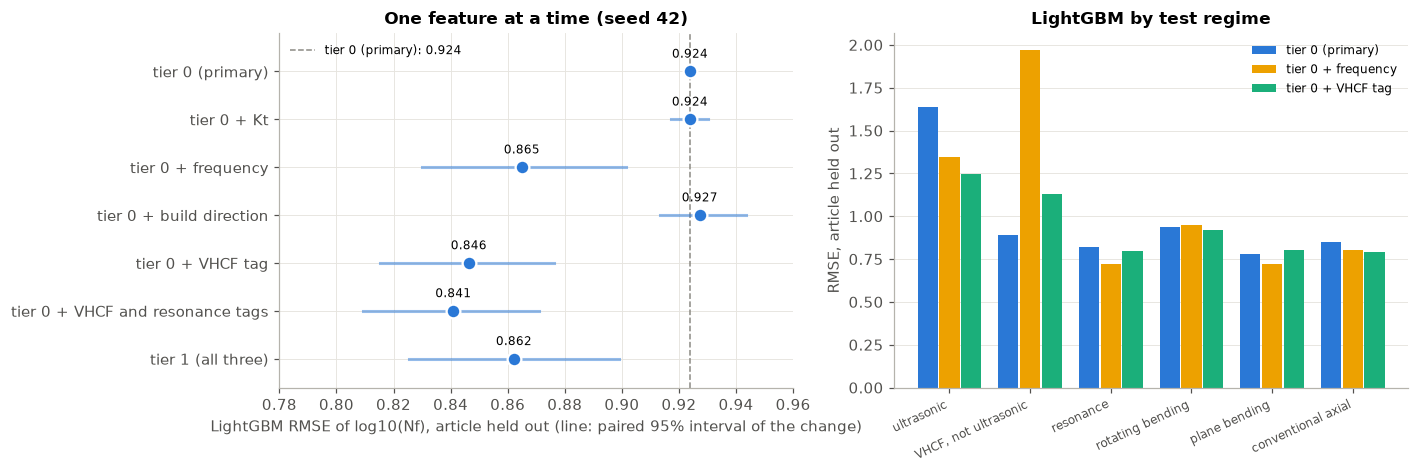

In [25]:
regimes = fu.add_test_regime_columns(data)
regimes["test regime"] = np.select(
    [regimes["ultrasonic"], regimes["vhcf_tag"].eq("VHCF"), regimes["regime_tag"].eq("resonance"),
     regimes["test_type_raw"].eq("rotating bending fatigue"), regimes["test_type_class"].eq("bending")],
    ["1 ultrasonic (15 kHz or above)", "2 VHCF-tagged, not ultrasonic", "3 resonance-tagged", "4 rotating bending", "5 plane bending (3-point, 4-point, generic)"],
    default="6 conventional axial (untagged, below 1 kHz or not recorded)")
bounds = regimes["frequency_text"].map(fu.frequency_bounds)
regimes["f_low"], regimes["f_high"] = bounds.map(lambda b: b[0]), bounds.map(lambda b: b[1])

# Part 1: the categories against the original descriptions
regime_audit = regimes.groupby("test regime").agg(
    points=("row_id", "size"), curves=("curve_id", "nunique"), articles=("article_id", "nunique"),
    force=("load_control", lambda s: int((s == "force").sum())), strain=("load_control", lambda s: int((s == "strain").sum())),
    displacement=("load_control", lambda s: int((s == "displacement").sum())),
    frequency_recorded=("f_high", lambda s: float(s.notna().mean())), lowest_Hz=("f_low", "min"), highest_Hz=("f_high", "max"),
    median_log_N=("log_N", "median"), share_below_1e6=("log_N", lambda s: float((s < 6).mean())))
regime_audit.to_csv(METRICS_DIR / "investigation_B_regime_audit.csv")
print("Test regimes from the original descriptions:")
display(regime_audit)
print("Test-type strings in each regime:")
display(pd.crosstab(regimes["test_type_raw"], regimes["test regime"]))

machine = regimes["test_machine"].astype(str)
resonance_machine = machine.str.contains("rumul|vibrophore|resonan|hfp|high frequency", case=False, regex=True)
ultrasonic_machine = machine.str.contains("ultrason|usf|lasur|oku-vienna|uft-", case=False, regex=True)
completeness = pd.DataFrame({
    "points": [int((regimes["regime_tag"].eq("resonance")).sum()), int((resonance_machine & regimes["regime_tag"].eq("none")).sum()),
               int(regimes["ultrasonic"].sum()), int((ultrasonic_machine & ~regimes["ultrasonic"]).sum()),
               int((regimes["vhcf_tag"].eq("VHCF") & ~regimes["ultrasonic"]).sum())],
    "curves": [regimes.loc[regimes["regime_tag"].eq("resonance"), "curve_id"].nunique(), regimes.loc[resonance_machine & regimes["regime_tag"].eq("none"), "curve_id"].nunique(),
               regimes.loc[regimes["ultrasonic"], "curve_id"].nunique(), regimes.loc[ultrasonic_machine & ~regimes["ultrasonic"], "curve_id"].nunique(),
               regimes.loc[regimes["vhcf_tag"].eq("VHCF") & ~regimes["ultrasonic"], "curve_id"].nunique()],
}, index=["resonance tag present", "resonance machine named, but no resonance tag", "recorded frequency of 15 kHz or above",
          "ultrasonic machine named, frequency below 15 kHz or missing", "VHCF tag without an ultrasonic frequency"])
completeness.to_csv(METRICS_DIR / "investigation_B_label_completeness.csv")
print("How complete the labels are (machine names checked for this table only):")
display(completeness)
print("Machine names of VHCF-tagged curves without an ultrasonic frequency:",
      regimes[regimes["vhcf_tag"].eq("VHCF") & ~regimes["ultrasonic"]].drop_duplicates("curve_id")["test_machine"].fillna("(not recorded)").value_counts().to_dict())

# Part 3: one feature at a time
ablation = pd.read_csv(PRED_DIR / "oof_predictions_ablation.csv")
B_SETS = ["tier 0 (primary)", "tier 0 + Kt", "tier 0 + frequency", "tier 0 + build direction", "tier 0 + VHCF tag", "tier 0 + VHCF and resonance tags"]
base = primary[primary["model"].isin(["Ridge", "LightGBM"])].assign(feature_set="tier 0 (primary)")
all_sets = pd.concat([base, ablation[ablation["seed"] == SEED], tier1[tier1["model"].isin(["Ridge", "LightGBM"])].assign(feature_set="tier 1 (all three)")], ignore_index=True)
abl_rows = []
for (model, feature_set), group in all_sets.groupby(["model", "feature_set"]):
    r = eu.rmse_pivot(group.assign(model="m"), ["m"], SCHEMES).loc["m"]
    row = {"model": model, "feature set": feature_set, "RMSE random": r["A_random"], "RMSE curve held out": r["B_curve"], "RMSE article held out": r["C_article"],
           "inflation C/A": r["C_article"] / r["A_random"]}
    if feature_set != "tier 0 (primary)":
        pair = pd.concat([group.assign(model="with"), base[base["model"] == model].assign(model="tier0")], ignore_index=True)
        samples, _ = eu.cluster_bootstrap_rmse(pair[pair["scheme"] == "C_article"], n_boot=N_BOOT, seed=0)
        d = eu.bootstrap_difference(samples, ("with", "C_article"), ("tier0", "C_article"))
        row.update({"change in article-held-out RMSE vs tier 0": r["C_article"] - eu.rmse_pivot(base[base["model"] == model], [model], SCHEMES).loc[model, "C_article"],
                    "95% CI low": d["ci_low"], "95% CI high": d["ci_high"]})
    abl_rows.append(row)
b_ablation = pd.DataFrame(abl_rows)
b_ablation["order"] = b_ablation["feature set"].map({s: i for i, s in enumerate(B_SETS + ["tier 1 (all three)"])})
b_ablation = b_ablation.sort_values(["model", "order"]).drop(columns="order").reset_index(drop=True)
b_ablation.to_csv(METRICS_DIR / "investigation_B_ablation.csv", index=False)
print("One feature at a time (seed 42; paired article-bootstrap interval of the change on unseen articles):")
display(b_ablation)

seed_rows = []
lgb_tier0 = pd.concat([primary, extra_seeds], ignore_index=True)
for seed in [SEED] + sorted(int(s) for s in extra_seeds["seed"].unique()):
    t0 = eu.rmse_pivot(lgb_tier0[(lgb_tier0["model"] == "LightGBM") & (lgb_tier0["seed"] == seed)], ["LightGBM"], SCHEMES).loc["LightGBM", "C_article"]
    row = {"seed": seed, "tier 0 (primary)": t0}
    for feature_set in B_SETS[1:]:
        sub = ablation[(ablation["model"] == "LightGBM") & (ablation["seed"] == seed) & (ablation["feature_set"] == feature_set) & (ablation["scheme"] == "C_article")]
        row[f"{feature_set}, change"] = float(np.sqrt(np.mean((sub["y_pred"] - sub["y_true"]) ** 2))) - t0
    seed_rows.append(row)
b_seeds = pd.DataFrame(seed_rows).set_index("seed")
b_seeds.to_csv(METRICS_DIR / "investigation_B_ablation_by_seed.csv")
print("LightGBM, article held out: change in RMSE against tier 0, by seed:")
display(b_seeds)

# Part 4: dataset variants
variants = pd.read_csv(PRED_DIR / "oof_predictions_regime_subsets.csv")
var_rows = []
for (variant, model), group in variants.groupby(["dataset_variant", "model"]):
    rows_kept = set(group["row_id"])
    scored = primary[(primary["model"] == model) & primary["row_id"].isin(rows_kept)]
    retrained = eu.rmse_pivot(group.assign(model="m"), ["m"], SCHEMES).loc["m"]
    scored_only = eu.rmse_pivot(scored.assign(model="m"), ["m"], SCHEMES).loc["m"]
    pair = pd.concat([group.assign(model="retrained"), scored.assign(model="primary")], ignore_index=True)
    samples, _ = eu.cluster_bootstrap_rmse(pair[pair["scheme"] == "C_article"], n_boot=N_BOOT, seed=0)
    d = eu.bootstrap_difference(samples, ("retrained", "C_article"), ("primary", "C_article"))
    var_rows.append({"dataset variant": variant, "model": model, "points": group["row_id"].nunique(), "articles": group["article_id"].nunique(),
                     "retrained: RMSE random": retrained["A_random"], "retrained: RMSE curve held out": retrained["B_curve"], "retrained: RMSE article held out": retrained["C_article"],
                     "retrained: inflation C/A": retrained["C_article"] / retrained["A_random"],
                     "primary model scored on these rows: RMSE random": scored_only["A_random"], "primary model scored on these rows: RMSE article held out": scored_only["C_article"],
                     "primary model scored on these rows: inflation C/A": scored_only["C_article"] / scored_only["A_random"],
                     "retrained minus primary, article held out": retrained["C_article"] - scored_only["C_article"], "95% CI low": d["ci_low"], "95% CI high": d["ci_high"]})
full_rows = {"Ridge": eu.rmse_pivot(primary, ["Ridge"], SCHEMES).loc["Ridge"], "LightGBM": eu.rmse_pivot(primary, ["LightGBM"], SCHEMES).loc["LightGBM"]}
for model, r in full_rows.items():
    var_rows.append({"dataset variant": "full primary dataset", "model": model, "points": len(data), "articles": data["article_id"].nunique(),
                     "retrained: RMSE random": r["A_random"], "retrained: RMSE curve held out": r["B_curve"], "retrained: RMSE article held out": r["C_article"],
                     "retrained: inflation C/A": r["C_article"] / r["A_random"]})
b_variants = pd.DataFrame(var_rows).sort_values(["model", "dataset variant"]).reset_index(drop=True)
b_variants.to_csv(METRICS_DIR / "investigation_B_variants.csv", index=False)
print("Dataset variants (tier 0, seed 42):")
display(b_variants)

# Part 5: subgroup errors and calibration, article held out, LightGBM
lgb_sets = {"tier 0 (primary)": primary[(primary["model"] == "LightGBM") & (primary["scheme"] == "C_article")]}
for feature_set in ["tier 0 + frequency", "tier 0 + VHCF tag"]:
    lgb_sets[feature_set] = ablation[(ablation["model"] == "LightGBM") & (ablation["seed"] == SEED) & (ablation["feature_set"] == feature_set) & (ablation["scheme"] == "C_article")]
regime_of = regimes.set_index("row_id")["test regime"]
sub_rows, cal_rows = [], []
for feature_set, frame in lgb_sets.items():
    e = frame.assign(regime=frame["row_id"].map(regime_of), error=frame["y_pred"] - frame["y_true"])
    for regime, g in e.groupby("regime"):
        sub_rows.append({"feature set": feature_set, "test regime": regime, "points": len(g), "articles": g["article_id"].nunique(),
                         "RMSE": float(np.sqrt(np.mean(g["error"] ** 2))), "mean error": float(g["error"].mean())})
    slope = np.polyfit(frame["y_pred"], frame["y_true"], 1)[0]
    top = frame[frame["y_pred"] > 7]
    cal_rows.append({"feature set": feature_set, "calibration slope": float(slope), "points predicted above 1e7": len(top),
                     "mean error above 1e7 predicted": float((top["y_pred"] - top["y_true"]).mean()),
                     "share of those points from ultrasonic tests": float(top["row_id"].map(regime_of).eq("1 ultrasonic (15 kHz or above)").mean())})
b_subgroups = pd.DataFrame(sub_rows)
b_subgroups.to_csv(METRICS_DIR / "investigation_B_subgroups.csv", index=False)
b_calibration = pd.DataFrame(cal_rows)
b_calibration.to_csv(METRICS_DIR / "investigation_B_calibration.csv", index=False)
print("LightGBM, article held out, by test regime:")
subgroup_view = b_subgroups.pivot(index="test regime", columns="feature set", values=["RMSE", "mean error"])
subgroup_view.columns = [f"{a}, {b}" for a, b in subgroup_view.columns]
display(subgroup_view.join(b_subgroups.drop_duplicates("test regime").set_index("test regime")[["points", "articles"]]))
print("Calibration on unseen articles:")
display(b_calibration)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
lg = b_ablation[b_ablation["model"] == "LightGBM"].reset_index(drop=True)
positions = np.arange(len(lg))[::-1]
reference = float(lg.loc[lg["feature set"] == "tier 0 (primary)", "RMSE article held out"].iloc[0])
axes[0].axvline(reference, color="#8c8a84", lw=1, ls="--", label=f"tier 0 (primary): {reference:.3f}")
for y, (_, r) in zip(positions, lg.iterrows()):
    if pd.notna(r.get("95% CI low")):
        axes[0].plot([reference + r["95% CI low"], reference + r["95% CI high"]], [y, y], color=eu.PALETTE[0], lw=2, alpha=0.5)
    axes[0].plot(r["RMSE article held out"], y, "o", ms=9, color=eu.PALETTE[0], mec="white", mew=1.5)
    axes[0].annotate(f"{r['RMSE article held out']:.3f}", (r["RMSE article held out"], y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)
axes[0].set_yticks(positions, lg["feature set"])
axes[0].set(xlabel="LightGBM RMSE of log10(Nf), article held out (line: paired 95% interval of the change)", xlim=(0.78, 0.96), title="One feature at a time (seed 42)")
axes[0].set_ylim(-0.6, len(lg) - 0.2)
axes[0].legend(fontsize=8, loc="upper left")
pivot = b_subgroups.pivot(index="test regime", columns="feature set", values="RMSE")[["tier 0 (primary)", "tier 0 + frequency", "tier 0 + VHCF tag"]]
x = np.arange(len(pivot))
for j, (column, colour) in enumerate(zip(pivot.columns, [eu.PALETTE[0], eu.PALETTE[3], eu.PALETTE[2]])):
    axes[1].bar(x + (j - 1) * 0.27, pivot[column], width=0.25, color=colour, label=column)
short = {"ultrasonic": "ultrasonic", "VHCF-tagged, not ultrasonic": "VHCF, not ultrasonic", "resonance-tagged": "resonance", "rotating bending": "rotating bending",
         "plane bending": "plane bending", "conventional axial": "conventional axial"}
axes[1].set_xticks(x, [short.get(r[2:].split(" (")[0], r[2:]) for r in pivot.index], rotation=25, ha="right", fontsize=8)
axes[1].set(ylabel="RMSE, article held out", title="LightGBM by test regime")
axes[1].legend(fontsize=8)
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
eu.save_figure(fig, FIG_DIR / "04_investigation_B_ablation_and_regimes.png")
plt.show()

*Note:* the tier-1 gain comes mainly from frequency identifying ultrasonic tests. The VHCF tag, known before the test, lowers the article-held-out error by about 0.08 without raising the inflation, and the main inflation finding does not depend on these tests.

## 12. Engineering interpretation

- A model trained on this literature database and checked with random splits looks much better than it is. For a new article the median single error is a factor of about 3.3 in life (2.3 under random validation).
- For a new source the best models are only about 7% better than predicting the average life.
- Between a third and a half of the error on a new article is a shift of the whole article that the features cannot explain. Likely sources (defects, surface condition, machine, specimen design) were not tested.
- The model can at most support coarse screening and test planning on laboratory coupons. It must not be used for specific parts, to replace testing or to derive design allowables.
- A per-alloy Basquin anchor did not help, because the Basquin line itself does not transfer to new sources.
- A test-regime label (the VHCF tag) removes the large under-prediction of ultrasonic tests.
- Models trained on literature data should be validated with whole sources held out.

## 13. Limitations

- Data are digitised from published figures, and defaults (25 °C, Kt = 1, NHT, as-built) were filled in for unreported conditions, so the cohort is a nominal room-temperature cohort.
- There are no defect, porosity or roughness data, which caps the achievable accuracy.
- Run-outs are excluded from the primary analysis (1,851 in the S-N sheet, 1,748 in the cohort); the inflation itself is unaffected (S5).
- Hyperparameters are fixed (no tuning), and the bootstrap intervals do not include refitting or fold-assignment variability.
- Bending and axial tests and different test regimes are pooled, and specimen geometry differs between sources.
- Article-held-out is not laboratory-held-out, and re-published curves make the article-held-out error slightly optimistic (S1).
- The supplementary analyses were defined after the primary result and are exploratory.
- Per-alloy results are given only for five alloys, and alloy names are used as written.
- One database and laboratory coupons only; the earlier studies' models were not re-run.

The full list of limitations is written to `reports/results_report.md` (section 9) by the report cell below. This study cannot establish that any model is fit for certification, that a process parameter causes a change in fatigue life, or how a model performs in a new laboratory.

## 14. Results report

Collect the result tables and write `reports/results_report.md`. All tables come from the variables computed above.

In [26]:
# Tables used by the report.
report_metrics = metrics[["scheme", "model", "rmse", "mae", "r2", "within_0.3", "within_0.5"]].astype({"scheme": str, "model": str}).copy()
report_metrics["scheme"] = report_metrics["scheme"].map(eu.SCHEME_LABELS)
report_metrics["model"] = report_metrics["model"].map(lambda m: mu.MODEL_LABELS.get(m, "Mean predictor (reference)"))
report_metrics = report_metrics.rename(columns={"rmse": "RMSE", "mae": "MAE", "r2": "R²", "within_0.3": "within ±0.3", "within_0.5": "within ±0.5"})

rmse_ci_table = rmse_ci.copy()
report_inflation = pd.DataFrame({
    "model": [mu.MODEL_LABELS[m] for m in MODELS],
    "RMSE random [95% CI]": rmse_ci_table["A_random"].values,
    "RMSE curve held out [95% CI]": rmse_ci_table["B_curve"].values,
    "RMSE article held out [95% CI]": rmse_ci_table["C_article"].values,
    "inflation B/A [95% CI]": inflation_ci["B_curve"].values,
    "inflation C/A [95% CI]": inflation_ci["C_article"].values,
})

report_alloys = alloy_view(MAIN_MODEL).reset_index().rename(columns={"A_random": "RMSE random", "B_curve": "RMSE curve held out", "C_article": "RMSE article held out", "target_std": "std of log10(N)"})
report_alloys["Basquin, article held out"] = alloy_view("Basquin")["C_article"].values
report_quantiles = error_quantiles[error_quantiles["model"].isin(["MeanPredictor", "Basquin", "RandomForest", "LightGBM"]) & error_quantiles["scheme"].isin(["A_random", "C_article"])].copy()
report_quantiles["scheme"] = report_quantiles["scheme"].astype(str).map(eu.SCHEME_LABELS)
report_quantiles["model"] = report_quantiles["model"].astype(str).map(lambda m: mu.MODEL_LABELS.get(m, "Mean predictor (reference)"))
report_quantiles = report_quantiles[["scheme", "model", "rmse", "10^rmse", "median abs error", "factor at median", "factor at 75th percentile", "factor at 90th percentile", "share off by more than a factor of 10"]]
report_decomposition = decomposition[decomposition["model"] == MAIN_MODEL][["scheme", "article offset %", "curve offset within article %", "scatter within curve %",
                                                                           "article offset %, noise-corrected", "article offset %, article-weighted"]].copy()
report_decomposition["scheme"] = report_decomposition["scheme"].map(eu.SCHEME_LABELS)
report_coverage = coverage_table[["points", "articles", "alloys", "Basquin", "LightGBM", "BasquinResidual", "residual minus LightGBM", "95% CI low", "95% CI high"]].reset_index().rename(
    columns={"index": "alloy group under C", "group": "alloy group under C", "Basquin": "Basquin RMSE", "LightGBM": "LightGBM RMSE", "BasquinResidual": "residual model RMSE"})
report_directions = directions[directions["model"] == mu.MODEL_LABELS[MAIN_MODEL]][["change", "expected life", "mean shift in log10(Nf)", "share of rows with the expected sign"]]
report_s6 = s6[["points", "articles", "LightGBM RMSE random", "LightGBM RMSE article held out", "95% CI", "LightGBM inflation C/A", "inflation 95% CI"]].reset_index()
report_weighting = article_weighted[["inflation C/A, point-weighted", "inflation C/A, article-weighted"]].reset_index()
report_slopes = calibration_slopes.assign(model=calibration_slopes["model"].map(mu.MODEL_LABELS)).pivot(index="model", columns="scheme", values="calibration slope")[SCHEMES].reset_index().rename(columns=eu.SCHEME_LABELS)
report_calibration = calibration_bins[calibration_bins["model"] == MAIN_MODEL].pivot(index="predicted-life bin", columns="scheme", values=["points", "bias"])
report_calibration.columns = [f"{a}, {eu.SCHEME_LABELS[s]}" for a, s in report_calibration.columns]
report_calibration = report_calibration.reset_index()
report_reason = reason_table[["points", "articles", "alloys", "Basquin", "LightGBM", "BasquinResidual"]].reset_index().rename(
    columns={"index": "Basquin decision under C", "reason": "Basquin decision under C", "Basquin": "Basquin RMSE", "LightGBM": "LightGBM RMSE", "BasquinResidual": "residual model RMSE"})
report_paired = paired_by_model.copy()
report_gain = tier1_gain.pivot(index="row group", columns="model", values="share of the drop in squared error").join(
    tier1_gain.drop_duplicates("row group").set_index("row group")["share of rows"]).reset_index()
report_a = a_table.copy()
report_a.columns = [f"{a} {b}" for a, b in report_a.columns]
report_a = report_a.reset_index().rename(columns={"index": "model"})
report_a_pairs = a_pairs[a_pairs["scheme"] == "C_article"].drop(columns="scheme")
report_a_cov = a_cov.reset_index().rename(columns={"group": "alloy group under C"})
report_b_audit = regime_audit.reset_index()
report_b_ablation = b_ablation.copy()
report_b_variants = b_variants[["dataset variant", "model", "points", "articles", "retrained: RMSE random", "retrained: RMSE article held out", "retrained: inflation C/A",
                                "primary model scored on these rows: RMSE article held out", "retrained minus primary, article held out", "95% CI low", "95% CI high"]].copy()
report_b_subgroups = subgroup_view.join(b_subgroups.drop_duplicates("test regime").set_index("test regime")[["points", "articles"]]).reset_index()
report_b_calibration = b_calibration.copy()
report_sensitivity = sensitivity_summary.copy()
report_sensitivity["model"] = report_sensitivity["model"].map(mu.MODEL_LABELS)
report_seeds = seed_wide.loc[MODELS].reset_index()
report_seeds["model"] = report_seeds["model"].map(mu.MODEL_LABELS)

In [27]:
# The report is assembled here. Its tables come from the variables computed above, so they cannot drift from
# the results. The explanatory paragraphs (T[...]) were written after the results had been seen.
T = {}
T["investigation_B"] = """
*Supplementary; the primary feature set and results are unchanged.*

**What the descriptions show.** The test regimes were built from the original test-type, frequency and load-control strings and checked against the machine names.

- Every test recorded at 1 kHz or above is an ultrasonic test at 19–20.5 kHz (813 points, 27 articles). All are tagged VHCF and recorded as displacement-controlled.
- Displacement control is the database default for VHCF tests: 870 of its 890 points carry the tag, so load control is not independent information.
- The VHCF tag is not the same as ultrasonic (57 tagged points have no ultrasonic frequency, two curves on a servo-hydraulic machine). It is not outcome-defined (26–37% of tagged points failed below 10⁶ cycles).
- The resonance tag is incomplete: 678 untagged points ran on resonance machines.

**One feature at a time** (LightGBM, change in article-held-out RMSE against tier 0, paired 95% intervals; the same pattern for three seeds and for Ridge):

- Kt and build direction: no effect (0.000 and +0.003).
- Frequency: −0.059, almost the whole tier-1 gain, but the inflation rises to 1.44.
- VHCF tag: −0.077 (−0.109 to −0.048), with the inflation unchanged (1.36).

**Without the ultrasonic tests**, retrained LightGBM improves the remaining tests from 0.853 to 0.800 on unseen articles. The inflation stays at 1.37, so the primary generalisation finding does not depend on these tests.

**Subgroups.** Under tier 0, ultrasonic tests from unseen articles are under-predicted by 0.93 log units. The VHCF tag removes that bias, improves conventional axial tests too, and raises the calibration slope from 0.64 to 0.73.

**Interpretation.** Physical reasons for different ultrasonic lives (strain rate, self-heating, small specimens with a small stressed volume, internal crack initiation) are known from the literature but were not tested here. Tables: `results/metrics/investigation_B_*.csv`; full report: `reports/investigation_B_vhcf_test_regimes.md`.
""".strip()
T["investigation_A"] = """
*Supplementary; the primary experiment is unchanged.* The audit questioned that the hybrid's corrector learns from in-sample Basquin residuals. For the moderately represented alloys these residuals are a third smaller than the anchor's error on new sources: RMSE 0.71 in-sample against 1.05 cross-fitted, on the outer training rows. A cross-fitted version gets anchor predictions for every outer training row from Basquin lines fitted without that row's own article (five inner article-grouped folds). It was trained under the same schemes, seeds, folds and settings, with the same pooled-line fallback.

**It is worse, not better.** With articles held out it reaches 0.959, against 0.940 for the original hybrid and 0.924 for LightGBM: paired differences +0.019 (95% interval +0.007 to +0.035) against the original and +0.035 (+0.008 to +0.063) against LightGBM. It is worse for all three seeds and all five outer folds, and also under random and curve-held-out validation. Its inflation (1.38) equals LightGBM's only because it is worse under random validation too.

The loss is concentrated in the 14 moderately represented alloys (1.187, against 1.050 for the original and 0.866 for LightGBM). For alloys absent from training the cross-fitted hybrid is slightly better than the original (−0.024, interval −0.050 to +0.003), but not better than LightGBM.

H2 remains not supported, and the verdict no longer depends on the in-sample construction. *Interpretation:* the per-alloy anchor of these alloys is unstable and transfers badly (Basquin alone: 1.18), and no treatment of its residuals repairs that. Tables: `results/metrics/investigation_A_*.csv`; full report: `reports/investigation_A_cross_fitted_basquin.md`.
""".strip()
T["calibration"] = """
*Corrected in version 3.* Version 2 binned the errors by the true life and concluded that the model "regresses towards the average life". That pattern is produced by any imperfect predictor: a perfectly calibrated synthetic predictor with the same RMSE gives +1.54 below 10⁴ cycles and −1.82 above 10⁷, against +1.19 and −1.79 for LightGBM. The calibration of the predictions answers the engineering question instead: given a prediction, what is the true life? Under random validation LightGBM is well calibrated (slope 1.06; every predicted-life bin within ±0.15 log units). For unseen articles the slope falls to 0.64; the predictions are too spread out, not compressed (their standard deviation stays at 0.70). **Long predicted lives are non-conservative:** above 10⁷ predicted cycles the true life is on average 0.61 log units shorter, a factor of about 4 (303 points, 37 articles), and 0.80 and 0.92 shorter for Random Forest and the residual model. Below 10⁴ predicted cycles the predictions are conservative (true life 0.61 longer).
""".strip()
T["cohort"] = """
**What the cohort is.** The temperature filter keeps tests recorded at 15 to 35 °C. But 25 °C is also the value the dataset authors assigned when an article did not report a temperature ("we also assume that the testsing [sic] are uniaxial and conducted under an ambient environment (25 °C, air)", Data Records section), and the temperature column has no empty cell, in the workbook or in the JSON file. A reported 25 °C and a default 25 °C cannot be told apart. 98% of the modelling points (12,406 points, 425 articles) are recorded at 25 °C with no further evidence; 129 points from 4 articles are recorded at 20 or 23 °C, and 131 points from 11 articles at 25 °C in articles that also report other test temperatures. The modelling dataset is therefore a **nominal room-temperature cohort** (`results/audit/test_temperature_audit.csv`). Sensitivity S6 (section 7) checks what this means for the results.

**Run-outs.** The S-N sheet holds 1,851 run-outs (12.2% of its 15,146 points), and the funnel removes all of them at step 4. 1,748 of them belong to the nominal room-temperature cohort (12.1% of its 14,414 points); the other 103 sit on curves that steps 5 (30) and 6 (73) remove anyway (`results/audit/runout_reconciliation.csv`).
""".strip()
T["bootstrap"] = """
*What the intervals cover.* They come from resampling whole articles of the saved out-of-fold predictions; no model is refitted. They are conditional on the fitted cross-validation models, the fold assignment and the fixed hyperparameters, and they describe the uncertainty due to which articles the database contains. They do not include refitting, fold-assignment (see the seed table in section 7) or model-selection variability, so a full refit-and-resample interval would be wider.
""".strip()
T["basquin_coverage"] = """
*Added after the review; exploratory, defined after H2 had failed, intervals not corrected for multiple comparisons.* With articles held out, 16.8% of the held-out rows (2,126) use the pooled Basquin line, and 1,042 rows from 56 articles belong to 60 alloys absent from the training fold. For the five well-represented alloys (75% of the points) the residual model and LightGBM are identical (difference +0.001, 95% interval −0.010 to +0.011). Almost the whole deficit of the residual model (102% of the gap in squared error) comes from 14 moderately represented alloys that have their own Basquin line: their per-alloy lines rest on fewer than 15 articles each and transfer badly (Basquin RMSE 1.18), and the residual model inherits them (1.050 against 0.866 for LightGBM). The failure of H2 is therefore not concentrated in rare or unseen alloys but in per-alloy anchors fitted on few sources. Table: `results/metrics/error_by_alloy_coverage_C.csv`; fallback frequency: `results/metrics/basquin_fallback_frequency.csv`.
""".strip()
T["directions"] = """
*Added after the review, to test the version 1 statement that the model "captures the direction of the main effects".* For every row, one input was changed with the others kept, and the change in the prediction of the final model (fitted on all rows) was recorded. On average the expected sign appears for surface finishing, HIP and tensile mean stress. Row by row it does not hold consistently, and the mean-stress penalty is smaller at R = 0.5 than at R = 0.1, which is the wrong order. These are in-sample associations learned from published data, not causal effects. All models: `results/metrics/model_effect_directions.csv`.
""".strip()
T["question"] = """
How much does point-level random validation overstate the performance of machine-learning fatigue-life models compared with curve-held-out and source-article-held-out validation, and can a Basquin-anchored residual model reduce that degradation?

This is a study of validation reliability. It does not try to maximise accuracy.
""".strip()
T["method"] = """
- **Target.** log10 of cycles to failure, failed specimens only. Run-outs are excluded from the primary analysis and examined in a sensitivity run.
- **Models, fixed settings, no tuning.** Basquin baseline (one line per alloy when the training fold has at least 30 points from 3 curves and the slope is negative, else a pooled line); Ridge; Random Forest (300 trees); LightGBM (400 trees, learning rate 0.05); Basquin-anchored residual model (Basquin plus LightGBM trained on the training residuals).
- **Three validation schemes on identical rows, features, settings, folds (5) and seed (42).** A: random points. B: whole S-N curves held out. C: whole source articles held out (the main result).
- **Leakage control.** Imputation, scaling, encoding, Basquin coefficients and models are fitted inside each training fold. Group separation is asserted in the cross-validation code, re-checked on the saved predictions and covered by automated tests.
- **Metrics.** RMSE and MAE of log10(Nf) on out-of-fold predictions; R² and the share within ±0.3 and ±0.5 as secondary metrics. Inflation factor = RMSE(grouped) / RMSE(random). Uncertainty from a cluster bootstrap over articles of the saved out-of-fold predictions (no refitting, so the intervals are conditional on the fitted models and folds).
- **Physical checks (supplementary).** Monotonicity of predicted S-N curves and the direction of the main effects were checked on the final models, in-sample, within the tested conditions.
""".strip()
T["main_result"] = """
**Finding 1. For the flexible models, the error on unseen articles is about 40% larger than random validation shows.** LightGBM has an RMSE of 0.673 when single points are held out and 0.924 when whole articles are held out, an inflation factor of 1.37 (95% interval 1.31 to 1.44). Random Forest: 0.647 against 0.927, inflation 1.43 (1.36 to 1.50). About half of the inflation is still hidden when only curves are held out (1.17 to 1.23). With every article weighted equally instead of every point, the inflation is 1.33 (LightGBM) and 1.37 (Random Forest).

**Finding 2. On unseen articles every model is close to the mean predictor.** Always predicting the average life gives an RMSE of 0.99. The best models reach 0.92, an improvement of about 7%; under random splits the apparent improvement was 35%. R² falls from 0.54–0.58 to 0.13. Only about a third of the predictions for unseen articles are within a factor of 2 of the true life. The median single error is a factor of 3.3 in life for unseen articles against 2.3 under random splits; 10^RMSE (8.4 against 4.7) is a transformation of the RMSE, not a typical error.

**Finding 3. The Basquin baseline fitted to pooled literature data does not transfer.** Its article-held-out RMSE is 0.992, equal to the mean predictor. The learned models beat it by 0.05 to 0.07, a small margin that is nevertheless distinguishable from zero in the paired bootstrap for the three tree-based models.

**Finding 4. Simple models show almost no inflation (1.06 to 1.08) because they were never accurate.** A low inflation factor is only meaningful together with the error itself.
""".strip()
T["hypotheses"] = """
The 1.5 threshold in H1 was a stated expectation, not a pass mark. The measured inflation for the lean feature set is 1.37 to 1.43: large, robust across three seeds, but below 1.5. It reaches or exceeds 1.5 with richer feature sets and with author clusters held out (section 7).

H2 fails on both of its parts, for all three seeds and in the article-by-article comparison (the residual model is better for 49% of articles; Wilcoxon p = 0.41). The reason is visible in the main table: the anchor itself has no skill on unseen articles, so the hybrid inherits nothing transferable from it. Section 6.1 locates the deficit in alloys whose per-alloy Basquin line rests on few sources. A cross-fitted anchor (supplementary investigation A, section 7.1) is worse still (0.959 against 0.924 for LightGBM), so the verdict does not depend on the construction of the hybrid.

**Supplementary findings, labelled as such.** These are exploratory analyses added after the primary result.

- For unseen articles, long predicted lives are non-conservative (section 6.3).
- The tier-1 gain comes from test frequency identifying ultrasonic tests, not from Kt (sections 7 and 7.2).
- The VHCF tag, a label known before the test, lowers LightGBM's article-held-out error by 0.077 without raising the inflation (section 7.2).
""".strip()
T["error_sources"] = """
- **A large part of the error on unseen articles is an offset of the whole article.** For LightGBM under article-held-out validation, 48% of the squared error is a constant shift per article (standard deviation of the article mean errors 0.71 log units), 18% a shift per curve and 34% scatter within a curve. Under random validation the article share is 24%, because the model learns part of each article's offset from its other points.
- **How the shares were computed, and how robust they are.** The sum of squared out-of-fold errors splits exactly into the squared article mean errors, the squared deviations of curve means from their article mean, and the squared deviations of points from their curve mean, each summed over points. The shares are point-weighted, and the group means also contain some point scatter. Removing the expected scatter contribution gives 47%; weighting every article equally gives 36%. So between a third and a half of the error is a whole-article shift.
- **The decomposition does not identify causes.** Plausible sources of an article-level shift are the defect and porosity population, surface roughness, machine and parameter set, powder lot, specimen geometry and test rig, none of which the features describe. This study cannot say which of them matter.
- **Bagged and boosted trees reach almost the same error** (Random Forest 0.927, LightGBM 0.924; the residual model, LightGBM plus a Basquin offset, 0.940; fixed settings). This suggests the limit lies mainly in the information carried by the features, not in the choice among these algorithms; tuned or different models were not tested.
- **Calibration on unseen articles (corrected in version 3).** The predictions are too spread out, not compressed towards the average (calibration slope 0.64). Long predicted lives are non-conservative. Details and the table are in section 6.3.
- **Flexible models over-reach where an alloy is rare or absent.** For alloys absent from the training fold LightGBM's error on unseen articles is 1.02, against 0.89 for the pooled Basquin line; for alloys with too few training data, 1.13 against 0.96. For five alloys on the pooled line only because their fitted slope was not negative (546 rows, mostly 18Ni300), LightGBM is better (0.97 against 1.00). Under random validation the pooled-line rows looked the best predicted (0.61).
- **Predicted S-N curves of the tree models are not monotonic.** Over the tested stress range of each of 1,455 curves, with each curve's own conditions, the final LightGBM model's predicted life rises by more than 0.05 log units somewhere on 96% of the curves and by more than 0.2 on 43%; for one Ti-6Al-4V condition the largest single rise is 0.67 log units. This check covers the final models, in-sample, within the tested ranges only, and says nothing about accuracy.
""".strip()
T["sensitivity"] = """
- **Re-published curves (C2).** 78 near-duplicate curve pairs link 66 articles; 8.4% of the points are affected. For those points the leak is clear: RMSE 0.81 with articles held out, 0.95 once linked articles are held out together. Averaged over three seeds, the overall RMSE rises by 0.012 (LightGBM) and 0.017 (Random Forest), so the headline article-held-out error is optimistic by roughly 0.01 to 0.02. The table row above is seed 42 only.
- **Author clusters (D).** With articles sharing an author held out together, LightGBM's RMSE is 1.008, no better than the mean predictor (0.993), and the inflation is 1.50. This split is built from name matching, has one cluster of 165 articles and very unequal folds, so it is indicative only. It supports the statement that article-held-out is not laboratory-held-out.
- **Monotonic constraint (S2).** Physically consistent curves at a cost of about 0.02 in RMSE; no improvement in transfer.
- **Tier 1 features (S3).** Kt, frequency and build direction lower the error under every scheme (0.862 on unseen articles; the paired interval excludes zero for all four models) and raise the inflation to 1.46. Most of the gain on unseen articles comes from tests at 1 kHz or above and displacement-controlled tests (50–64% and 40–61% of the drop in squared error, overlapping groups), which frequency identifies; notched specimens contribute 1–6%. This is a split by rows, not a feature ablation (supplementary investigation B).
- **Static-strength features (S4).** On the subset with UTS, adding σa/UTS and UTS improves LightGBM's random-split RMSE from 0.669 to 0.580, while its article-held-out RMSE changes from 0.936 to 0.964 (paired difference +0.028, 95% interval −0.010 to +0.066); inflation 1.66. The result depends on the model: the residual model behaves like LightGBM (+0.027, −0.009 to +0.062), Random Forest does not change (−0.003, −0.036 to +0.029), and Ridge improves slightly (−0.028, −0.054 to −0.004). Random validation overstates the value of UTS for the tree models. A plausible but undemonstrated mechanism is that 82% of the distinct UTS values occur in a single article, so a reported UTS can act as a fingerprint of its source.
- **Run-outs as failures (S5).** The inflation is unchanged (1.37). Predictions for real failures get worse (0.952) and biased by +0.11 log units.
- **Test temperature (S6).** Repeating the analysis without the ambiguous 25 °C rows is impossible (4 articles would remain). Scored on the primary predictions, the 12,406 ambiguous rows reproduce the headline (RMSE 0.921 with articles held out, inflation 1.38), and the 260 rows with temperature evidence are not predicted better (1.04, 95% interval 0.85 to 1.31; 15 articles). This is weak reassurance, not proof, that the default temperatures do not distort the findings.
""".strip()
T["engineering"] = """
- A model of this kind, checked with random splits, will look much better than it is. For a new source its median single error is a factor of about 3.3 in life (2.3 under random validation), and a quarter of its predictions are off by more than a factor of 9. Written as 10^RMSE the figures are 8.4 and 4.7, but that is a transformation of the RMSE, not a typical error.
- For a new source, long predicted lives are non-conservative: above 10⁷ predicted cycles the true life is on average about four times shorter than predicted (calibration slope 0.64; section 6.3).
- For a new source the model is only slightly better than knowing the average life in the database. Its use is at most coarse screening and test planning on laboratory coupons. Averaged over the dataset it gives the expected sign to the effects of surface finishing, HIP and tensile mean stress, but not consistently for individual conditions, and these are associations learned from published data, not causal effects (section 6.2).
- It must not be used to predict the life of a specific part or supplier, to replace coupon or component testing, or to derive design allowables.
- A physics anchor helps only if the physics model itself transfers. A per-alloy Basquin line fitted to pooled literature data does not, and training the correction on cross-fitted residuals makes the hybrid worse, not better.
- A model must be told how a test was run. Ultrasonic very-high-cycle tests are under-predicted by almost a decade by a model that cannot recognise them; the database's VHCF tag, known before the test, removes that bias.
- Models trained on literature compilations should be validated with whole sources held out, reported per source, and their features chosen under that validation.
""".strip()
T["limitations"] = """
- Data are digitised from published figures; the dataset authors' quality checks were not repeated.
- Defaults were inserted for unreported conditions (25 °C, Kt = 1, NHT, as-built). Categories are labelled `..._or_unreported`. The test temperature is the default value for 98% of the cohort, which is therefore a nominal room-temperature cohort; a test at an unreported elevated temperature cannot be excluded (S6).
- No defect, porosity or roughness data: this caps the achievable accuracy.
- Bending and axial tests are mixed; specimen geometry differs between sources.
- Run-outs are excluded from the primary analysis (1,851 in the whole S-N sheet, 1,748 of them in the cohort); the long-life region is under-represented.
- One fixed set of hyperparameters; absolute errors are not optimised.
- The bootstrap intervals resample fixed out-of-fold predictions; they do not include refitting, fold-assignment or model-selection variability.
- `log_swt` is the stress-based SWT form computed from nominal stresses; it ignores plasticity and notch-root stresses.
- The monotonicity and effect-direction checks use the final models in-sample, within the tested conditions.
- Predictions for unseen articles are miscalibrated (slope 0.64); long predicted lives are non-conservative.
- The hybrid was tested in two constructions (in-sample and cross-fitted anchor); other anchors were not tried.
- Ultrasonic, resonance and displacement-controlled tests are not distinguished by the lean features; they are about 7% of the points but carry 21–25% of LightGBM's squared error. The VHCF tag fixes most of this (section 7.2), but the primary feature set was not changed. The resonance tag is incomplete, and about 18 probable ultrasonic points record no frequency. Load-, strain- and displacement-controlled tests are pooled.
- The supplementary analyses (sections 6.1, 6.3, 7.1, 7.2) were defined after the primary result was known; their intervals are not corrected for multiple comparisons.
- The generic "bending fatigue" label (755 points) is mapped to plane bending; some of these tests may be rotating or cantilever bending.
- Headline errors weight points; with articles weighted equally the inflation is slightly smaller (1.33 for LightGBM).
- Article-held-out is not laboratory-held-out: one group often publishes several articles, and some curves were published twice.
- Per-alloy figures are given only for alloys with at least 15 articles; 17-4 PH rests on 16.
- No external dataset: internal validity only.
- Laboratory coupons are not components.
- The surface and heat-treatment classes are our own coarse keyword rules.
- The models of the earlier studies were not re-run, so no statement is made about their specific numbers.

This study cannot establish that any model is fit for certification, that a process parameter causes a change in fatigue life, or how a model performs in a new laboratory.
""".strip()
T["next_steps"] = """
Unresolved issues:

1. The author-cluster split confounds a stricter held-out unit with less training data. A cleaner definition of research group (institution plus author overlap, checked by hand) and size-balanced folds are needed before H3 can be tested.
2. Near-duplicate curves were found with one tolerance (about 2% in stress, 5% in life) and only between curves with the same alloy name. The count of 78 pairs is a lower bound for re-publication; 8 more appear when alloy names may differ.
3. The share of articles giving a test standard counted from the file (26%) differs from the reported 40%; the reason is unknown.
4. Whether the result holds for the planning documents' literature comparison is untested, because those models were not reproduced.
5. Alloy names are used as written. Variants of one alloy (for example 18Ni300 and Maraging Steel, IN718 and GH4169) are separate categories; merging them needs metallurgical judgement.
6. Whether the rows recorded at 25 °C were tested at room temperature cannot be verified from the file; only the original articles can settle it.
7. The resonance tag is incomplete (678 untagged points on resonance machines), and about 18 probable ultrasonic points record no frequency; both need the original articles.
8. Why the cross-fitted anchor is worse is explained only by an untested mechanism (an unstable per-alloy anchor).

Recommended next steps, in order:

1. Nested, grouped hyperparameter tuning, to show how much of the remaining error is due to the fixed settings.
2. A censored-data model for run-outs (for example an accelerated-failure-time model) under the same three schemes.
3. A temporal split (train on earlier years, test on later ones) as an external-style check.
4. Per-article offset modelling (mixed-effects or few-shot calibration): how many points from a new source are needed to recover the lost accuracy? This is the practically useful question the present result leads to.
5. Conformal prediction intervals calibrated per held-out article, so that a screening prediction carries an honest uncertainty.
6. Permutation importance and partial dependence computed on held-out articles.
7. Before any submission: repeat the literature search for article-level validation on this database, as required by the planning documents.
8. Check the stated test temperature in a random sample of the articles recorded at 25 °C.
9. Repeated grouped cross-validation with refitting (or a refit bootstrap), to obtain intervals that include training variability.
10. For the hybrid model: a pooled anchor, or a minimum number of training articles per Basquin line. Cross-fitting the anchor alone did not help (supplementary A).
11. Pre-register a feature set that includes the VHCF tag, a pre-test label, and repeat the primary comparison with it, including calibration.
12. Reproduce the article-held-out comparison on a second, independent fatigue database, if one becomes available.
""".strip()

def table_md(frame, fmt="{:.3f}", index=True):
    return eu.df_to_markdown(frame, float_format=fmt, index=index)

funnel = pd.read_csv(AUDIT_DIR / "filter_funnel.csv")
counted = pd.read_csv(AUDIT_DIR / "counted_vs_reported.csv").head(3)

report = f"""# Results Report — FatigueData-AM2022 Generalisation Study

*Generated by `notebooks/04_Model_Evaluation_and_Research_Findings.ipynb` on {pd.Timestamp.now().strftime('%Y-%m-%d')}. Every table below is written by that notebook from the out-of-fold predictions. The explanatory text was written after the results were seen and quotes those tables.*

*Version 3. Version 2 answered an independent scientific review; version 3 closes a technical audit (`reports/technical_closure_v3.md`). The primary cohort, models and primary results are unchanged since version 1; descriptions were corrected and supplementary analyses were added. Every change is listed in `reports/CHANGELOG.md`; versions 1 and 2 are kept in `archive/`.*

## 1. Question

{T['question']}

## 2. Data actually used

Dataset: Zhang, Z. & Xu, Z., *Fatigue database of additively manufactured alloys*, Scientific Data 10:249 (2023); Figshare DOI 10.6084/m9.figshare.22337629, version 2, CC BY 4.0. Provenance and hashes: `results/audit/file_provenance.json`.

Counted from the file against the figures reported by the dataset authors:

{table_md(counted, index=False)}

Filter funnel (points, curves and articles left after each step):

{table_md(funnel[['step', 'filter', 'points', 'curves', 'articles', 'points_removed']], index=False)}

Modelling dataset: **{len(data):,} failure points, {data['curve_id'].nunique():,} S-N curves, {data['article_id'].nunique()} source articles, {data['alloy'].nunique()} alloys**. Target: log10(Nf), standard deviation {data['log_N'].std():.3f}.

{T['cohort']}

Features (tier 0, all complete): {', '.join('`' + f + '`' for f in FEATURES)}. Never used as inputs: life, the run-out flag, and every identifier. R = σmin/σmax and σa is the nominal stress amplitude in MPa, as defined in the dataset paper. `log_swt` is log10 of the stress-based Smith–Watson–Topper equivalent stress amplitude, √(σmax·σa) = σa·√(2/(1 − R)), computed from nominal stresses; it is the elastic form of the strain-based SWT parameter and a fixed function of σa and R.

## 3. Method in brief

{T['method']}

## 4. Main result

RMSE and MAE are in log10 cycles. For a single prediction, an error of 0.3 is a factor of 2 in life and 0.5 a factor of about 3. A summary metric written as a factor, such as 10^RMSE, is only a transformation of the logarithmic metric and is not the error of a typical prediction; the third table below gives the size of single errors.

{table_md(report_metrics, index=False)}

Inflation factor = RMSE under the grouped scheme divided by RMSE under random splits, same model. 95% intervals from {N_BOOT:,} bootstrap resamples of whole articles.

{table_md(report_inflation, index=False)}

{T['bootstrap']}

Size of single errors: percentiles of the absolute error of log10(Nf) and the factors in life they correspond to.

{table_md(report_quantiles, index=False)}

Robustness to weighting (version 3): inflation C/A with every point weighted equally (as above) and with every article weighted equally.

{table_md(report_weighting, index=False)}

![RMSE by model and scheme](../results/figures/04_rmse_by_model_and_scheme.png)

{T['main_result']}

## 5. Hypotheses

| Hypothesis | Verdict | Evidence |
|---|---|---|
| H1: for the best direct learner, article-held-out RMSE is at least 1.5 times the random-split RMSE | **{h1_verdict}** | {h1_evidence} |
| H2: the Basquin-anchored residual model has a smaller inflation factor and a lower article-held-out RMSE than direct gradient boosting | **{h2_verdict}** | {h2_evidence} |
| H3 (later work): author-cluster-held-out error is at least as large as article-held-out error | **{h3_verdict}** | {h3_evidence} |

{T['hypotheses']}

## 6. Where the error comes from

{T['error_sources']}

Per-alloy RMSE of {mu.MODEL_LABELS[MAIN_MODEL]} (alloys with at least 15 articles; the article count is given because it limits how far each figure can be trusted):

{table_md(report_alloys, index=False)}

Decomposition of the squared error of {mu.MODEL_LABELS[MAIN_MODEL]} (% of the sum of squared errors). Point-weighted shares; the last two columns are the robustness checks described in section 6.

{table_md(report_decomposition, fmt="{:.1f}", index=False)}

Article-held-out RMSE by the reason for the Basquin decision (version 3):

{table_md(report_reason, index=False)}

### 6.1 Supplementary: the Basquin anchor and alloy coverage

{T['basquin_coverage']}

{table_md(report_coverage, index=False)}

### 6.2 Supplementary: direction of the main effects in the fitted LightGBM model

{T['directions']}

{table_md(report_directions, index=False)}

### 6.3 Calibration of the predictions (version 3)

{T['calibration']}

Calibration slope (true log10 Nf regressed on predicted log10 Nf); 1 means well calibrated, below 1 too spread out:

{table_md(report_slopes, index=False)}

{mu.MODEL_LABELS[MAIN_MODEL]}: points and mean error (predicted minus true log10 Nf) by predicted-life bin:

{table_md(report_calibration, index=False)}

![Calibration](../results/figures/04_calibration_LightGBM.png)

## 7. Sensitivity analyses

Each run changes one choice and is compared with its like-for-like baseline. RMSE of log10(Nf), seed 42.

{table_md(report_sensitivity, index=False)}

{T['sensitivity']}

S3 and S4, paired article-bootstrap differences in article-held-out RMSE for every model (version 3; negative means the richer tier is better):

{table_md(report_paired, index=False)}

Where the tier-1 gain comes from: share of the drop in squared error (article held out) by row group; the first three groups overlap:

{table_md(report_gain, index=False)}

S6, test temperature (primary out-of-fold predictions of {mu.MODEL_LABELS[MAIN_MODEL]}, scored on rows with and without temperature evidence):

{table_md(report_s6, index=False)}

### 7.1 Supplementary investigation A: a cross-fitted Basquin anchor (version 3)

{T['investigation_A']}

RMSE and MAE of log10(Nf) and inflation (seed 42):

{table_md(report_a, index=False)}

Paired article-bootstrap differences, article held out:

{table_md(report_a_pairs, index=False)}

By the alloy's coverage in the training fold, article held out:

{table_md(report_a_cov, index=False)}

![Investigation A by alloy coverage](../results/figures/04_investigation_A_by_alloy_coverage.png)

### 7.2 Supplementary investigation B: VHCF and test-regime effects (version 3)

{T['investigation_B']}

Test regimes from the original descriptions:

{table_md(report_b_audit, index=False)}

One feature at a time (seed 42; paired article-bootstrap interval of the change on unseen articles):

{table_md(report_b_ablation, index=False)}

Dataset variants (tier 0, retrained), against the primary model scored on the same rows:

{table_md(report_b_variants, index=False)}

LightGBM on unseen articles, by test regime:

{table_md(report_b_subgroups, index=False)}

Calibration on unseen articles:

{table_md(report_b_calibration, index=False)}

![Investigation B](../results/figures/04_investigation_B_ablation_and_regimes.png)

### 7.3 Stability across seeds

Each seed sets both the fold assignment and the learners' random state (seeds 42, 43, 44), RMSE:

{table_md(report_seeds, index=False)}

## 8. What this means for an engineer

{T['engineering']}

## 9. Limitations

{T['limitations']}

## 10. Unresolved issues and recommended next steps

{T['next_steps']}

## 11. Reproducibility

- Tests: `python -m pytest tests -v` ({n_tests_passed} tests passed in the last run; report in `results/metrics/test_report.txt`).
- Seeds: 42 (primary), 43 and 44 (stability). Five folds. Fixed hyperparameters (`models/model_config.json`). No tuning.
- Fold assignments: `data/processed/folds.csv`. Out-of-fold predictions: `results/predictions/`. Metrics: `results/metrics/`.
- Run order: notebooks 01, 02, 03, 04. See `README.md`.

## 12. References

- Zhang, Z. & Xu, Z. Fatigue database of additively manufactured alloys. *Scientific Data* 10, 249 (2023). https://doi.org/10.1038/s41597-023-02150-x
- Dataset: https://doi.org/10.6084/m9.figshare.22337629
- Ahn, Lee, Tiwari & Park. *Applied Sciences* 16(13), 6493 (2026). https://doi.org/10.3390/app16136493
- Di Maggio, Gastaldi, Renzo, Delprete & Furgiuele. *Engineering with Computers* 41, 2937–2952 (2025). https://doi.org/10.1007/s00366-025-02139-7
- Alfred & Amiri. *Progress in Additive Manufacturing* 10(9), 6183–6210 (2025). https://doi.org/10.1007/s40964-025-00965-1
- Saraswat. *Energy and AI* 26, 100889 (2026).
- Kapoor & Narayanan. Leakage and the reproducibility crisis in ML-based science. *Patterns* 4(9), 100804 (2023).
- ASTM E739, Statistical analysis of linear or linearized stress-life (S-N) and strain-life (ε-N) fatigue data.

The literature entries are those collected in the project's planning documents (`FatigueAM_context_files/context/04_literature_and_gap.md`); they were not re-verified during this implementation.
"""
(REPORT_DIR / "results_report.md").write_text(report, encoding="utf8")
print(f"Wrote reports/results_report.md ({len(report.splitlines())} lines, {len(report):,} characters)")

Wrote reports/results_report.md (517 lines, 52,418 characters)


### 14.1 Figures and tables for the paper

Copy the numbered figures and tables, with a caption manifest, into `results/paper/`.

In [28]:
import shutil
PAPER_DIR = PROJECT_ROOT / "results" / "paper"
PAPER_DIR.mkdir(parents=True, exist_ok=True)
figures = [
    ("Figure_1_filter_funnel.png", "02_filter_funnel.png", "Filter funnel from the published S-N sheet to the modelling dataset (points, curves, articles after each step)."),
    ("Figure_2_rmse_by_model_and_scheme.png", "04_rmse_by_model_and_scheme.png", "Out-of-fold RMSE of log10(Nf) for each model under random-point, curve-held-out and article-held-out validation; dashed line: mean predictor."),
    ("Figure_3_inflation_factors.png", "04_inflation_factors.png", "Inflation factor (grouped RMSE / random RMSE) with 95% article-bootstrap intervals, conditional on the fitted models."),
    ("Figure_4_article_offsets.png", "04_article_offsets.png", "Distribution of article mean errors of LightGBM under random and article-held-out validation."),
    ("Figure_5_calibration.png", "04_calibration_LightGBM.png", "Calibration of LightGBM: mean true life by predicted-life bin, random against article-held-out validation."),
    ("Figure_6_test_regimes.png", "04_investigation_B_ablation_and_regimes.png", "Supplementary investigation B: one-feature-at-a-time ablation and error by test regime (article held out)."),
    ("Figure_S1_cross_fitted_anchor.png", "04_investigation_A_by_alloy_coverage.png", "Supplementary investigation A: article-held-out RMSE by the alloy's coverage in the training fold."),
    ("Figure_S2_predicted_sn_curves.png", "03_predicted_sn_curves_final_models.png", "Predicted S-N curves of the final models for one Ti-6Al-4V condition (plausibility check, in-sample)."),
    ("Figure_S3_per_alloy_rmse.png", "04_per_alloy_rmse.png", "RMSE per alloy (alloys with at least 15 articles) under the three schemes."),
]
for target, source, _ in figures:
    shutil.copyfile(FIG_DIR / source, PAPER_DIR / target)

hypothesis_rows = [
    {"hypothesis": "H1: article-held-out RMSE >= 1.5 x random-split RMSE for the best direct learner", "verdict": h1_verdict, "evidence": h1_evidence},
    {"hypothesis": "H2: the Basquin-anchored residual model has a smaller inflation and a lower article-held-out RMSE than LightGBM", "verdict": h2_verdict, "evidence": h2_evidence},
    {"hypothesis": "H2, supplementary A: the same with a cross-fitted anchor", "verdict": "not supported",
     "evidence": f"article held out {a_rmse[('BasquinResidualCrossFitted', 'C_article')]:.3f} against {a_rmse[('LightGBM', 'C_article')]:.3f} (LightGBM); inflation {a_inflation.loc['BasquinResidualCrossFitted', 'estimate']:.2f} against {a_inflation.loc['LightGBM', 'estimate']:.2f}"},
    {"hypothesis": "H3 (later work): author-cluster-held-out error >= article-held-out error", "verdict": h3_verdict, "evidence": h3_evidence},
]
tables = {
    "Table_1_filter_funnel": (pd.read_csv(AUDIT_DIR / "filter_funnel.csv"), "Filter funnel: points, curves and articles after each step."),
    "Table_2_main_results": (report_inflation, "RMSE of log10(Nf) with 95% article-bootstrap intervals, and inflation factors, by model and scheme (seed 42)."),
    "Table_3_hypotheses": (pd.DataFrame(hypothesis_rows), "Pre-stated hypotheses and their verdicts, with the supplementary test of H2."),
    "Table_4_error_size": (report_quantiles, "Size of single errors: percentiles of the absolute error and the factors in life they correspond to."),
    "Table_5_sensitivity": (report_sensitivity, "Sensitivity analyses S1-S6: RMSE under random, curve-held-out and the strictest scheme, and inflation."),
    "Table_6_ablation": (report_b_ablation, "Supplementary B: one feature at a time; change in article-held-out RMSE against tier 0 with paired 95% intervals."),
    "Table_S1_calibration": (report_calibration, "Calibration: points and mean error by predicted-life bin (LightGBM)."),
    "Table_S2_cross_fitted_anchor": (report_a_cov, "Supplementary A: article-held-out RMSE by alloy coverage for Basquin, LightGBM and both hybrids."),
    "Table_S3_test_regimes": (report_b_audit, "Supplementary B: test regimes identified from the original descriptions."),
    "Table_S4_regime_variants": (report_b_variants, "Supplementary B: models retrained without ultrasonic or displacement-controlled tests."),
}
for name, (frame, _) in tables.items():
    frame.to_csv(PAPER_DIR / f"{name}.csv", index=False)
manifest = ["# Figures and tables for a paper", "",
            "*Generated by notebook 04 (section 14.1). Primary results: Figures 1-5, Tables 1-5. Supplementary analyses are marked S, or are labelled as supplementary in their captions (Figure 6, Table 6).*", "",
            "## Figures", ""] + [f"- **{t}**: {c} (source `results/figures/{s}`)" for t, s, c in figures] + ["", "## Tables", ""] + \
           [f"- **{n}.csv**: {c}" for n, (_, c) in tables.items()]
(PAPER_DIR / "README.md").write_text("\n".join(manifest) + "\n", encoding="utf8")
print(f"Wrote {len(figures)} figures, {len(tables)} tables and README.md to results/paper/")

Wrote 9 figures, 10 tables and README.md to results/paper/


## 15. Summary of findings

1. With the lean feature set, the error on unseen articles is about 40% larger than random validation shows. LightGBM: RMSE 0.673 (random), 0.787 (curves held out), 0.924 (articles held out), inflation 1.37 (95% interval 1.31–1.44). Random Forest: 1.43 (1.36–1.50).
2. H1 (inflation ≥ 1.5) is not supported for the lean feature set. The inflation reaches 1.5 or more with richer features and with author clusters held out.
3. H2 is not supported. The residual model has a larger inflation (1.41) and a slightly higher article-held-out RMSE (0.940) than LightGBM, and a cross-fitted anchor is worse still.
4. On unseen articles all models are close to the mean predictor, and a third to a half of the error is a whole-article offset.
5. For new sources, long predicted lives are non-conservative (calibration slope 0.64).
6. The test regime (ultrasonic tests) is the largest identifiable source of avoidable error; the inflation of about 1.37 does not depend on these tests.

These results use fixed hyperparameters on one database. The models are for screening and test planning on laboratory coupons only.

## 16. Figures for the beginner's guide

Draw the five figures of `Understanding_Our_Project` from the saved results and check that they show the same RMSE values and intervals as sections 3 and 4. Figure 2 is a diagram with invented example papers, not project data.

Checked 18 RMSE values and 15 intervals against sections 3 and 4.
LightGBM RMSE of log10(Nf): random points 0.673, curves held out 0.787, articles held out 0.924 (ratio 1.37)
Wrote 10 files to results/figures/beginner/
fig1_central_finding.png


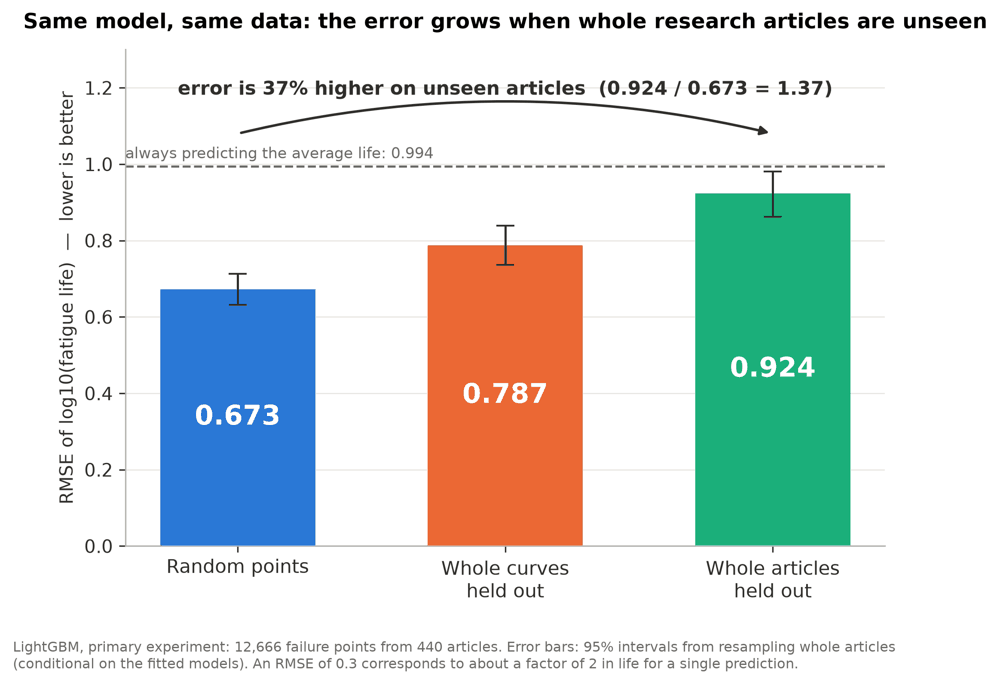

fig2_validation_strategies.png


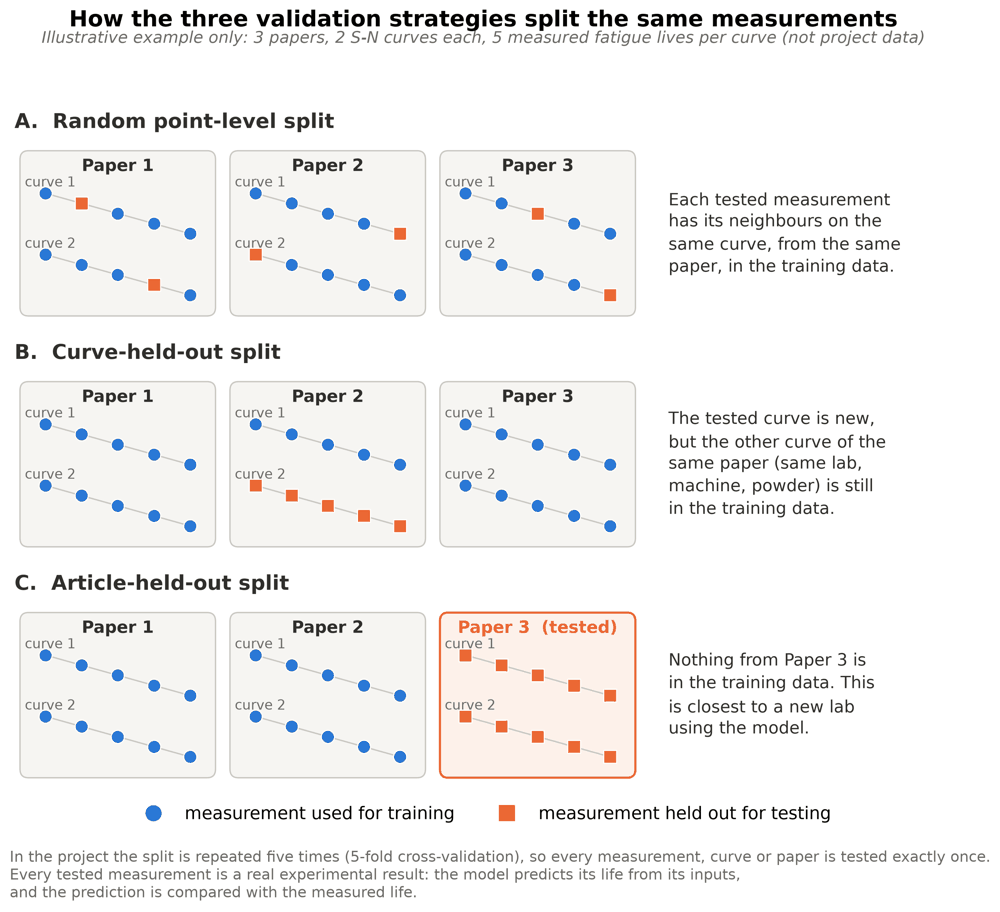

fig3_all_models.png


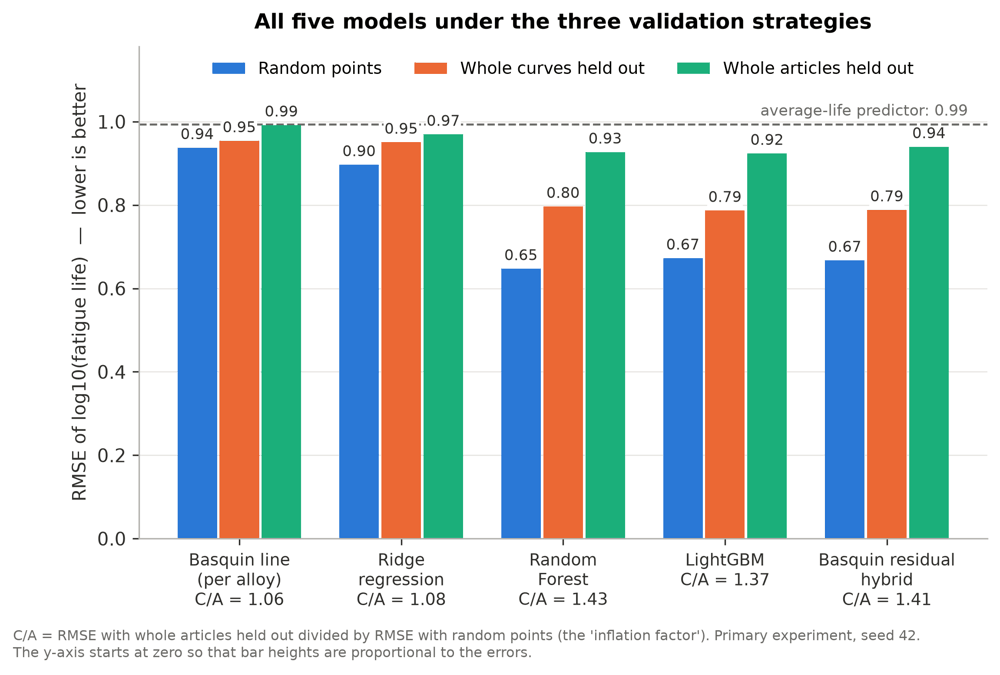

fig4_actual_vs_predicted.png


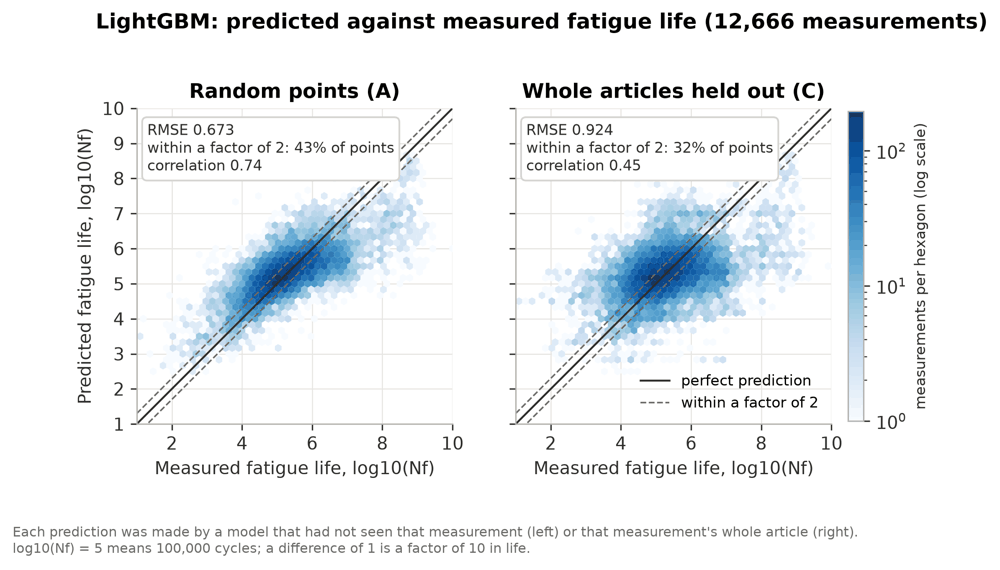

fig5_article_offsets.png


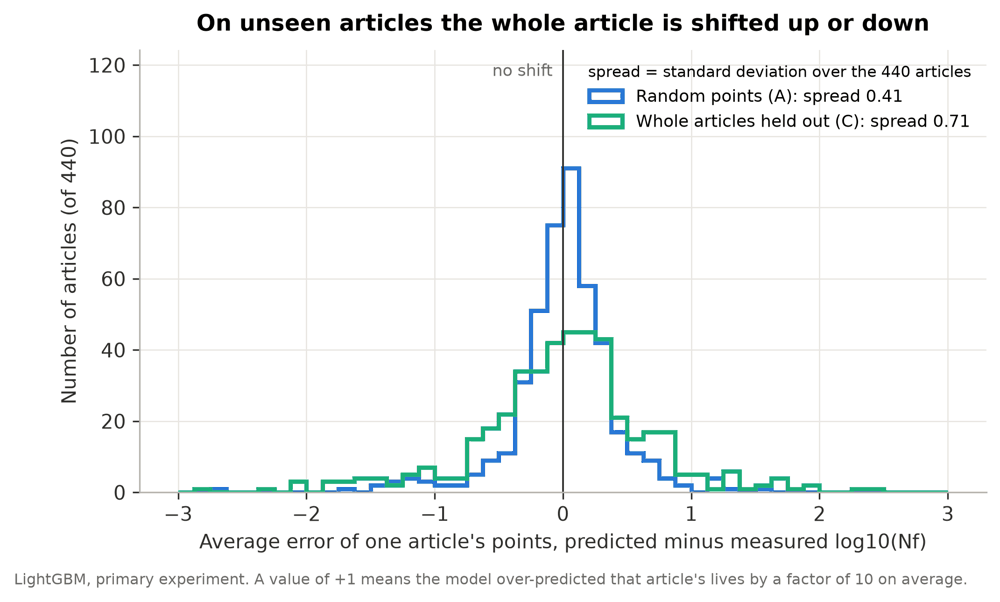

In [29]:
import io
from IPython.display import Image as ShowImage
from PIL import Image as PILImage
from visualization.beginner_figures import figure_values, load, make_all

beginner_paths = make_all(PROJECT_ROOT)

# The figures must show exactly the RMSEs (section 3) and bootstrap intervals (section 4) computed in this notebook.
shown = figure_values(load(PROJECT_ROOT))
for row in metrics.itertuples():
    assert abs(shown["rmse"][(row.model, row.scheme)] - row.rmse) < 1e-9, (row.model, row.scheme)
for row in boot_summary[boot_summary["quantity"] == "rmse"].itertuples():
    low, high = shown["ci"][(row.model, row.scheme)]
    assert abs(low - row.ci_low) < 1e-9 and abs(high - row.ci_high) < 1e-9, (row.model, row.scheme)
lgbm = {scheme: shown["rmse"][("LightGBM", scheme)] for scheme in SCHEMES}
print(f"Checked {len(metrics)} RMSE values and {int((boot_summary['quantity'] == 'rmse').sum())} intervals against sections 3 and 4.")
print(f"LightGBM RMSE of log10(Nf): random points {lgbm['A_random']:.3f}, curves held out {lgbm['B_curve']:.3f}, "
      f"articles held out {lgbm['C_article']:.3f} (ratio {lgbm['C_article'] / lgbm['A_random']:.2f})")
print(f"Wrote {len(beginner_paths)} files to {beginner_paths[0].parent.relative_to(PROJECT_ROOT).as_posix()}/")

def preview(path, max_width=1000):
    # A reduced, 128-colour copy keeps the notebook small; the full 300-dpi file is on disk.
    picture = PILImage.open(path).convert("RGB")
    picture.thumbnail((max_width, 2 * max_width))
    buffer = io.BytesIO()
    picture.quantize(colors=128, method=PILImage.Quantize.MEDIANCUT).save(buffer, format="PNG", optimize=True)
    return ShowImage(data=buffer.getvalue())

for path in beginner_paths:
    if path.suffix == ".png":
        print(path.name)
        display(preview(path))